# NLP-Political-Clarity-Prompting-Strategies
> ## Author: Ektoras Anastasios Kapellas

In [1]:
!pip install -q -U "transformers @ git+https://github.com/huggingface/transformers.git"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 668.2/668.2 kB 12.8 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.6/116.6 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 88.1 MB/s eta 0:00:00:00:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 1.25.1 requires google-cloud-bigquery-storage>=2.0.0, which is not installed.


In [2]:
!pip install -q -U bitsandbytes accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.7/60.7 MB 29.1 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 383.7/383.7 kB 23.7 MB/s eta 0:00:00


# All necessary libraries needed for the project

In [3]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_recall_fscore_support, f1_score
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
from datasets import load_dataset, ClassLabel
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import random
import pprint
import torch
import time
import re
import gc

# Set seed for reproducibility

In [4]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42) 

In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Torch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"Using device: {device}")

if torch.cuda.is_available():
    print(f"GPU name: {torch.cuda.get_device_name(0)}")

Torch version: 2.10.0+cu128
CUDA available: True
Using device: cuda
GPU name: Tesla T4


# Loading and examine the dataset

In [6]:
dataset = load_dataset("ailsntua/QEvasion")
train_data = dataset['test']
train_data = train_data.class_encode_column("clarity_label")
# num_samples = 100
num_samples = 308
stratified_subset = train_data.select(range(num_samples))

print(f"Subset size: {len(stratified_subset)}")
named_labels = train_data.features["clarity_label"].int2str(stratified_subset['clarity_label'])
print(pd.Series(named_labels).value_counts(normalize=True))

README.md:   0%|          | 0.00/12.7k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/3.90M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/259k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/3448 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/308 [00:00<?, ? examples/s]

Casting to class labels:   0%|          | 0/308 [00:00<?, ? examples/s]

Subset size: 100
Ambivalent         0.66
Clear Reply        0.25
Clear Non-Reply    0.09
Name: proportion, dtype: float64


In [7]:
clarity_feature = train_data.features["clarity_label"]

print("Classes:", clarity_feature.names)
print("-" * 40)

for i in range(clarity_feature.num_classes):
    print(f"ID {i} -> label: '{clarity_feature.int2str(i)}'")

Classes: ['Ambivalent', 'Clear Non-Reply', 'Clear Reply']
----------------------------------------
ID 0 -> label: 'Ambivalent'
ID 1 -> label: 'Clear Non-Reply'
ID 2 -> label: 'Clear Reply'


# Evaluation Metrics and Confusion Matrix

In [8]:
def calculate_metrics(results):
    id_to_label = {0: "Ambivalent", 1: "Clear Non-Reply", 2: "Clear Reply"}
    labels_order = ["Clear Reply", "Ambivalent", "Clear Non-Reply"]

    y_true = []
    y_pred = []

    for r in results:
        gold = r['gold_label']
        if isinstance(gold, int):
            gold = id_to_label.get(gold, str(gold))
        y_true.append(gold)
        
        pred = str(r['prediction']).strip()
        y_pred.append(pred)

    cm = confusion_matrix(y_true, y_pred, labels=labels_order)
    accuracy = accuracy_score(y_true, y_pred)
    
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average='weighted', labels=labels_order, zero_division=0
    )
    
    macro_f1 = f1_score(y_true, y_pred, average='macro', labels=labels_order, zero_division=0)
    
    metrics = {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "Macro F1-Score": macro_f1,
        "Confusion_Matrix": cm.tolist(), 
        "Labels": labels_order
    }

    return metrics

def plot_confusion_matrix(results, model_name="Qwen-0.8B"):
    id_to_label = {0: "Ambivalent", 1: "Clear Non-Reply", 2: "Clear Reply"}
    
    y_true = [id_to_label[r['gold_label']] if isinstance(r['gold_label'], int) else r['gold_label'] for r in results]
    y_pred = [r['prediction'] for r in results]
    labels = ["Clear Reply", "Ambivalent", "Clear Non-Reply"]
    
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=labels, yticklabels=labels)
    
    plt.title(f'Confusion Matrix - {model_name}')
    plt.ylabel('Actual Label (Gold)')
    plt.xlabel('Predicted Label')
    plt.show()

# Get few examples for few-shot prompting

In [9]:
train_df = dataset['train'].to_pandas()

print("=== Evasion Labels per Clarity Label ===")
mapping = train_df.groupby(['clarity_label', 'evasion_label']).size().reset_index(name='count')
mapping = mapping.sort_values(by=['clarity_label', 'count'], ascending=[True, False])
print(mapping.to_string(index=False))
print("\n" + "="*60 + "\n")

def get_top_evasion_examples(dataset_split, num_examples=1, max_words=80, seed=42):
    df = dataset_split.to_pandas()
    df['word_count'] = df['question'].str.split().str.len() + df['interview_answer'].str.split().str.len()
    filtered_df = df[df['word_count'] <= max_words]
    counts = filtered_df.groupby(['clarity_label', 'evasion_label']).size().reset_index(name='count')
    
    labels = ["Clear Reply", "Ambivalent", "Clear Non-Reply"]
    selected_examples = []
    
    for label in labels:
        sub_counts = counts[counts['clarity_label'] == label]
        
        if sub_counts.empty:
            continue
            
        top_evasion = sub_counts.sort_values(by='count', ascending=False).iloc[0]['evasion_label']
        candidates = filtered_df[(filtered_df['clarity_label'] == label) & (filtered_df['evasion_label'] == top_evasion)]
        
        if len(candidates) < num_examples:
            print(f"Found only {len(candidates)} examples for {label} -> {top_evasion}")
            sampled = candidates
        else:
            sampled = candidates.sample(n=num_examples, random_state=seed)
            
        for _, row in sampled.iterrows():
            selected_examples.append({
                "clarity_label": row["clarity_label"],
                "evasion_label": row["evasion_label"],
                "question": row["question"],
                "answer": row["interview_answer"]
            })
            
    return selected_examples

top_examples = get_top_evasion_examples(dataset['train'], num_examples=1, max_words=120, seed=42)
print(f"Selected {len(top_examples)} examples:\n")
for i, ex in enumerate(top_examples):
    print(f"--- Example {i+1} ---")
    print(f"Clarity: {ex['clarity_label']} | Evasion Type: {ex['evasion_label']}")
    print(f"Q: {ex['question']}")
    print(f"A: {ex['answer']}\n")

# 6
few_shot_examples = []
for ex in top_examples:
    few_shot_examples.append({
        "label": ex["clarity_label"],
        "question": ex["question"],
        "answer": ex["answer"]
    })


print("\n\nfew_shot_examples:\n")
pprint.pprint(few_shot_examples, sort_dicts=False)

=== Evasion Labels per Clarity Label ===
  clarity_label       evasion_label  count
     Ambivalent             Dodging    706
     Ambivalent            Implicit    488
     Ambivalent             General    386
     Ambivalent          Deflection    381
     Ambivalent Partial/half-answer     79
Clear Non-Reply Declining to answer    145
Clear Non-Reply    Claims ignorance    119
Clear Non-Reply       Clarification     92
    Clear Reply            Explicit   1052


Selected 3 examples:

--- Example 1 ---
Clarity: Clear Reply | Evasion Type: Explicit
Q: Confirming if both topics will be discussed.
A: Talk about both.Vice President Michael R. Pence's Record as Governor of Indiana/

--- Example 2 ---
Clarity: Ambivalent | Evasion Type: Dodging
Q: Arguments made specifically by the questioner to President Trump.
A: I can't understand what you mean by United States presence in my country. They sent a training team, based on their experiences, to train our officers at some of our training

# Get few examples for few-shot-CoT prompting 

In [10]:
def get_top_evasion_examples_COT(dataset_split, max_words=80, seed=42):
    df = dataset_split.to_pandas()
    df['word_count'] = df['question'].str.split().str.len() + df['interview_answer'].str.split().str.len()
    filtered_df = df[df['word_count'] <= max_words]
    counts = filtered_df.groupby(['clarity_label', 'evasion_label']).size().reset_index(name='count')
    
    labels = ["Clear Reply", "Ambivalent", "Clear Non-Reply"]
    selected_examples = []
    
    for label in labels:
        available_evasions = counts[counts['clarity_label'] == label]['evasion_label'].unique()
        
        for e_type in available_evasions:
            candidates = filtered_df[(filtered_df['clarity_label'] == label) & 
                                     (filtered_df['evasion_label'] == e_type)]
            
            sampled = candidates.sample(n=min(len(candidates), 1), random_state=seed)
            
            for _, row in sampled.iterrows():
                selected_examples.append({
                    "clarity_label": row["clarity_label"],
                    "evasion_label": row["evasion_label"],
                    "question": row["question"],
                    "answer": row["interview_answer"]
                })
            
    return selected_examples

top_examples = get_top_evasion_examples_COT(dataset['train'], max_words=120, seed=42)
print(f"Selected {len(top_examples)} examples:\n")
for i, ex in enumerate(top_examples):
    print(f"--- Example {i+1} ---")
    print(f"Clarity: {ex['clarity_label']} | Evasion Type: {ex['evasion_label']}")
    print(f"Q: {ex['question']}")
    print(f"A: {ex['answer']}\n")

Selected 9 examples:

--- Example 1 ---
Clarity: Clear Reply | Evasion Type: Explicit
Q: Confirming if both topics will be discussed.
A: Talk about both.Vice President Michael R. Pence's Record as Governor of Indiana/

--- Example 2 ---
Clarity: Ambivalent | Evasion Type: Deflection
Q: Willingness to work with Iran in a way that allows negotiations in Iraq, even if they don't participate in the P-3 and P-5 negotiations?
A: Jessica, Iran has a chance to come to the table with the United States to discuss a variety of issues. And the way forward is one that I had made clear at previous press conferences, and that is, if they would verifiably stop their enrichment, the United States will be at the table with them. In the meantime, they understand our position, and they understand, more importantly, the Iraqi position about their interference inside their country.

--- Example 3 ---
Clarity: Ambivalent | Evasion Type: Dodging
Q: Arguments made specifically by the questioner to President Tr

In [ ]:
few_shot_cot_examples = [
    {
        "question": "Confirming if both topics will be discussed.",
        "answer": "Talk about both. Vice President Michael R. Pence's Record as Governor of Indiana/",
        "reasoning": "The question asks for confirmation that both topics will be covered. The politician directly states 'Talk about both', which is a specific yes commitment.",
        "label": "Clear Reply"
    },
    {
        "question": "Arguments made specifically by the questioner to President Trump.",
        "answer": "I can't understand what you mean by United States presence in my country. They sent a training team, based on their experiences, to train our officers at some of our training institutions and move to the crisis area to see how well the trainers are performing. I think this is one of the best things the United States could do for us to stabilize the country.",
        "reasoning": "The question asks for the specific arguments made by the questioner. The politician addresses U.S. presence generally using hedging ('I think') but never identifies or responds to the specific arguments requested.",
        "label": "Ambivalent"
    },
    {
        "question": "Request for clarity on the thinking about the Deputy Attorney General after the midterms.",
        "answer": "I'd rather answer that at a little bit different time. We're looking at a lot of things... I think Mike Pompeo has fit in so beautifully...",
        "reasoning": "The politician explicitly refuses to answer the question about the Deputy Attorney General and pivots entirely to general Cabinet discussion.",
        "label": "Clear Non-Reply"
    },
    {
        "question": "Willingness to work with Iran in a way that allows negotiations in Iraq, even if they don't participate in the P-3 and P-5 negotiations?",
        "answer": "Jessica, Iran has a chance to come to the table... if they would verifiably stop their enrichment, the United States will be at the table...",
        "reasoning": "The politician discusses the general topic of Iran and negotiations, but sets conditions (stop enrichment) instead of giving a direct 'yes' or 'no' to the specific question about working with Iran under these specific circumstances.",
        "label": "Ambivalent"
    },
    {
        "question": "Do you not believe that Mitch McConnell's statement reflects the considered opinion of the new Republican majority in the House and Senate?",
        "answer": "Yes.",
        "reasoning": "The question asks for a direct confirmation of a belief. The politician provides a clear and direct 'Yes' answer.",
        "label": "Clear Reply"
    },
    {
        "question": "Or was it right in front of that?",
        "answer": "I can only tell you, they're going to going to give you a briefing. It was outside of the premises, near the fence, but outside of the premises.",
        "reasoning": "The politician addresses the location (topic) but is vague about the specific timing requested ('right in front of that'), offering an explanation rather than a direct confirmation.",
        "label": "Ambivalent"
    },
] # 3

# Prompting

In [12]:
def normalize_prediction(text):
    text_clean = text.lower().strip()
    text_lower = re.sub(r'[^\w\s-]', '', text_clean)
    
    mapping = {
        "clear reply": "Clear Reply",
        "ambivalent": "Ambivalent",
        "clear non-reply": "Clear Non-Reply",
        "clear non reply": "Clear Non-Reply",
    }
    if text_lower in mapping:
        return mapping[text_lower]
    
    if "non-reply" in text_lower or "non reply" in text_lower:
        return "Clear Non-Reply"
    if "ambivalent" in text_lower:
        return "Ambivalent"
    if "clear reply" in text_lower:
        return "Clear Reply"

    print(f"INVALID ~ DEBUG - Raw Output: '{text}'")
    return "INVALID"

In [ ]:
def define_system_promt(prompt_type="zero-shot"): 
    if prompt_type == "zero-shot":
        system_prompt = """You are an expert analyzing political interviews. Output exactly one label: Clear Reply, Ambivalent, or Clear Non-Reply.

HOW TO CLASSIFY (Read carefully):

Step 1: Check for Clear Non-Reply
Does the politician completely ignore the specific question? Do they change the topic entirely, attack someone else, or just say a meaningless word like "Okay"?
If YES -> Output: Clear Non-Reply

Step 2: Check for Ambivalent
Does the politician talk about the topic, but their answer is vague, half-finished, or avoids a direct commitment?
If YES -> Output: Ambivalent

Step 3: Check for Clear Reply
Does the politician give a clear, direct, and factual answer to the exact question asked?
If YES -> Output: Clear Reply

Output ONLY the exact label name. Do not explain.""" # exp 3  

        return system_prompt

    elif prompt_type == "zero-shot-2b": 
        system_prompt = """You are a political discourse analyst. Classify a politician's answer into EXACTLY ONE of:
- Clear Reply
- Ambivalent
- Clear Non-Reply

STEP 1 — Check for Clear Non-Reply ONLY if the answer is very short or completely off-topic:
Does the answer fail to mention the topic of the question at all?
Does the politician say almost nothing, or redirect entirely to a different subject?
Only if clearly YES -> Clear Non-Reply (this applies to only ~9% of answers — be very conservative)

STEP 2 — Distinguish Clear Reply from Ambivalent:
Ask: does the answer contain a SPECIFIC direct response to the exact question?
A specific number, a yes/no commitment, a concrete fact, a direct statement of position?
  YES, directly and specifically -> Clear Reply  (~25% of answers)
  NO, or only partially/vaguely  -> Ambivalent   (~66% of answers — the default)

KEY SIGNALS for Ambivalent:
- Answer is long but never gives the specific information asked
- Uses hedging language: "I think", "probably", "we are working on", "it depends", "we'll see"
- Addresses the general topic without answering the exact question
- Gives related background information instead of a direct answer

Respond with ONLY the label.""" # 3
        
        return system_prompt

    elif prompt_type == "zero-shot-4b": 
        system_prompt = """You are a political discourse analyst. Classify a politician's answer into EXACTLY ONE of:
- Clear Reply
- Ambivalent
- Clear Non-Reply

REAL DISTRIBUTION:
- Ambivalent:       66%  <- default when unsure
- Clear Reply:      25%  <- common, do not suppress
- Clear Non-Reply:   9%  <- very rare, use conservatively

STEP 1 — Check for Clear Non-Reply:
Does the answer fail to mention the topic of the question at all?
Does the politician say almost nothing, or redirect entirely to a different subject?
Only if clearly YES -> Clear Non-Reply (~9% — be very conservative)
HARD RULE: If the politician mentions the topic even once -> NOT Clear Non-Reply.
Short answers are NOT automatically Clear Non-Reply.

STEP 2 — Distinguish Clear Reply from Ambivalent:
Ask: does the answer contain a SPECIFIC direct response to the exact question?

Clear Reply signals — ANY ONE is enough:
  * States a direct yes or no to the exact question asked
  * Gives a specific number, date, name, or concrete plan
  * Makes a concrete commitment: "I will / I won't / I have decided / We are going to"

IMPORTANT: A Clear Reply CAN be long. But length alone does NOT make an answer Ambivalent.
Only use Clear Reply if one of the three signals above is clearly present.

Ambivalent signals:
  * Talks about the topic but never delivers the specific information asked
  * Uses hedging language: "I think", "probably", "we are working on", "it depends", "we'll see"
  * Addresses the general topic without answering the exact question
  * Gives related background information instead of a direct answer

Respond with ONLY the label.""" # 5

        return system_prompt

    elif prompt_type == "few-shot": 
        system_prompt = """You are an expert political speech classifier. Classify the answer into EXACTLY ONE label:
- Clear Reply
- Ambivalent
- Clear Non-Reply

CRITICAL RULES TO AVOID MISTAKES:
1. "Clear Reply": The politician directly answers the exact question with a specific fact, a concrete commitment, or a clear yes/no.
2. "Ambivalent": The politician discusses the general topic but is vague, partial, or non-committal. Look for hedging words like "I think", "we are looking at", or "we will see". This is a very common response.
3. "Clear Non-Reply": The politician completely dodges the question, changes the subject entirely, attacks someone else, or says "I can't answer".

Study the following examples carefully to learn the pattern. Output ONLY the exact label name.""" # 3.1

        return system_prompt

    elif prompt_type == "few-shot-2b": 
        system_prompt = """You are a political discourse analyst. Classify a politician's answer into EXACTLY ONE of:
- Clear Reply
- Ambivalent
- Clear Non-Reply

STEP 1 — Check for Clear Non-Reply ONLY if the answer is very short or completely off-topic:
Does the answer fail to mention the topic of the question at all?
Does the politician say almost nothing, or redirect entirely to a different subject?
Only if clearly YES -> Clear Non-Reply (this applies to only ~9% of answers — be very conservative)

STEP 2 — Distinguish Clear Reply from Ambivalent:
Ask: does the answer contain a SPECIFIC direct response to the exact question?
A specific number, a yes/no commitment, a concrete fact, a direct statement of position?
  YES, directly and specifically -> Clear Reply  (~25% of answers)
  NO, or only partially/vaguely  -> Ambivalent   (~66% of answers — the default)

KEY SIGNALS for Ambivalent:
- Answer is long but never gives the specific information asked
- Uses hedging language: "I think", "probably", "we are working on", "it depends", "we'll see"
- Addresses the general topic without answering the exact question
- Gives related background information instead of a direct answer

Respond with ONLY the label.""" # ex.1 same as zero-shot-2B

        return system_prompt

    elif prompt_type == "few-shot-4b":
        system_prompt = """You are a highly skeptical political discourse auditor. Classify the politician's answer into EXACTLY ONE label: Clear Reply, Ambivalent, or Clear Non-Reply.

CRITICAL WARNING - "TOPIC MATCHING": 
Politicians frequently use "Topic Matching" to evade questions. They will provide specific numbers, dates, or detailed facts about the *general topic* to create the illusion of answering, while entirely avoiding the *exact specific constraint* asked. Do not be fooled by this.

CLASSIFICATION RULES (Strict adherence required):

1. Clear Non-Reply (Rare): Total refusal, attacking the opponent, or changing the subject entirely.
   *HARD RULE*: If they mention the core topic of the question even slightly, it is NOT a Clear Non-Reply.

2. Ambivalent (The Default for Evasion): The politician talks about the topic but FAILS to provide the EXACT specific information requested.
   *TRIGGERS FOR AMBIVALENT*: 
   - "Topic Matching": Giving specific facts or long stories that don't directly answer the core question.
   - Hedging: "I think", "we'll see", "working on it", "it depends".
   - If you have to "search hard" or make assumptions to figure out their stance, it is Ambivalent.

3. Clear Reply (High Bar): The answer contains an undeniable, direct, and explicit response to the EXACT specific question asked.
   *TRIGGERS*: A direct "Yes" or "No", a specific requested date/number, or an explicit commitment ("I will"). 
   *RULE*: The presence of related facts is NOT enough. The exact requested fact MUST be explicitly stated.

Study the following examples carefully. Respond ONLY with the exact label name.""" # 4

        system_prompt = """You are an expert political discourse analyst. Classify a politician's answer into EXACTLY ONE of: Clear Reply, Ambivalent, or Clear Non-Reply.

REAL DISTRIBUTION (Keep this in mind to avoid bias):
- Ambivalent:       66%  <- Default when unsure.
- Clear Reply:      25%  <- Common, do not suppress if the specific fact is present.
- Clear Non-Reply:   9%  <- Very rare, use conservatively.

CLASSIFICATION LOGIC:

STEP 1 — Check for Clear Non-Reply (The 9%):
Does the politician completely ignore the specific question and pivot to an unrelated topic or attack?
HARD RULE: If they mention the topic of the question even once, it is NOT a Clear Non-Reply. Proceed to Step 2.

STEP 2 — Distinguish Clear Reply from Ambivalent:
Identify the exact specific request of the question (e.g., a date, a number, a yes/no). Is it answered?
- Clear Reply: The requested fact or concrete commitment is explicitly present.
  *FAIRNESS RULE*: A Clear Reply CAN be long. Length alone or added "spin" does NOT make it Ambivalent, as long as the requested fact is present.
- Ambivalent: The politician talks about the topic but NEVER delivers the specific information asked. Uses hedging ("I think", "we are working on", "it depends") or gives related background instead of a direct answer.

Study the following examples to learn the exact boundaries. 
Respond ONLY with the exact label name. Do not output anything else.""" # 2

        return system_prompt

    elif prompt_type == "few-shot-COT-0.8b":
        system_prompt = """You are an expert political speech classifier. 
Your goal is to detect if a politician is "pivoting" or "hedging" instead of answering.

RULES:
1. Clear Reply: MUST contain the specific fact, commitment, or yes/no requested. If the question asks "When?" and the answer says "We are working on it", it is NOT a Clear Reply.
2. Ambivalent: Use this if the answer is long, detailed, or polite, but FAILED to provide the specific core request. If the politician talks about the topic but avoids the specific constraint (date, number, yes/no), it is Ambivalent.
3. Clear Non-Reply: Use this only for hostility, total subject change, or refusal.

LOGIC: 
If the answer provides the core request -> Clear Reply.
If the answer provides "spin", "context", or "general info" instead of the core request -> Ambivalent.

Format:
Reasoning: [1. Identify the core request. 2. Did the answer provide the EXACT info? 3. Conclusion.]
Label: [Clear Reply/Ambivalent/Clear Non-Reply]""" # new 2

        return system_prompt

    elif prompt_type == "COT-2b":
        system_prompt = """You are an elite political discourse auditor. Your task is strict Information Verification.

Politicians frequently use "topic matching" to give the illusion of an answer without committing to a specific fact. You must not be fooled by length, politeness, or related vocabulary.

CLASSIFICATION RULES:
1. Clear Reply (Strict): The core request (e.g., a specific date, number, yes/no, or concrete policy commitment) is EXPLICITLY provided.
2. Ambivalent (Default/Most Common): The politician discusses the correct topic, but the response is incomplete, vague, or relies on hedging ("we'll see", "working on it", "I think"). If they talk extensively but omit the specific constraint requested, it is Ambivalent.
3. Clear Non-Reply (Rare): Complete refusal, attacking the interviewer, or a 100% pivot to an entirely unrelated subject.

CHAIN OF THOUGHT PROTOCOL:
You MUST format your output exactly as follows:
Reasoning: [Step 1: Identify the exact specific request. Step 2: Did the politician explicitly provide this exact info, or did they just discuss the general topic with hedging? Step 3: Conclude.]
Label: [Clear Reply/Ambivalent/Clear Non-Reply]""" # 1

        return system_prompt

    elif prompt_type == "COT-4b":
        system_prompt = """You are an expert political discourse analyst. Classify a politician's answer into EXACTLY ONE of: Clear Reply, Ambivalent, or Clear Non-Reply.

REAL DISTRIBUTION (Keep this in mind):
- Ambivalent:       66%  <- Default when unsure.
- Clear Reply:      25%  <- Common, do not suppress if the specific fact is present.
- Clear Non-Reply:   9%  <- Very rare, use conservatively.

STEP 1 — Check for Clear Non-Reply:
Does the answer fail to mention the topic of the question at all? Does the politician redirect entirely?
HARD RULE: If the politician mentions the topic even once -> NOT Clear Non-Reply.

STEP 2 — Distinguish Clear Reply from Ambivalent:
Identify the exact specific request of the question. Is it answered?
- Clear Reply signals: Direct yes/no, specific number/date, or a concrete commitment ("I will"). 
  *FAIRNESS RULE*: A Clear Reply CAN be long. Length alone or added "spin" does NOT make it Ambivalent, as long as the requested fact is present.
- Ambivalent signals: Talks about the topic but NEVER delivers the specific information asked. Uses hedging ("I think", "we are working on", "it depends"). Gives related background instead of a direct answer.

CHAIN OF THOUGHT PROTOCOL:
You MUST format your output exactly as follows:
Reasoning: [1. Identify the core request. 2. Apply Step 1 and Step 2 logic to see if the specific info was given or avoided. 3. Conclude.]
Label: [Clear Reply/Ambivalent/Clear Non-Reply]""" # 2
        
        return system_prompt

def build_prompt(example, prompt_type="zero-shot"):
    if prompt_type in ["zero-shot", "zero-shot-2b", "zero-shot-4b"]:
        return f"""Question: {example["question"]}\nAnswer: {example["interview_answer"]}\nLabel:"""
    elif prompt_type in ["few-shot", "few-shot-2b", "few-shot-4b"]:
        return f"Question: {example['question']}\nAnswer: {example['interview_answer']}\nLabel:" 
    else: # GoT
        return f"Question: {example['question']}\nAnswer: {example['interview_answer']}" 

def run_inference(model, tokenizer, data_split, prompt_type="zero-shot", max_tokens=10, sample=False, batch_size=8):
    tokenizer.padding_side = "left"
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token

    print(f"Preparing prompts for {len(data_split)} examples...")
    prompts = []
    system_prompt = define_system_promt(prompt_type)

    for example in data_split:
        if prompt_type in ["few-shot", "few-shot-2b", "few-shot-4b"]:
            messages = [{"role": "system", "content": system_prompt}]

            if few_shot_examples:
                for demo in few_shot_examples:
                    messages.append({
                        "role": "user",
                        "content": f"Question: {demo['question']}\nAnswer: {demo['answer']}"
                    })
                    messages.append({
                        "role": "assistant",
                        "content": f"Label: {demo['label']}"
                        # "content": demo['label']
                    })

            messages.append({
                "role": "user",
                "content": build_prompt(example, prompt_type)
            })
        elif prompt_type in ["zero-shot-COT-0.8b"]:
            messages = [
                {"role": "system", "content": system_prompt},
                {"role": "user", "content": f"{build_prompt(example, prompt_type)}"}
            ]
        elif prompt_type in ["few-shot-COT-0.8b", "COT-2b", "COT-4b"]:
            messages = [{"role": "system", "content": system_prompt}]

            if few_shot_cot_examples:
                for demo in few_shot_cot_examples:
                    messages.append({
                        "role": "user",
                        "content": f"Question: {demo['question']}\nAnswer: {demo['answer']}" # \nLet's think step by step.
                    })
                    messages.append({
                        "role": "assistant",
                        "content": f"Reasoning: {demo['reasoning']}\nLabel: {demo['label']}"
                    })

            messages.append({
                "role": "user",
                "content": build_prompt(example, prompt_type)
            })
        else: # zero-shot
            messages = [
                {"role": "system", "content": system_prompt},
                {"role": "user", "content": f"{build_prompt(example, prompt_type)}"}
            ]
        full_text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True, enable_thinking=False)
        prompts.append(full_text)
    print("--------full_text:--------")
    print(full_text)
    print("---------------------")

    results = []
    model.eval()
    total_batches = (len(prompts) + batch_size - 1) // batch_size

    print(f"Starting inference (Total batches: {total_batches}, Batch size: {batch_size})...")

    for i in range(0, len(prompts), batch_size):
        current_batch_idx = (i // batch_size) + 1
        batch_prompts = prompts[i : i + batch_size]
        batch_data = data_split.select(range(i, min(i + batch_size, len(data_split))))

        inputs = tokenizer(batch_prompts, return_tensors="pt", padding=True).to(model.device)


        stop_token_id = tokenizer.convert_tokens_to_ids('\n')
        eos_ids = []
        if tokenizer.eos_token_id is not None:
            eos_ids.append(tokenizer.eos_token_id)
        if stop_token_id is not None:
            eos_ids.append(stop_token_id)

        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                max_new_tokens=max_tokens,
                do_sample=sample,   
                # temperature=0.3,
                pad_token_id=tokenizer.pad_token_id or tokenizer.eos_token_id,
                eos_token_id=eos_ids,
            )


        for j, output in enumerate(outputs):
            raw_text = tokenizer.decode(output[inputs["input_ids"].shape[1]:], skip_special_tokens=True)
            gold_label_int = batch_data[j]["clarity_label"]
            gold_label_str = data_split.features["clarity_label"].int2str(gold_label_int)

            if prompt_type in ["few-shot-COT-0.8b", "zero-shot-COT-0.8b", "COT-2b", "COT-4b"]:
                match = re.search(r'Label:\s*(.*)', raw_text, re.IGNORECASE)
                if match:
                    extracted = match.group(1).strip()
                    if "Clear Non-Reply" in extracted:
                        generated_text = "Clear Non-Reply"
                    elif "Clear Reply" in extracted:
                        generated_text = "Clear Reply"
                    elif "Ambivalent" in extracted:
                        generated_text = "Ambivalent"
                    else:
                        print("Parsing Error")
                        generated_text = "Parsing Error"
                else:
                    print("Parsing Error")
                    generated_text = "Parsing Error"
            elif prompt_type in ["zero-shot", "zero-shot-2b", "few-shot-4b", "few-shot", "few-shot-2b", "zero-shot-4b"]:
                if "Clear Non-Reply" in raw_text:
                    generated_text = "Clear Non-Reply"
                elif "Clear Reply" in raw_text:
                    generated_text = "Clear Reply"
                elif "Ambivalent" in raw_text:
                    generated_text = "Ambivalent"
                else:
                    generated_text = normalize_prediction(raw_text).strip()


            results.append({
                "question": batch_data[j]["question"],
                "interview_answer": batch_data[j]["interview_answer"],
                "prediction": generated_text.strip(),
                "gold_label": batch_data[j]["clarity_label"]
            })

        if current_batch_idx % 1 == 0 or current_batch_idx == total_batches:
            processed_examples = min(i + batch_size, len(prompts))
            print(f"Batch {current_batch_idx}/{total_batches} completed. Processed {processed_examples}/{len(prompts)} examples.")

    print("Inference finished successfully.")
    return results        

In [14]:
def create_submission_csv(results, dataset, model_name, prompt_type):
    df_results = pd.DataFrame(results)
    
    submission = pd.DataFrame({
        "Id": dataset["index"],  
        "Predicted": df_results["prediction"]
    })
    
    model_tag = model_name.split('/')[-1]
    filename = f"submission_{model_tag}_{prompt_type}.csv"
    submission.to_csv(filename, index=False)
    
    print(f"\nSubmission file created: {filename}")
    print(submission.head())
    
    return submission

# Using zero-shot prompting method in models qwen3.5-0.8B, qwen3.5-2B and qwen3.5-4B

Loading model and tokenizer for: Qwen/Qwen3.5-0.8B


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Preparing prompts for 100 examples...
--------full_text:--------
<|im_start|>system
You are an expert analyzing political interviews. Output exactly one label: Clear Reply, Ambivalent, or Clear Non-Reply.

HOW TO CLASSIFY (Read carefully):

Step 1: Check for Clear Non-Reply
Does the politician completely ignore the specific question? Do they change the topic entirely, attack someone else, or just say a meaningless word like "Okay"?
If YES -> Output: Clear Non-Reply

Step 2: Check for Ambivalent
Does the politician talk about the topic, but their answer is vague, half-finished, or avoids a direct commitment?
If YES -> Output: Ambivalent

Step 3: Check for Clear Reply
Does the politician give a clear, direct, and factual answer to the exact question asked?
If YES -> Output: Clear Reply

Output ONLY the exact label name. Do not explain.<|im_end|>
<|im_start|>user
Question: What kind of punishment would you like to see imposed on North Korea, short of some sort of condemnation from the U.N

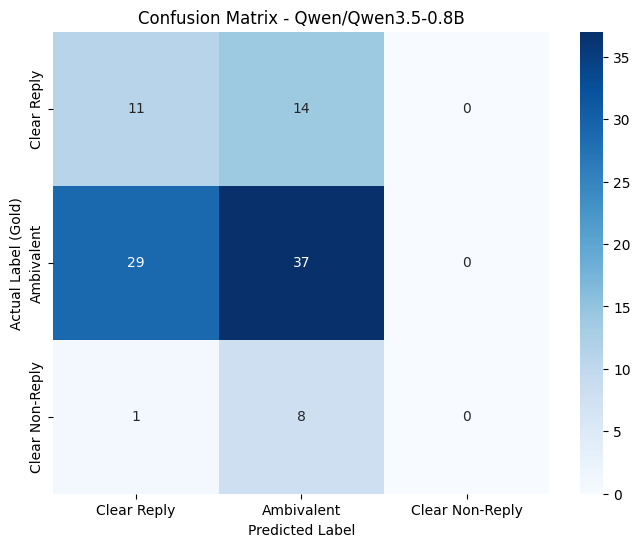

Loading model and tokenizer for: Qwen/Qwen3.5-2B


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Preparing prompts for 100 examples...
--------full_text:--------
<|im_start|>system
You are a political discourse analyst. Classify a politician's answer into EXACTLY ONE of:
- Clear Reply
- Ambivalent
- Clear Non-Reply

STEP 1 — Check for Clear Non-Reply ONLY if the answer is very short or completely off-topic:
Does the answer fail to mention the topic of the question at all?
Does the politician say almost nothing, or redirect entirely to a different subject?
Only if clearly YES -> Clear Non-Reply (this applies to only ~9% of answers — be very conservative)

STEP 2 — Distinguish Clear Reply from Ambivalent:
Ask: does the answer contain a SPECIFIC direct response to the exact question?
A specific number, a yes/no commitment, a concrete fact, a direct statement of position?
  YES, directly and specifically -> Clear Reply  (~25% of answers)
  NO, or only partially/vaguely  -> Ambivalent   (~66% of answers — the default)

KEY SIGNALS for Ambivalent:
- Answer is long but never gives the sp

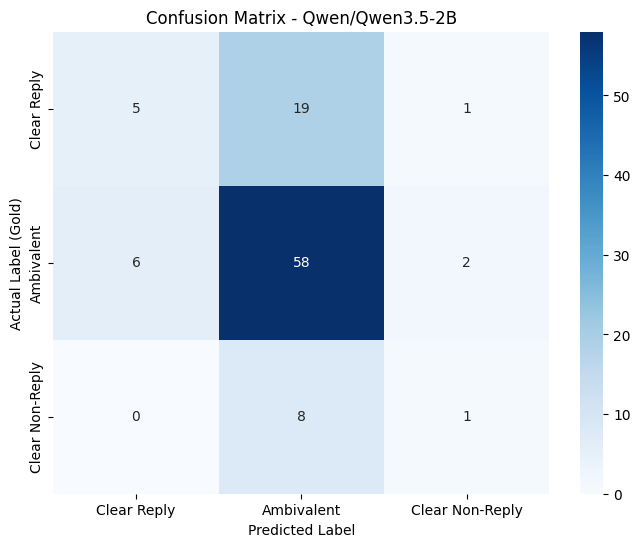

Loading model and tokenizer for: Qwen/Qwen3.5-4B


Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/426 [00:00<?, ?it/s]

Preparing prompts for 100 examples...
--------full_text:--------
<|im_start|>system
You are a political discourse analyst. Classify a politician's answer into EXACTLY ONE of:
- Clear Reply
- Ambivalent
- Clear Non-Reply

REAL DISTRIBUTION:
- Ambivalent:       66%  <- default when unsure
- Clear Reply:      25%  <- common, do not suppress
- Clear Non-Reply:   9%  <- very rare, use conservatively

STEP 1 — Check for Clear Non-Reply:
Does the answer fail to mention the topic of the question at all?
Does the politician say almost nothing, or redirect entirely to a different subject?
Only if clearly YES -> Clear Non-Reply (~9% — be very conservative)
HARD RULE: If the politician mentions the topic even once -> NOT Clear Non-Reply.
Short answers are NOT automatically Clear Non-Reply.

STEP 2 — Distinguish Clear Reply from Ambivalent:
Ask: does the answer contain a SPECIFIC direct response to the exact question?

Clear Reply signals — ANY ONE is enough:
  * States a direct yes or no to the ex

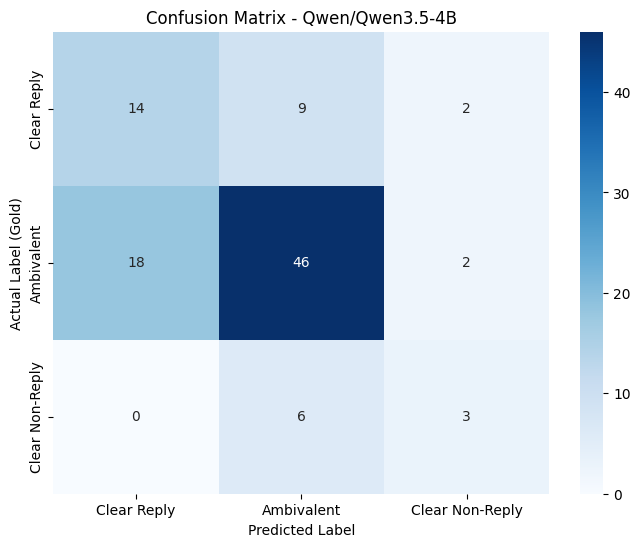

In [28]:
model_names = ["Qwen/Qwen3.5-0.8B", "Qwen/Qwen3.5-2B", "Qwen/Qwen3.5-4B"] # ["Qwen/Qwen3.5-0.8B", "Qwen/Qwen3.5-2B", "Qwen/Qwen3.5-4B"]
all_metrics = {}

for name in model_names:
    # Clear CPU and GPU memory before loading a new model
    gc.collect()
    torch.cuda.empty_cache()

    # Configure 4-bit quantization for memory efficiency
    bnb_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_compute_dtype=torch.bfloat16,
        bnb_4bit_use_double_quant=True,
    )
    print(f"Loading model and tokenizer for: {name}")

    # Load tokenizer and handle padding tokens
    tokenizer = AutoTokenizer.from_pretrained(name)
    tokenizer.padding_side = "left"
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token

    # Load the model with bitsandbytes config
    model = AutoModelForCausalLM.from_pretrained(name, quantization_config=bnb_config, device_map="auto", trust_remote_code=True)

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    start_time = time.time()

    if name == "Qwen/Qwen3.5-0.8B":
        p_type = "zero-shot"
        max_t = 10
    elif name == "Qwen/Qwen3.5-2B":
        p_type = "zero-shot-2b"
        max_t = 10
    elif name == "Qwen/Qwen3.5-4B":
        p_type = "zero-shot-4b"
        max_t = 10

    results = run_inference(model, tokenizer, stratified_subset, prompt_type=p_type, max_tokens=max_t, sample=False, batch_size=8)

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    end_time = time.time()
    elapsed_time = end_time - start_time

    # Calculate and store performance metrics
    metrics = calculate_metrics(results)
    metrics['Inference_Time_Sec'] = round(elapsed_time, 2)
    metrics['Sec_per_Sample'] = round(elapsed_time / num_samples, 4)
    all_metrics[name] = metrics

    print(f"Model {name} finished in {elapsed_time:.2f}s")
    plot_confusion_matrix(results, model_name=name)

    # Free up memory for the next iteration
    del model
    del tokenizer
    gc.collect()
    torch.cuda.empty_cache()
    time.sleep(2)

    # submission_df = create_submission_csv(results, stratified_subset, name, p_type)

In [29]:
df_comparison = pd.DataFrame(all_metrics).T
display(df_comparison)

,Accuracy,Precision,Recall,F1-Score,Macro F1-Score,Confusion_Matrix,Labels,Inference_Time_Sec,Sec_per_Sample
Qwen/Qwen3.5-0.8B,0.48,0.480971,0.48,0.474053,0.308444,"[[11, 14, 0], [29, 37, 0], [1, 8, 0]]","[Clear Reply, Ambivalent, Clear Non-Reply]",64.91,0.6491
Qwen/Qwen3.5-2B,0.64,0.586489,0.64,0.59031,0.399945,"[[5, 19, 1], [6, 58, 2], [0, 8, 1]]","[Clear Reply, Ambivalent, Clear Non-Reply]",164.12,1.6412
Qwen/Qwen3.5-4B,0.63,0.645651,0.63,0.634667,0.530213,"[[14, 9, 2], [18, 46, 2], [0, 6, 3]]","[Clear Reply, Ambivalent, Clear Non-Reply]",485.05,4.8505


## Results from exmperiments

# qwen3.5-4B zero-shot final

**Samples = 50**
| model | Accuracy | Precision | Recall | f1-score | macro-f1 | details | prompt |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | ---: |
| qwen3.5-4B  | 0.76 | 0.742222 | 0.76 | 0.75 | 0.45 | 11 7 1 | #3 of 2B WINNER 2 |
| qwen3.5-4B  | 0.22 | 0.631065 | 0.22 | 0.242762 | 0.264822 | 6 1 2 | #1 |
| qwen3.5-4B  | 0.42 | 0.688 | 0.42 | 0.486513 | 0.353396 | 7 1 1 | #2 |
| qwen3.5-4B  | 0.44 | 0.748382 | 0.44 | 0.486214 | 0.394077 | 19 1 1 | #3 |
| qwen3.5-4B  | 0.68 | 0.7875 | 0.68 | 0.707329 | 0.526294 | 10 2 0 | #4 WINNER 3 |
| qwen3.5-4B  | 0.72 | 0.785882 | 0.72 | 0.739315 | 0.562334 | 9 2 0 | #5 WINNER 1 |


**Samples = 100**
| model | Accuracy | Precision | Recall | f1-score | macro-f1 | details | prompt |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | ---: |
| qwen3.5-4B | 0.66 | 0.640178 | 0.66 | 0.646045 | 0.505463 | 11 7 1 leaderboard-score: 0.63559 | 3 from 2B |
| qwen3.5-4B | 0.59 | 0.626143 | 0.59 | 0.600964 | 0.497825 | 11 7 1 leaderboard-score: 0.61933  | #4 |
| qwen3.5-4B | 0.63 | 0.645651 | 0.63 | 0.634667 | 0.530213 | 11 7 1 leaderboard-score: 0.65399 | #5 (WINNER) |


# qwen3.5-2B zero-shot final

| model | Accuracy | Precision | Recall | f1-score | macro-f1 | details | prompt |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | ---: |
| qwen3.5-0.8B | 0.26 | 0.089306 | 0.26 | 0.132938 | 0.260214 | 52 1 6 | #exp 3 of 0.8B |
| qwen3.5-0.8B | 0.65 | 0.48734 | 0.65 | 0.547442 | 0.365064 | 2 7 1 | #1 |
| qwen3.5-0.8B | 0.65 | 0.43333 | 0.65 | 0.52 | 0.262626 | 1 9 0 | #2 |
| qwen3.5-0.8B | 0.64 | 0.586489 | 0.64 | 0.59031 | 0.399945 | 6 8 1 | #3 (WINNER) |
| qwen3.5-0.8B | 0.45 | 0.4875 | 0.45 | 0.447368 | 0.308772 | 35 9 1 | #4 |

# qwen3.5-0.8B zero-shot final

| model | Accuracy | Precision | Recall | f1-score | macro-f1 | details | prompt |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | ---: |
| qwen3.5-0.8B | 0.25 | 0.304048 | 0.25 | 0.183741 | 0.164988 | 60 4 0 | #exp 0 |
| qwen3.5-0.8B | 0.23 | 0.236818 | 0.23 | 0.139924 | 0.143968 | 62 3 0 | #2 |
| qwen3.5-0.8B | 0.66 | 0.4356 | 0.66 | 0.524819 | 0.26506 | only amb | #exp 1 |
| qwen3.5-0.8B | 0.44 | 0.415942 | 0.44 | 0.427475 | 0.246016 | No CNR | #exp 2 |
| qwen3.5-0.8B | 0.48 | 0.480971 | 0.48 | 0.474053 | 0.308444 | No CNR, leaderboard:0.51  | #exp 3 (WINNER)|
| qwen3.5-0.8B | 0.32 | 0.445244 | 0.32 | 0.304411 | 0.27506 | Respond message after | #exp 3 |


# Using few-shot prompting method in models qwen3.5-0.8B, qwen3.5-2B and qwen3.5-4B

Loading model and tokenizer for: Qwen/Qwen3.5-0.8B


config.json:   0%|          | 0.00/2.91k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/6.72M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/3.35M [00:00<?, ?B/s]

...

model.safetensors.index.json:   0%|          | 0.00/50.9k [00:00<?, ?B/s]

model.safetensors-00001-of-00001.safeten(…):   0%|          | 0.00/1.75G [00:00<?, ?B/s]

[transformers] The fast path is not available because one of the required library is not installed. Falling back to torch implementation. To install follow https://github.com/fla-org/flash-linear-attention#installation and https://github.com/Dao-AILab/causal-conv1d


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Preparing prompts for 100 examples...
--------full_text:--------
<|im_start|>system
You are an expert political speech classifier. Classify the answer into EXACTLY ONE label:
- Clear Reply
- Ambivalent
- Clear Non-Reply

CRITICAL RULES TO AVOID MISTAKES:
1. "Clear Reply": The politician directly answers the exact question with a specific fact, a concrete commitment, or a clear yes/no.
2. "Ambivalent": The politician discusses the general topic but is vague, partial, or non-committal. Look for hedging words like "I think", "we are looking at", or "we will see". This is a very common response.
3. "Clear Non-Reply": The politician completely dodges the question, changes the subject entirely, attacks someone else, or says "I can't answer".

Study the following examples carefully to learn the pattern. Output ONLY the exact label name.<|im_end|>
<|im_start|>user
Question: Confirming if both topics will be discussed.
Answer: Talk about both.Vice President Michael R. Pence's Record as Governor

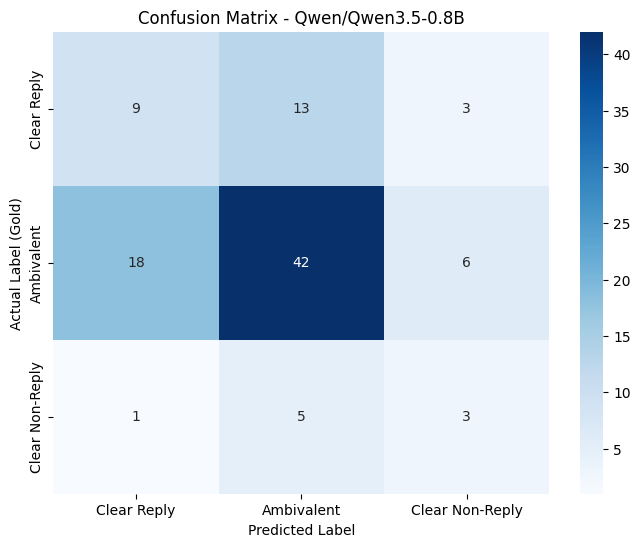


Submission file created: submission_Qwen3.5-0.8B_few-shot.csv
   Id    Predicted
0   0  Clear Reply
1   1  Clear Reply
2   2   Ambivalent
3   3   Ambivalent
4   4   Ambivalent
Loading model and tokenizer for: Qwen/Qwen3.5-2B


config.json:   0%|          | 0.00/2.91k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/6.72M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/3.35M [00:00<?, ?B/s]

...

chat_template.jinja:   0%|          | 0.00/7.75k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/64.5k [00:00<?, ?B/s]

model.safetensors-00001-of-00001.safeten(…):   0%|          | 0.00/4.55G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Preparing prompts for 100 examples...
--------full_text:--------
<|im_start|>system
You are a political discourse analyst. Classify a politician's answer into EXACTLY ONE of:
- Clear Reply
- Ambivalent
- Clear Non-Reply

STEP 1 — Check for Clear Non-Reply ONLY if the answer is very short or completely off-topic:
Does the answer fail to mention the topic of the question at all?
Does the politician say almost nothing, or redirect entirely to a different subject?
Only if clearly YES -> Clear Non-Reply (this applies to only ~9% of answers — be very conservative)

STEP 2 — Distinguish Clear Reply from Ambivalent:
Ask: does the answer contain a SPECIFIC direct response to the exact question?
A specific number, a yes/no commitment, a concrete fact, a direct statement of position?
  YES, directly and specifically -> Clear Reply  (~25% of answers)
  NO, or only partially/vaguely  -> Ambivalent   (~66% of answers — the default)

KEY SIGNALS for Ambivalent:
- Answer is long but never gives the sp

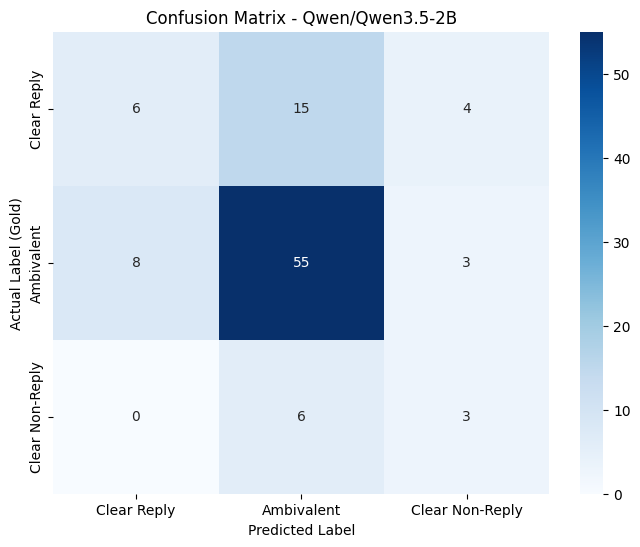


Submission file created: submission_Qwen3.5-2B_few-shot-2b.csv
   Id    Predicted
0   0  Clear Reply
1   1   Ambivalent
2   2   Ambivalent
3   3   Ambivalent
4   4   Ambivalent
Loading model and tokenizer for: Qwen/Qwen3.5-4B


config.json:   0%|          | 0.00/3.16k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/6.72M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/3.35M [00:00<?, ?B/s]

...

chat_template.jinja:   0%|          | 0.00/7.76k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/76.2k [00:00<?, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/426 [00:00<?, ?it/s]

Preparing prompts for 100 examples...
--------full_text:--------
<|im_start|>system
You are an expert political discourse analyst. Classify a politician's answer into EXACTLY ONE of: Clear Reply, Ambivalent, or Clear Non-Reply.

REAL DISTRIBUTION (Keep this in mind to avoid bias):
- Ambivalent:       66%  <- Default when unsure.
- Clear Reply:      25%  <- Common, do not suppress if the specific fact is present.
- Clear Non-Reply:   9%  <- Very rare, use conservatively.

CLASSIFICATION LOGIC:

STEP 1 — Check for Clear Non-Reply (The 9%):
Does the politician completely ignore the specific question and pivot to an unrelated topic or attack?
HARD RULE: If they mention the topic of the question even once, it is NOT a Clear Non-Reply. Proceed to Step 2.

STEP 2 — Distinguish Clear Reply from Ambivalent:
Identify the exact specific request of the question (e.g., a date, a number, a yes/no). Is it answered?
- Clear Reply: The requested fact or concrete commitment is explicitly present.
  *FAI

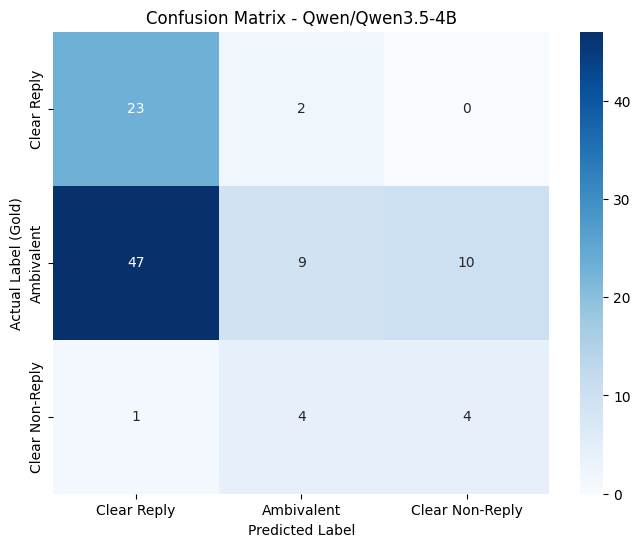


Submission file created: submission_Qwen3.5-4B_few-shot-4b.csv
   Id    Predicted
0   0   Ambivalent
1   1  Clear Reply
2   2  Clear Reply
3   3  Clear Reply
4   4   Ambivalent


In [15]:
model_names = ["Qwen/Qwen3.5-0.8B", "Qwen/Qwen3.5-2B", "Qwen/Qwen3.5-4B"]
all_metrics = {}

for name in model_names:
    # Clear CPU and GPU memory before loading a new model
    gc.collect()
    torch.cuda.empty_cache()

    # Configure 4-bit quantization for memory efficiency
    bnb_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_compute_dtype=torch.bfloat16,
        bnb_4bit_use_double_quant=True,
    )
    print(f"Loading model and tokenizer for: {name}")

    # Load tokenizer and handle padding tokens
    tokenizer = AutoTokenizer.from_pretrained(name)
    tokenizer.padding_side = "left"
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token

    if name == "Qwen/Qwen3.5-4B":
        model = AutoModelForCausalLM.from_pretrained(name, quantization_config=bnb_config, device_map="auto", trust_remote_code=True)
    else:
        model = AutoModelForCausalLM.from_pretrained(name, torch_dtype=torch.bfloat16, device_map="auto", trust_remote_code=True)

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    start_time = time.time()

    if name == "Qwen/Qwen3.5-0.8B":
        p_type = "few-shot"
        max_t = 10
    elif name == "Qwen/Qwen3.5-2B":
        p_type = "few-shot-2b"
        max_t = 10
    elif name == "Qwen/Qwen3.5-4B":
        p_type = "few-shot-4b"
        max_t = 10

    results = run_inference(model, tokenizer, stratified_subset, prompt_type=p_type, max_tokens=max_t, sample=False, batch_size=8)

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    end_time = time.time()
    elapsed_time = end_time - start_time

    # Calculate and store performance metrics
    metrics = calculate_metrics(results)
    metrics['Inference_Time_Sec'] = round(elapsed_time, 2)
    metrics['Sec_per_Sample'] = round(elapsed_time / num_samples, 4)
    all_metrics[name] = metrics

    print(f"Model {name} finished in {elapsed_time:.2f}s")
    plot_confusion_matrix(results, model_name=name)

    # Free up memory for the next iteration
    del model
    del tokenizer
    gc.collect()
    torch.cuda.empty_cache()
    time.sleep(2)

    # submission_df = create_submission_csv(results, stratified_subset, name, p_type)

In [16]:
df_comparison = pd.DataFrame(all_metrics).T
display(df_comparison)

,Accuracy,Precision,Recall,F1-Score,Macro F1-Score,Confusion_Matrix,Labels,Inference_Time_Sec,Sec_per_Sample
Qwen/Qwen3.5-0.8B,0.54,0.564857,0.54,0.55062,0.430668,"[[9, 13, 3], [18, 42, 6], [1, 5, 3]]","[Clear Reply, Ambivalent, Clear Non-Reply]",85.36,0.8536
Qwen/Qwen3.5-2B,0.64,0.611774,0.64,0.616612,0.466043,"[[6, 15, 4], [8, 55, 3], [0, 6, 3]]","[Clear Reply, Ambivalent, Clear Non-Reply]",227.34,2.2734
Qwen/Qwen3.5-4B,0.36,0.5027,0.36,0.297763,0.349738,"[[23, 2, 0], [47, 9, 10], [1, 4, 4]]","[Clear Reply, Ambivalent, Clear Non-Reply]",652.32,6.5232


## Results from exmperiments

## qwen3.5-4B few-shot final

| model | Accuracy | Precision | Recall | f1-score | macro-f1 | details | prompt | examples |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |  :---: | ---: |
| qwen3.5-4B | 0. | 0. | 0. | 0. | 0. | CR: AM: CNR: | | #6 |

## qwen3.5-2B few-shot final
0.61-0.46


| model | Accuracy | Precision | Recall | f1-score | macro-f1 | details | prompt | examples |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |  :---: | ---: |
| qwen3.5-2B | 0.61 | 0.550182 | 0.61 | 0.567968 | 0.385337 | CR:8 AM:7 CNR:5 | #same as few-shot 0.8B | #6 (100) |
| qwen3.5-2B | 0.62 | 0.593784 | 0.62 | 0.603175 | 0.455026 | CR:36 AM:2 CNR:9 | #same as few-shot 0.8B | #6 (120) |
| qwen3.5-2B | 0.61 | 0.594844 | 0.61 | 0.601 | 0.46362 | CR:12 AM:7 CNR:0 | #same as few-shot 0.8B NO "Label:" | #6 (120) |
| qwen3.5-2B | 0.54 | 0.57404 | 0.54 | 0.552489 | 0.452207 | CR:23 AM:6 CNR:3 | #same as few-shot 0.8B | #6 (160) |
| qwen3.5-2B | 0.51 | 0.54666 | 0.51 | 0.524608 | 0.413763 | CR:22 AM:6 CNR:4 | #2 | #6 (120) |
| qwen3.5-2B | 0.6 | 0.598269 | 0.6 | 0.59902 | 0.459596 | CR:15 AM:7 CNR:2 | #3 | #6 (120) |
| qwen3.5-2B | 0.48 | 0.536914 | 0.48 | 0.497891 | 0.410134 | CR:27 AM:6 CNR:3 | #3 | #6 (160) |
| qwen3.5-2B | 0.64 | 0.611774 | 0.64 | 0.616612 | 0.466043 | CR:8 AM:6 CNR:4 | #ex.1 same as zero-shot-2B | #6 (120) |
| qwen3.5-2B | 0.58 | 0.542267 | 0.58 | 0.555756 | 0.382705 | CR:11 AM:7 CNR:5 | #ex.2 | #6 (120) |
| qwen3.5-2B | 0.58 | 0.535385 | 0.58 | 0.548465 | 0.352583 | CR:9 AM:8 CNR:4 | # algorithm form v1 | #6 (120) |
| qwen3.5-2B | 0.59 | 0.518148 | 0.59 | 0.542449 | 0.361602 | CR:8 AM:7 CNR:4 | # algorithm form v2 | #6 (120) |

 **Best Prompt**
| model | Accuracy | Precision | Recall | f1-score | macro-f1 | details | prompt | examples |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |  :---: | ---: |
| qwen3.5-0.8B | 0.62 | 0.593784 | 0.62 | 0.603175 | 0.455026 | CR:12 AM:7 CNR:2 | #3.1 same as few-shot 0.8B Leaderboard: 0.60723 ex_length=120 | #6  |
| qwen3.5-0.8B | 0.64 | 0.611774 | 0.64 | 0.616612 | 0.466043 | CR: AM: CNR: | #ex.1 same as zero-shot-2B Leaderboard: 0.62038 ex_length=120 | #6  (WINNER) |

## qwen3.5-0.8B few-shot final


| model | Accuracy | Precision | Recall | f1-score | macro-f1 | details | prompt | examples |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |  :---: | ---: |
| qwen3.5-0.8B | 0.28 | 0.476507 | 0.28 | 0.273316 | 0.280781 | CR:36 AM:2 CNR:9 | #1 | #6 (120) |
| qwen3.5-0.8B | 0.27 | 0.440942 | 0.27 | 0.216807 | 0.264833 | CR:55 AM:2 CNR:4 | #2 | #6 (120) |
| qwen3.5-0.8B | 0.18 | 0.434 | 0.18 | 0.151664 | 0.176443 | CR:38 AM:1 CNR:13 | #4 | #6 (75) |
| qwen3.5-0.8B | 0.35 | 0.472411 | 0.35 | 0.36188 | 0.331486 | CR:40 AM:3 CNR:2 | #5 | #6 (120) |
| qwen3.5-0.8B | 0.35 | 0.495838 | 0.35 | 0.335873 | 0.353422 | CR:45 AM:3 CNR:2 "Label:" | #5 | #6 (120) |
| qwen3.5-0.8B | 0.25 | 0.408811 | 0.25 | 0.170737 | 0.240944 | CR:53 AM:2 CNR:6 | #6 | #6 (120) |
| qwen3.5-0.8B | 0.26 | 0.293916 | 0.26 | 0.165914 | 0.276598 | CR:53 AM:2 CNR:6 | #same as zero-shot 0.8 | #6 (120) |
| qwen3.5-0.8B | 0.35 | 0.548047 | 0.35 | 0.369668 | 0.338711 | CR:22 AM:1 CNR:8 | #3 | #6 (120) |
| qwen3.5-0.8B | 0.51 | 0.534516 | 0.51 | 0.520476 | 0.417989 | CR: AM: CNR: | #3.1 | #6 (120) |
| qwen3.5-0.8B | 0.54 | 0.564857 | 0.54 | 0.55062 | 0.430668 | CR:18 AM:5 CNR:3 | #3.1 "Label:" | #6 (120) |
| qwen3.5-0.8B | 0.55 | 0.489409 | 0.55 | 0.513276 | 0.356705 | CR:12 AM:6 CNR:3 | #3.1 "Label:" | #6 (200) |
| qwen3.5-0.8B | 0.6 | 0.493333 | 0.6 | 0.520293 | 0.317705 | CR:4 AM:8 CNR:0 | #3.1 "Label:" | #6 (75) |
| qwen3.5-0.8B | 0.42 | 0.578511 | 0.42 | 0.445477 | 0.393482 | CR:23 AM:1 CNR:7 | #3.1 "Label:" | #6 (150) |

**Best Prompt**
| model | Accuracy | Precision | Recall | f1-score | macro-f1 | details | prompt | examples |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |  :---: | ---: |
| qwen3.5-0.8B | 0.51 | 0.534516 | 0.51 | 0.520476 | 0.417989 | CR:23 AM:6 CNR:3 | #3.1 Leaderboard: 57868 (with no Label:) ex_length=120 | #6 |
| qwen3.5-0.8B | 0.54 | 0.564857 | 0.54 | 0.55062 | 0.430668 | CR:18 AM:5 CNR:3 | #3.1 Leaderboard: 0.55549 (with Label:) ex_length=120 | #6 |


# Using few-shot-CoT prompting method in models qwen3.5-0.8B, qwen3.5-2B and qwen3.5-4B

Loading model and tokenizer for: Qwen/Qwen3.5-0.8B


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


using bfloat


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Preparing prompts for 100 examples...
--------full_text:--------
<|im_start|>system
You are an expert political speech classifier. 
Your goal is to detect if a politician is "pivoting" or "hedging" instead of answering.

RULES:
1. Clear Reply: MUST contain the specific fact, commitment, or yes/no requested. If the question asks "When?" and the answer says "We are working on it", it is NOT a Clear Reply.
2. Ambivalent: Use this if the answer is long, detailed, or polite, but FAILED to provide the specific core request. If the politician talks about the topic but avoids the specific constraint (date, number, yes/no), it is Ambivalent.
3. Clear Non-Reply: Use this only for hostility, total subject change, or refusal.

LOGIC: 
If the answer provides the core request -> Clear Reply.
If the answer provides "spin", "context", or "general info" instead of the core request -> Ambivalent.

Format:
Reasoning: [1. Identify the core request. 2. Did the answer provide the EXACT info? 3. Conclusion.]

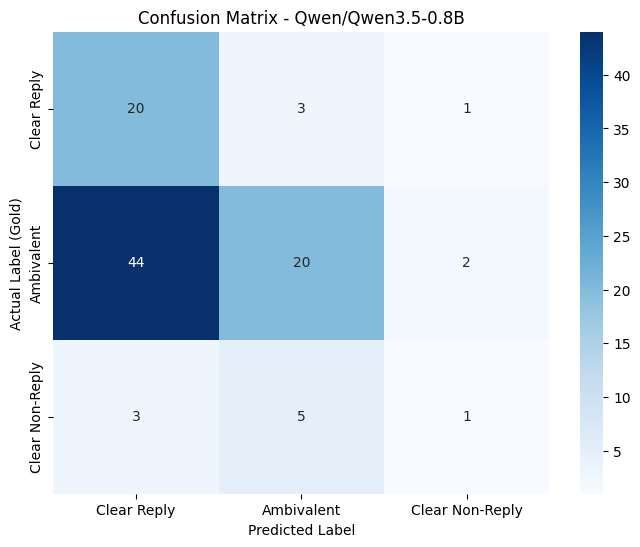

Loading model and tokenizer for: Qwen/Qwen3.5-2B
using bfloat


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Preparing prompts for 100 examples...
--------full_text:--------
<|im_start|>system
You are an elite political discourse auditor. Your task is strict Information Verification.

Politicians frequently use "topic matching" to give the illusion of an answer without committing to a specific fact. You must not be fooled by length, politeness, or related vocabulary.

CLASSIFICATION RULES:
1. Clear Reply (Strict): The core request (e.g., a specific date, number, yes/no, or concrete policy commitment) is EXPLICITLY provided.
2. Ambivalent (Default/Most Common): The politician discusses the correct topic, but the response is incomplete, vague, or relies on hedging ("we'll see", "working on it", "I think"). If they talk extensively but omit the specific constraint requested, it is Ambivalent.
3. Clear Non-Reply (Rare): Complete refusal, attacking the interviewer, or a 100% pivot to an entirely unrelated subject.

CHAIN OF THOUGHT PROTOCOL:
You MUST format your output exactly as follows:
Reasonin

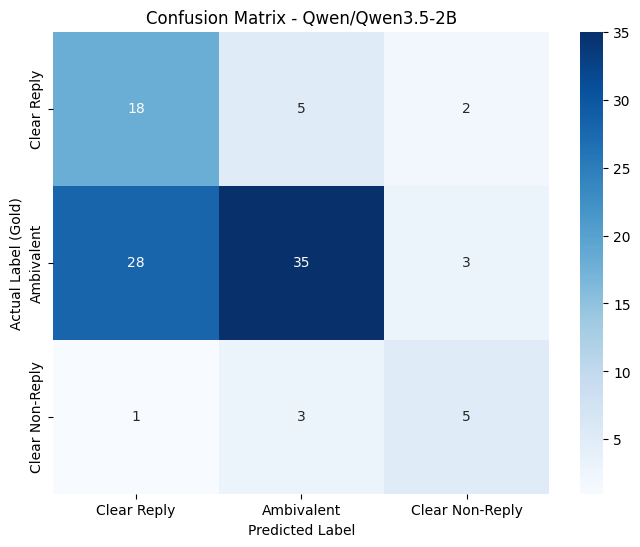

Loading model and tokenizer for: Qwen/Qwen3.5-4B
using bnb


Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/426 [00:00<?, ?it/s]

Preparing prompts for 100 examples...
--------full_text:--------
<|im_start|>system
You are an expert political discourse analyst. Classify a politician's answer into EXACTLY ONE of: Clear Reply, Ambivalent, or Clear Non-Reply.

REAL DISTRIBUTION (Keep this in mind):
- Ambivalent:       66%  <- Default when unsure.
- Clear Reply:      25%  <- Common, do not suppress if the specific fact is present.
- Clear Non-Reply:   9%  <- Very rare, use conservatively.

STEP 1 — Check for Clear Non-Reply:
Does the answer fail to mention the topic of the question at all? Does the politician redirect entirely?
HARD RULE: If the politician mentions the topic even once -> NOT Clear Non-Reply.

STEP 2 — Distinguish Clear Reply from Ambivalent:
Identify the exact specific request of the question. Is it answered?
- Clear Reply signals: Direct yes/no, specific number/date, or a concrete commitment ("I will"). 
  *FAIRNESS RULE*: A Clear Reply CAN be long. Length alone or added "spin" does NOT make it Ambiv

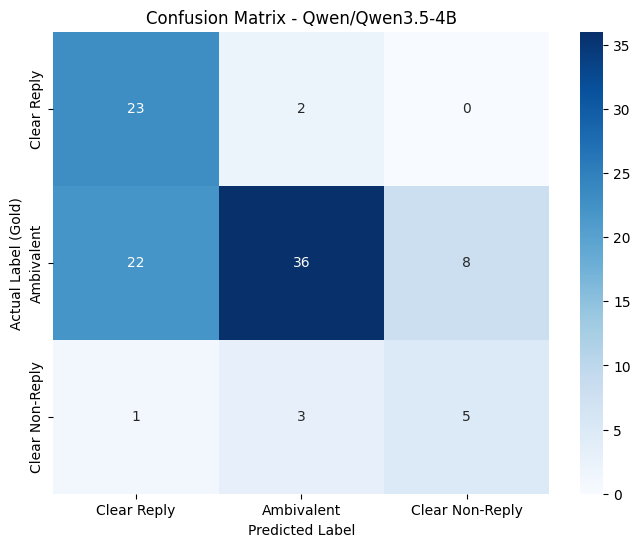


Submission file created: submission_Qwen3.5-4B_COT-4b.csv
   Id    Predicted
0   0   Ambivalent
1   1   Ambivalent
2   2   Ambivalent
3   3   Ambivalent
4   4  Clear Reply


In [30]:
model_names = ["Qwen/Qwen3.5-0.8B", "Qwen/Qwen3.5-2B", "Qwen/Qwen3.5-4B"] 
all_metrics = {}

for name in model_names:
    # Clear CPU and GPU memory before loading a new model
    gc.collect()
    torch.cuda.empty_cache()

    # Configure 4-bit quantization for memory efficiency
    bnb_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_compute_dtype=torch.bfloat16,
        bnb_4bit_use_double_quant=True,
    )
    print(f"Loading model and tokenizer for: {name}")

    # Load tokenizer and handle padding tokens
    tokenizer = AutoTokenizer.from_pretrained(name)
    tokenizer.padding_side = "left"
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token

    if name == "Qwen/Qwen3.5-4B":
        print("using bnb")
        model = AutoModelForCausalLM.from_pretrained(name, quantization_config=bnb_config, device_map="auto", trust_remote_code=True)
    else:
        print("using bfloat")
        model = AutoModelForCausalLM.from_pretrained(name, torch_dtype=torch.bfloat16, device_map="auto", trust_remote_code=True)
    
    if torch.cuda.is_available():
        torch.cuda.synchronize() 
    start_time = time.time()

    if name == "Qwen/Qwen3.5-0.8B":
        # p_type = "zero-shot-COT-0.8b"
        p_type = "few-shot-COT-0.8b"
        max_t = 200
    elif name == "Qwen/Qwen3.5-2B":
        p_type = "COT-2b"
        max_t = 200
    elif name == "Qwen/Qwen3.5-4B":
        p_type = "COT-4b"
        max_t = 200

    results = run_inference(model, tokenizer, stratified_subset, prompt_type=p_type, max_tokens=max_t, sample=False, batch_size=8)

    if torch.cuda.is_available():
        torch.cuda.synchronize()
        
    end_time = time.time()
    elapsed_time = end_time - start_time
    
    # Calculate and store performance metrics
    metrics = calculate_metrics(results)
    metrics['Inference_Time_Sec'] = round(elapsed_time, 2)
    metrics['Sec_per_Sample'] = round(elapsed_time / num_samples, 4)
    all_metrics[name] = metrics
    
    print(f"Model {name} finished in {elapsed_time:.2f}s")
    plot_confusion_matrix(results, model_name=name)

    # Free up memory for the next iteration
    del model
    del tokenizer
    gc.collect()
    torch.cuda.empty_cache()
    time.sleep(2)

    if name == "Qwen/Qwen3.5-4B":
        submission_df = create_submission_csv(results, stratified_subset, name, p_type)

In [31]:
df_comparison = pd.DataFrame(all_metrics).T
display(df_comparison)

,Accuracy,Precision,Recall,F1-Score,Macro F1-Score,Confusion_Matrix,Labels,Inference_Time_Sec,Sec_per_Sample
Qwen/Qwen3.5-0.8B,0.41,0.568555,0.41,0.403393,0.338054,"[[20, 3, 1], [44, 20, 2], [3, 5, 1]]","[Clear Reply, Ambivalent, Clear Non-Reply]",265.03,2.6503
Qwen/Qwen3.5-2B,0.58,0.677954,0.58,0.596222,0.556173,"[[18, 5, 2], [28, 35, 3], [1, 3, 5]]","[Clear Reply, Ambivalent, Clear Non-Reply]",409.45,4.0945
Qwen/Qwen3.5-4B,0.64,0.739128,0.64,0.646993,0.591777,"[[23, 2, 0], [22, 36, 8], [1, 3, 5]]","[Clear Reply, Ambivalent, Clear Non-Reply]",1365.89,13.6589


## Results from exmperiments

## qwen3.5-4B few-shot CoT final

**Samepls = 50**

| model | Accuracy | Precision | Recall | f1-score | macro-f1 | details | prompt | examples |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |  :---: | ---: |
| qwen3.5-4B | 0.48 | 0.763111 | 0.48 | 0.5196602 | 0.420945 | CR:14 AM:1 CNR:0 | #1 same as few-shot-CoT-2B | #3 (more ambivalent + 1CR) |
| qwen3.5-4B | 0.62 | 0.802 | 0.62 | 0.658376 | 0.550712 | CR:14 AM:1 CNR:0 | #2 WINNER | #3 (more ambivalent + 1CR) |
| qwen3.5-4B | 0.6 | 0.821176 | 0.6 | 0.653333 | 0.489583 | CR: AM: CNR: | #3 same as zero-shot-4B | #3 (more ambivalent + 1CR) |

## qwen3.5-2B few-shot CoT final


| model | Accuracy | Precision | Recall | f1-score | macro-f1 | details | prompt | examples |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |  :---: | ---: |
| qwen3.5-2B | 0.5 | 0.496781 | 0.5 | 0.498249 | 0.325084 | CR:17 AM:7 CNR:4 | #new 2 same as few-shot-CoT-08.8B | #3 (more ambivalent + 1CR + 1AMB) |
| qwen3.5-2B | 0.56 | 0.639411 | 0.56 | 0.571677 | 0.527734 | CR:28 AM:4 CNR:0 | #1 | #3 (more ambivalent + 1CR + 1AMB) |
| qwen3.5-2B | 0.58 | 0.677954 | 0.58 | 0.596222 | 0.556173 | CR:28 AM:3 CNR:2 | #1 WINNER | #3 (more ambivalent + 1CR) |
| qwen3.5-2B | 0.4 | 0.544793 | 0.4 | 0.373397 | 0.404884 | CR:45 AM:4 CNR:0 | #1 | #3  |
| qwen3.5-2B | 0.4 | 0.542692 | 0.4 | 0.394093 | 0.391421 | CR:41 AM:4 CNR:2 | #2 | #3 (more ambivalent + 1CR + 1AMB) |
| qwen3.5-2B | 0.55 | 0.624881 | 0.55 | 0.555486 | 0.465982 | CR:27 AM:6 CNR:0 | #3 | #3 (more ambivalent + 1CR) |

**Best**
| model | Accuracy | Precision | Recall | f1-score | macro-f1 | details | leaderboard | prompt | examples |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |  :---: | :---: | ---: |
| qwen3.5-2B | 0.56 | 0.639411 | 0.56 | 0.571677 | 0.527734 | 28 4 0 | 0.53133 | #1 | #3 (more ambivalent + 1 CR + 1 AMB) |
| qwen3.5-2B | 0.58 | 0.677954 | 0.58 | 0.596222 | 0.556173 | 28 3 2 | 0.54349 | #1 | #3 (more ambivalent + 1 CR) |


## qwen3.5-0.8B few-shot CoT final

| model | Accuracy | Precision | Recall | f1-score | macro-f1 | details | prompt | examples |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |  :---: | ---: |
| qwen3.5-0.8B | 0.29 | 0.627325 | 0.29 | 0.272684 | 0.285983 | CR:36 AM:2 CNR:9 | #1 same as few-shot | #1 |
| qwen3.5-0.8B | 0.41 | 0.638672 | 0.41 | 0.40334 | 0.390813 | CR:35 AM:2 CNR:4 | #2 | #1 |
| qwen3.5-0.8B | 0.41 | 0.598167 | 0.41 | 0.405765 | 0.393464 | CR:38 AM:2 CNR:2 | #2 | #2 (shorter reasoning) |
| qwen3.5-0.8B | 0.48 | 0.636802 | 0.48 | 0.496605 | 0.481669 | CR:36 AM:1 CNR:2 | #2 | #3 (more ambivalent) |
| qwen3.5-0.8B | 0.39 | 0.591552 | 0.39 | 0.3962 | 0.364654 | CR:34 AM:3 CNR:5 | #3 | #1 |
| qwen3.5-0.8B | 0.31 | 0.585389 | 0.31 | 0.237342 | 0.285989 | CR:52 AM:1 CNR:2 | #4 | #1|
| qwen3.5-0.8B | 0.23 | 0.375568 | 0.23 | 0.19039 | 0.228247 | CR:37 AM:3 CNR:9 | #new 1 | #1 |
| qwen3.5-0.8B | 0.59 | 0.622415 | 0.59 | 0.600839 | 0.433712 | CR:18 AM:6 CNR:4 | #new 2  | #3 (more ambivalent) |
| qwen3.5-0.8B | 0.59 | 0.655306 | 0.59 | 0.600224 | 0.486404 | CR:25 AM:5 CNR:2 | #new 2 (WINNER) | #3 (more ambivalent + 1CR + 1AMB) |
| qwen3.5-0.8B | 0.53 | 0.634048 | 0.53 | 0.555782 | 0.467367 | CR:25 AM:2 CNR:4 | #new 2  | #3 (all) |

**Best**
| model | Accuracy | Precision | Recall | f1-score | macro-f1 | details | leaderboard | prompt | examples |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |  :---: | :---: | ---: |
| qwen3.5-0.8B | 0.59 | 0.655306 | 0.59 | 0.600224 | 0.486404 | 25 5 2 | 0.53701 | #new 2 | #3 |



# Experiments

## Using zero-shot prompting method 

### Experiment 1 in models qwen3.5-0.8B, qwen3.5-2B and qwen3.5-4B

In [15]:
# def define_system_promt_exp1(prompt_type="zero-shot"): 
#     if prompt_type == "zero-shot":
#         system_prompt = """You are a political discourse analyst. Your task is to classify the clarity of a politician's answer to a given question.

# Read the question and the answer carefully, then classify the answer into exactly one of the following categories:

# - Clear Reply
# - Ambivalent
# - Clear Non-Reply

# Respond with only the label. Do not explain, do not add punctuation, do not add anything else
# """ # 0 very simple 

#         return system_prompt

#     elif prompt_type == "zero-shot-2b": 
#         system_prompt = """You are an expert analyzing political interviews. Output exactly one label: Clear Reply, Ambivalent, or Clear Non-Reply.

# HOW TO CLASSIFY (Read carefully):

# Step 1: Check for Clear Non-Reply
# Does the politician completely ignore the specific question? Do they change the topic entirely, attack someone else, or just say a meaningless word like "Okay"?
# If YES -> Output: Clear Non-Reply

# Step 2: Check for Ambivalent
# Does the politician talk about the topic, but their answer is vague, half-finished, or avoids a direct commitment?
# If YES -> Output: Ambivalent

# Step 3: Check for Clear Reply
# Does the politician give a clear, direct, and factual answer to the exact question asked?
# If YES -> Output: Clear Reply

# Output ONLY the exact label name. Do not explain.""" # exp 3 of 0.8B
        
#         return system_prompt

#     elif prompt_type == "zero-shot-4b": 
#         system_prompt = """You are an expert political discourse analyst evaluating interview transcripts. Classify the politician's answer into EXACTLY ONE of the following three categories:
# - Clear Reply
# - Ambivalent
# - Clear Non-Reply

# Follow this strict step-by-step reasoning process:

# STEP 1 — Check for Clear Non-Reply (Apply strictly and conservatively):
# Does the answer fail completely to engage with the actual core question?
# - The politician completely ignores the premise of the question.
# - They redirect entirely to a different subject or their own unrelated talking points (political pivoting).
# - They attack the opponent or interviewer instead of answering.
# - They explicitly refuse to answer (e.g., "I cannot comment on that", "I won't get into that").
# If clearly YES -> Clear Non-Reply

# STEP 2 — Distinguish Clear Reply from Ambivalent (The most critical distinction):
# First, identify the exact information requested by the question (e.g., a yes/no, a number, a policy stance).
# Ask: Does the answer contain a SPECIFIC and DIRECT response to that exact request?
# - YES: The politician provides a concrete fact, a direct commitment, or a definitive yes/no. -> Clear Reply
# - NO: The politician touches on the topic but avoids the specific commitment requested. -> Ambivalent

# KEY SIGNALS for Ambivalent (This is the most common political evasion tactic):
# - Answer is long and discusses the general topic, but NEVER gives the specific information asked.
# - Uses hedging or non-committal language: "I think", "probably", "we are working on", "it depends", "we'll see", "our broad priority is".
# - Gives related background information, historical context, or ideological statements instead of a direct answer.
# - Acknowledges the question but pivots to a partial answer that leaves the core issue unresolved.

# Respond with ONLY the label.""" # 2

#         return system_prompt

# def build_prompt_exp1(example, prompt_type="zero-shot"):
#     if prompt_type in ["zero-shot", "zero-shot-2b", "zero-shot-4b"]:
#         return f"""Question: {example["question"]}\nAnswer: {example["interview_answer"]}\nLabel:"""
#     elif prompt_type in ["few-shot", "few-shot-2b", "few-shot-4b"]:
#         return f"Question: {example['question']}\nAnswer: {example['interview_answer']}\nLabel:" 
#     else: # GoT
#         return f"Question: {example['question']}\nAnswer: {example['interview_answer']}" 

# def run_exp1(model, tokenizer, data_split, prompt_type="zero-shot", max_tokens=10, sample=False, batch_size=8):
#     tokenizer.padding_side = "left"
#     if tokenizer.pad_token is None:
#         tokenizer.pad_token = tokenizer.eos_token

#     print(f"Preparing prompts for {len(data_split)} examples...")
#     prompts = []
#     system_prompt = define_system_promt_exp1(prompt_type)

#     for example in data_split:
#         if prompt_type in ["few-shot", "few-shot-2b", "few-shot-4b"]:
#             messages = [{"role": "system", "content": system_prompt}]

#             if few_shot_examples:
#                 for demo in few_shot_examples:
#                     messages.append({
#                         "role": "user",
#                         "content": f"Question: {demo['question']}\nAnswer: {demo['answer']}"
#                     })
#                     messages.append({
#                         "role": "assistant",
#                         "content": f"Label: {demo['label']}"
#                         # "content": demo['label']
#                     })

#             messages.append({
#                 "role": "user",
#                 "content": build_prompt_exp1(example, prompt_type)
#             })
#         elif prompt_type in ["zero-shot-COT-0.8b"]:
#             messages = [
#                 {"role": "system", "content": system_prompt},
#                 {"role": "user", "content": f"{build_prompt_exp1(example, prompt_type)}"}
#             ]
#         elif prompt_type in ["few-shot-COT-0.8b", "COT-2b", "COT-4b"]:
#             messages = [{"role": "system", "content": system_prompt}]

#             if few_shot_cot_examples:
#                 for demo in few_shot_cot_examples:
#                     messages.append({
#                         "role": "user",
#                         "content": f"Question: {demo['question']}\nAnswer: {demo['answer']}" # \nLet's think step by step.
#                     })
#                     messages.append({
#                         "role": "assistant",
#                         "content": f"Reasoning: {demo['reasoning']}\nLabel: {demo['label']}"
#                     })

#             messages.append({
#                 "role": "user",
#                 "content": build_prompt_exp1(example, prompt_type)
#             })
#         else: # zero-shot
#             messages = [
#                 {"role": "system", "content": system_prompt},
#                 {"role": "user", "content": f"{build_prompt_exp1(example, prompt_type)}"}
#             ]
#         full_text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True, enable_thinking=False)
#         prompts.append(full_text)
#     print("--------full_text:--------")
#     print(full_text)
#     print("---------------------")

#     results = []
#     model.eval()
#     total_batches = (len(prompts) + batch_size - 1) // batch_size

#     print(f"Starting inference (Total batches: {total_batches}, Batch size: {batch_size})...")

#     for i in range(0, len(prompts), batch_size):
#         current_batch_idx = (i // batch_size) + 1
#         batch_prompts = prompts[i : i + batch_size]
#         batch_data = data_split.select(range(i, min(i + batch_size, len(data_split))))

#         inputs = tokenizer(batch_prompts, return_tensors="pt", padding=True).to(model.device)


#         stop_token_id = tokenizer.convert_tokens_to_ids('\n')
#         eos_ids = []
#         if tokenizer.eos_token_id is not None:
#             eos_ids.append(tokenizer.eos_token_id)
#         if stop_token_id is not None:
#             eos_ids.append(stop_token_id)

#         with torch.no_grad():
#             outputs = model.generate(
#                 **inputs,
#                 max_new_tokens=max_tokens,
#                 do_sample=sample,   
#                 # temperature=0.3,
#                 pad_token_id=tokenizer.pad_token_id or tokenizer.eos_token_id,
#                 eos_token_id=eos_ids,
#             )


#         for j, output in enumerate(outputs):
#             raw_text = tokenizer.decode(output[inputs["input_ids"].shape[1]:], skip_special_tokens=True)
#             gold_label_int = batch_data[j]["clarity_label"]
#             gold_label_str = data_split.features["clarity_label"].int2str(gold_label_int)

#             if prompt_type in ["few-shot-COT-0.8b", "zero-shot-COT-0.8b", "COT-2b", "COT-4b"]:
#                 match = re.search(r'Label:\s*(.*)', raw_text, re.IGNORECASE)
#                 if match:
#                     extracted = match.group(1).strip()
#                     if "Clear Non-Reply" in extracted:
#                         generated_text = "Clear Non-Reply"
#                     elif "Clear Reply" in extracted:
#                         generated_text = "Clear Reply"
#                     elif "Ambivalent" in extracted:
#                         generated_text = "Ambivalent"
#                     else:
#                         print("Parsing Error")
#                         generated_text = "Parsing Error"
#                 else:
#                     print("Parsing Error")
#                     generated_text = "Parsing Error"
#             elif prompt_type in ["zero-shot", "zero-shot-2b", "few-shot-4b", "few-shot", "few-shot-2b", "zero-shot-4b"]:
#                 if "Clear Non-Reply" in raw_text:
#                     generated_text = "Clear Non-Reply"
#                 elif "Clear Reply" in raw_text:
#                     generated_text = "Clear Reply"
#                 elif "Ambivalent" in raw_text:
#                     generated_text = "Ambivalent"
#                 else:
#                     generated_text = normalize_prediction(raw_text).strip()

#             # print("Predicted: ", generated_text.strip())
#             # print("True Label: ", gold_label_str)
#             # print("---\n")

#             # print(f"Question: {batch_data[j]['question']}")
#             # print(f"Answer: {batch_data[j]['interview_answer']}")
#             # print(f"Qwen Raw Output: {raw_text.strip()}")
#             # print(f"Parsed Prediction: {generated_text.strip()}")
#             # print(f"True Label: {gold_label_str}")
#             # print("-" * 50 + "\n")

#             results.append({
#                 "question": batch_data[j]["question"],
#                 "interview_answer": batch_data[j]["interview_answer"],
#                 "prediction": generated_text.strip(),
#                 "gold_label": batch_data[j]["clarity_label"]
#             })

#         if current_batch_idx % 1 == 0 or current_batch_idx == total_batches:
#             processed_examples = min(i + batch_size, len(prompts))
#             print(f"Batch {current_batch_idx}/{total_batches} completed. Processed {processed_examples}/{len(prompts)} examples.")

#     print("Inference finished successfully.")
#     return results        

Loading model and tokenizer for: Qwen/Qwen3.5-0.8B


config.json:   0%|          | 0.00/2.91k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/6.72M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/3.35M [00:00<?, ?B/s]

...

model.safetensors.index.json:   0%|          | 0.00/50.9k [00:00<?, ?B/s]

model.safetensors-00001-of-00001.safeten(…):   0%|          | 0.00/1.75G [00:00<?, ?B/s]

[transformers] The fast path is not available because one of the required library is not installed. Falling back to torch implementation. To install follow https://github.com/fla-org/flash-linear-attention#installation and https://github.com/Dao-AILab/causal-conv1d


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Preparing prompts for 100 examples...
--------full_text:--------
<|im_start|>system
You are a political discourse analyst. Your task is to classify the clarity of a politician's answer to a given question.

Read the question and the answer carefully, then classify the answer into exactly one of the following categories:

- Clear Reply
- Ambivalent
- Clear Non-Reply

Respond with only the label. Do not explain, do not add punctuation, do not add anything else<|im_end|>
<|im_start|>user
Question: What kind of punishment would you like to see imposed on North Korea, short of some sort of condemnation from the U.N. Security Council
Answer: Okay.
Label:<|im_end|>
<|im_start|>assistant
<think>

</think>


---------------------
Starting inference (Total batches: 13, Batch size: 8)...
Batch 1/13 completed. Processed 8/100 examples.
Batch 2/13 completed. Processed 16/100 examples.
Batch 3/13 completed. Processed 24/100 examples.
Batch 4/13 completed. Processed 32/100 examples.
Batch 5/13 comple

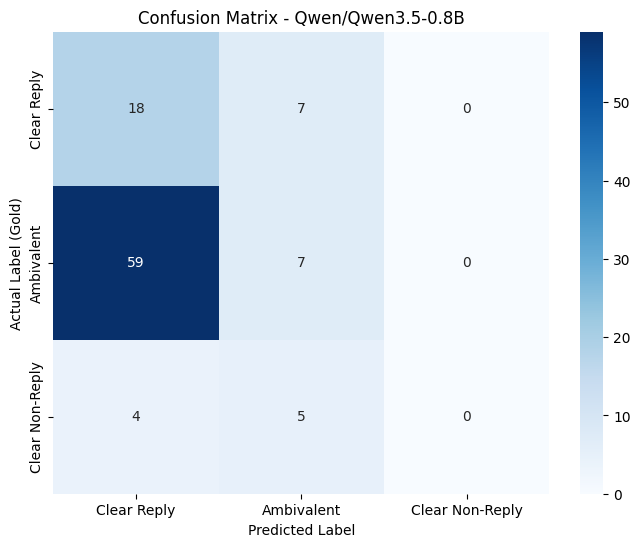

,Accuracy,Precision,Recall,F1-Score,Macro F1-Score,Confusion_Matrix,Labels,Inference_Time_Sec,Sec_per_Sample
Qwen/Qwen3.5-0.8B,0.25,0.298713,0.25,0.193612,0.16811,"[[18, 7, 0], [59, 7, 0], [4, 5, 0]]","[Clear Reply, Ambivalent, Clear Non-Reply]",57.42,0.5742


Loading model and tokenizer for: Qwen/Qwen3.5-2B


config.json:   0%|          | 0.00/2.91k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/6.72M [00:00<?, ?B/s]

...

chat_template.jinja:   0%|          | 0.00/7.75k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/64.5k [00:00<?, ?B/s]

model.safetensors-00001-of-00001.safeten(…):   0%|          | 0.00/4.55G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Preparing prompts for 100 examples...
--------full_text:--------
<|im_start|>system
You are an expert analyzing political interviews. Output exactly one label: Clear Reply, Ambivalent, or Clear Non-Reply.

HOW TO CLASSIFY (Read carefully):

Step 1: Check for Clear Non-Reply
Does the politician completely ignore the specific question? Do they change the topic entirely, attack someone else, or just say a meaningless word like "Okay"?
If YES -> Output: Clear Non-Reply

Step 2: Check for Ambivalent
Does the politician talk about the topic, but their answer is vague, half-finished, or avoids a direct commitment?
If YES -> Output: Ambivalent

Step 3: Check for Clear Reply
Does the politician give a clear, direct, and factual answer to the exact question asked?
If YES -> Output: Clear Reply

Output ONLY the exact label name. Do not explain.<|im_end|>
<|im_start|>user
Question: What kind of punishment would you like to see imposed on North Korea, short of some sort of condemnation from the U.N

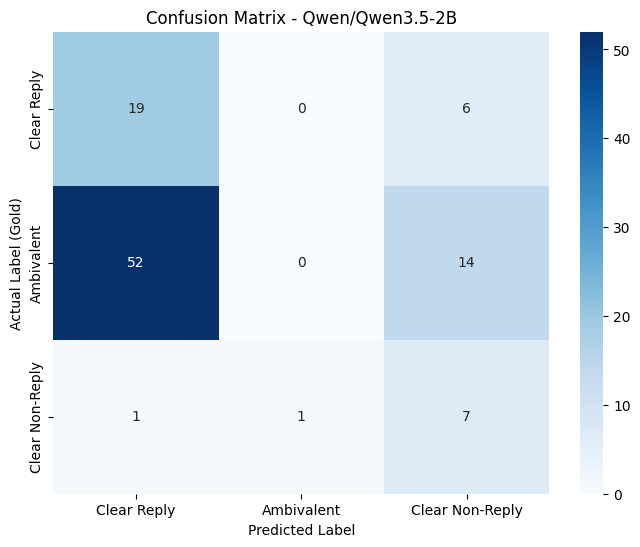

,Accuracy,Precision,Recall,F1-Score,Macro F1-Score,Confusion_Matrix,Labels,Inference_Time_Sec,Sec_per_Sample
Qwen/Qwen3.5-0.8B,0.25,0.298713,0.25,0.193612,0.16811,"[[18, 7, 0], [59, 7, 0], [4, 5, 0]]","[Clear Reply, Ambivalent, Clear Non-Reply]",57.42,0.5742
Qwen/Qwen3.5-2B,0.26,0.089306,0.26,0.132938,0.260214,"[[19, 0, 6], [52, 0, 14], [1, 1, 7]]","[Clear Reply, Ambivalent, Clear Non-Reply]",151.6,1.516


Loading model and tokenizer for: Qwen/Qwen3.5-4B


config.json:   0%|          | 0.00/3.16k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/6.72M [00:00<?, ?B/s]

...

chat_template.jinja:   0%|          | 0.00/7.76k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/76.2k [00:00<?, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/426 [00:00<?, ?it/s]

Preparing prompts for 100 examples...
--------full_text:--------
<|im_start|>system
You are an expert political discourse analyst evaluating interview transcripts. Classify the politician's answer into EXACTLY ONE of the following three categories:
- Clear Reply
- Ambivalent
- Clear Non-Reply

Follow this strict step-by-step reasoning process:

STEP 1 — Check for Clear Non-Reply (Apply strictly and conservatively):
Does the answer fail completely to engage with the actual core question?
- The politician completely ignores the premise of the question.
- They redirect entirely to a different subject or their own unrelated talking points (political pivoting).
- They attack the opponent or interviewer instead of answering.
- They explicitly refuse to answer (e.g., "I cannot comment on that", "I won't get into that").
If clearly YES -> Clear Non-Reply

STEP 2 — Distinguish Clear Reply from Ambivalent (The most critical distinction):
First, identify the exact information requested by the que

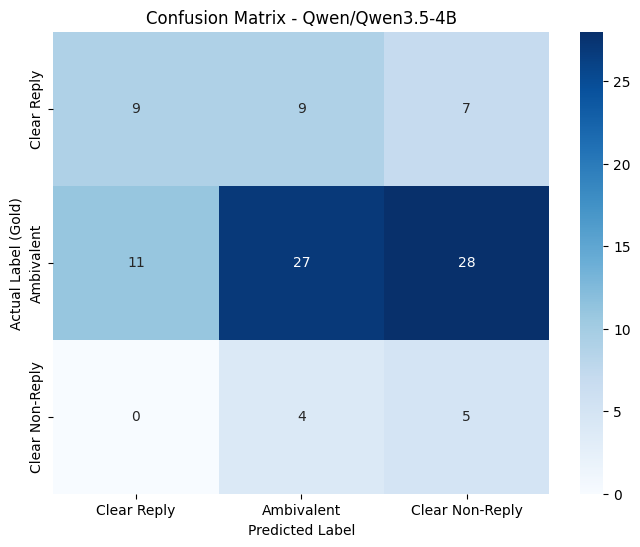

,Accuracy,Precision,Recall,F1-Score,Macro F1-Score,Confusion_Matrix,Labels,Inference_Time_Sec,Sec_per_Sample
Qwen/Qwen3.5-0.8B,0.25,0.298713,0.25,0.193612,0.16811,"[[18, 7, 0], [59, 7, 0], [4, 5, 0]]","[Clear Reply, Ambivalent, Clear Non-Reply]",57.42,0.5742
Qwen/Qwen3.5-2B,0.26,0.089306,0.26,0.132938,0.260214,"[[19, 0, 6], [52, 0, 14], [1, 1, 7]]","[Clear Reply, Ambivalent, Clear Non-Reply]",151.6,1.516
Qwen/Qwen3.5-4B,0.41,0.56925,0.41,0.454594,0.371172,"[[9, 9, 7], [11, 27, 28], [0, 4, 5]]","[Clear Reply, Ambivalent, Clear Non-Reply]",472.56,4.7256


In [16]:
# model_names = ["Qwen/Qwen3.5-0.8B", "Qwen/Qwen3.5-2B", "Qwen/Qwen3.5-4B"] 
# all_metrics = {}

# for name in model_names:
#     gc.collect()
#     torch.cuda.empty_cache()
#     bnb_config = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.bfloat16, bnb_4bit_use_double_quant=True,)
#     print(f"Loading model and tokenizer for: {name}")

#     tokenizer = AutoTokenizer.from_pretrained(name)
#     tokenizer.padding_side = "left"
#     if tokenizer.pad_token is None:
#         tokenizer.pad_token = tokenizer.eos_token
#     model = AutoModelForCausalLM.from_pretrained(name, quantization_config=bnb_config, device_map="auto", trust_remote_code=True)

#     if torch.cuda.is_available():
#         torch.cuda.synchronize()
#     start_time = time.time()

#     if name == "Qwen/Qwen3.5-0.8B":
#         p_type = "zero-shot"
#         max_t = 10
#     elif name == "Qwen/Qwen3.5-2B":
#         p_type = "zero-shot-2b"
#         max_t = 10
#     elif name == "Qwen/Qwen3.5-4B":
#         p_type = "zero-shot-4b"
#         max_t = 10

#     results = run_exp1(model, tokenizer, stratified_subset, prompt_type=p_type, max_tokens=max_t, sample=False, batch_size=8)

#     if torch.cuda.is_available():
#         torch.cuda.synchronize()
#     end_time = time.time()
#     elapsed_time = end_time - start_time

#     metrics = calculate_metrics(results)
#     metrics['Inference_Time_Sec'] = round(elapsed_time, 2)
#     metrics['Sec_per_Sample'] = round(elapsed_time / num_samples, 4)
#     all_metrics[name] = metrics

#     print(f"Model {name} finished in {elapsed_time:.2f}s")
#     plot_confusion_matrix(results, model_name=name)

#     del model
#     del tokenizer
#     gc.collect()
#     torch.cuda.empty_cache()
#     time.sleep(2)

#     # submission_df = create_submission_csv(results, stratified_subset, name, p_type)

#     df_comparison = pd.DataFrame(all_metrics).T
#     display(df_comparison)

### Experiment 2 in models qwen3.5-0.8B, qwen3.5-2B and qwen3.5-4B

In [17]:
# def define_system_promt_exp2(prompt_type="zero-shot"): 
#     if prompt_type == "zero-shot":
#         system_prompt = """You are a political discourse analyst. Your task is to classify the clarity of a politician's answer to a given question.

# Read the question and the answer carefully, then classify the answer into exactly one of the following categories:

# - Clear Reply: The politician directly and explicitly addresses the question asked.
# - Ambivalent: The politician partially addresses the question but remains vague or non-committal.
# - Clear Non-Reply: The politician avoids or completely ignores the question.

#  Respond with ONLY the label.""" # 1

#         return system_prompt

#     elif prompt_type == "zero-shot-2b": 
#         system_prompt = """You are a political discourse analyst. Classify a politician's answer into EXACTLY ONE of:
#  - Clear Reply
#  - Ambivalent
#  - Clear Non-Reply

#  CRITICAL CALIBRATION — real distribution of political interview answers:
#  - Ambivalent:      66% of answers  <- by far the most common
#  - Clear Reply:     25% of answers  <- moderately common
#  - Clear Non-Reply:  9% of answers  <- very rare

#  This means: when you are unsure, Ambivalent is almost always correct.
#  Only classify as Clear Non-Reply if the politician COMPLETELY ignores the topic — this is rare.

#  DEFINITIONS:

#  Ambivalent (66% — your DEFAULT choice):
#  The politician engages with the topic but gives a vague, partial, incomplete, or non-committal answer.
#  Long answers that hedge, use "I think / we're working on / it depends / we'll see" are Ambivalent.
#  If you are not sure -> Ambivalent.

#  Clear Reply (25%):
#  The politician gives a specific, direct answer to the exact question: a fact, a number, a yes/no, a concrete commitment.
#  Short, direct answers that fully satisfy what the question asked.

#  Clear Non-Reply (9% — extremely rare, use with caution):
#  The politician does NOT engage with the topic at all.
#  They completely change the subject, say almost nothing, or attack someone unrelated.
#  If the politician mentions the topic even vaguely -> NOT a Clear Non-Reply.

#  Respond with ONLY the label."""  # 2
        
#         return system_prompt

#     elif prompt_type == "zero-shot-4b": 
#         system_prompt = """You are a political discourse analyst. Classify a politician's answer into EXACTLY ONE of:
# - Clear Reply
# - Ambivalent
# - Clear Non-Reply

# REAL DISTRIBUTION:
# - Ambivalent:       66%  <- default
# - Clear Reply:      25%  <- do NOT suppress this
# - Clear Non-Reply:   9%  <- very rare

# STEP 1 — Check for Clear Non-Reply:
# Does the answer fail to mention the topic of the question at all?
# Does the politician redirect entirely to a completely different subject?
# Only if clearly YES -> Clear Non-Reply (~9% — be very conservative)
# NOTE: short answers are NOT automatically Clear Non-Reply.
# If the politician mentions the topic even once -> NOT Clear Non-Reply.

# STEP 2 — Distinguish Clear Reply from Ambivalent:
# Ask: does the answer DIRECTLY satisfy what the question asked for?

# Clear Reply signals — ANY ONE is enough:
#   * States a direct yes or no
#   * Gives a specific number, date, name, or concrete plan
#   * Makes a concrete commitment ("I will / I won't / I have decided")
#   * Directly explains WHY or HOW with a specific reason that answers the question
#   * The first sentence already answers the question directly

# IMPORTANT: A Clear Reply CAN be long.
# Length alone does NOT make an answer Ambivalent.
# If the core question is answered directly at ANY point -> Clear Reply.

# Ambivalent signals:
#   - Talks about the topic but never delivers the specific information asked
#   - Uses hedging: "I think", "probably", "we are working on", "it depends", "we'll see"
#   - Addresses the general topic without answering the exact question
#   - Gives background and context but no direct position or answer

# Respond with ONLY the label.""" # 4

#         return system_prompt

# def build_prompt_exp2(example, prompt_type="zero-shot"):
#     if prompt_type in ["zero-shot", "zero-shot-2b", "zero-shot-4b"]:
#         return f"""Question: {example["question"]}\nAnswer: {example["interview_answer"]}\nLabel:"""
#     elif prompt_type in ["few-shot", "few-shot-2b", "few-shot-4b"]:
#         return f"Question: {example['question']}\nAnswer: {example['interview_answer']}\nLabel:" 
#     else: # GoT
#         return f"Question: {example['question']}\nAnswer: {example['interview_answer']}" 

# def run_exp2(model, tokenizer, data_split, prompt_type="zero-shot", max_tokens=10, sample=False, batch_size=8):
#     tokenizer.padding_side = "left"
#     if tokenizer.pad_token is None:
#         tokenizer.pad_token = tokenizer.eos_token

#     print(f"Preparing prompts for {len(data_split)} examples...")
#     prompts = []
#     system_prompt = define_system_promt_exp2(prompt_type)

#     for example in data_split:
#         if prompt_type in ["few-shot", "few-shot-2b", "few-shot-4b"]:
#             messages = [{"role": "system", "content": system_prompt}]

#             if few_shot_examples:
#                 for demo in few_shot_examples:
#                     messages.append({
#                         "role": "user",
#                         "content": f"Question: {demo['question']}\nAnswer: {demo['answer']}"
#                     })
#                     messages.append({
#                         "role": "assistant",
#                         "content": f"Label: {demo['label']}"
#                         # "content": demo['label']
#                     })

#             messages.append({
#                 "role": "user",
#                 "content": build_prompt_exp2(example, prompt_type)
#             })
#         elif prompt_type in ["zero-shot-COT-0.8b"]:
#             messages = [
#                 {"role": "system", "content": system_prompt},
#                 {"role": "user", "content": f"{build_prompt_exp2(example, prompt_type)}"}
#             ]
#         elif prompt_type in ["few-shot-COT-0.8b", "COT-2b", "COT-4b"]:
#             messages = [{"role": "system", "content": system_prompt}]

#             if few_shot_cot_examples:
#                 for demo in few_shot_cot_examples:
#                     messages.append({
#                         "role": "user",
#                         "content": f"Question: {demo['question']}\nAnswer: {demo['answer']}" # \nLet's think step by step.
#                     })
#                     messages.append({
#                         "role": "assistant",
#                         "content": f"Reasoning: {demo['reasoning']}\nLabel: {demo['label']}"
#                     })

#             messages.append({
#                 "role": "user",
#                 "content": build_prompt_exp2(example, prompt_type)
#             })
#         else: # zero-shot
#             messages = [
#                 {"role": "system", "content": system_prompt},
#                 {"role": "user", "content": f"{build_prompt_exp2(example, prompt_type)}"}
#             ]
#         full_text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True, enable_thinking=False)
#         prompts.append(full_text)
#     print("--------full_text:--------")
#     print(full_text)
#     print("---------------------")

#     results = []
#     model.eval()
#     total_batches = (len(prompts) + batch_size - 1) // batch_size

#     print(f"Starting inference (Total batches: {total_batches}, Batch size: {batch_size})...")

#     for i in range(0, len(prompts), batch_size):
#         current_batch_idx = (i // batch_size) + 1
#         batch_prompts = prompts[i : i + batch_size]
#         batch_data = data_split.select(range(i, min(i + batch_size, len(data_split))))

#         inputs = tokenizer(batch_prompts, return_tensors="pt", padding=True).to(model.device)


#         stop_token_id = tokenizer.convert_tokens_to_ids('\n')
#         eos_ids = []
#         if tokenizer.eos_token_id is not None:
#             eos_ids.append(tokenizer.eos_token_id)
#         if stop_token_id is not None:
#             eos_ids.append(stop_token_id)

#         with torch.no_grad():
#             outputs = model.generate(
#                 **inputs,
#                 max_new_tokens=max_tokens,
#                 do_sample=sample,   
#                 # temperature=0.3, 
#                 pad_token_id=tokenizer.pad_token_id or tokenizer.eos_token_id,
#                 eos_token_id=eos_ids, 
#             )


#         for j, output in enumerate(outputs):
#             raw_text = tokenizer.decode(output[inputs["input_ids"].shape[1]:], skip_special_tokens=True)
#             gold_label_int = batch_data[j]["clarity_label"]
#             gold_label_str = data_split.features["clarity_label"].int2str(gold_label_int)

#             if prompt_type in ["few-shot-COT-0.8b", "zero-shot-COT-0.8b", "COT-2b", "COT-4b"]:
#                 match = re.search(r'Label:\s*(.*)', raw_text, re.IGNORECASE)
#                 if match:
#                     extracted = match.group(1).strip()
#                     if "Clear Non-Reply" in extracted:
#                         generated_text = "Clear Non-Reply"
#                     elif "Clear Reply" in extracted:
#                         generated_text = "Clear Reply"
#                     elif "Ambivalent" in extracted:
#                         generated_text = "Ambivalent"
#                     else:
#                         print("Parsing Error")
#                         generated_text = "Parsing Error"
#                 else:
#                     print("Parsing Error")
#                     generated_text = "Parsing Error"
#             elif prompt_type in ["zero-shot", "zero-shot-2b", "few-shot-4b", "few-shot", "few-shot-2b", "zero-shot-4b"]:
#                 if "Clear Non-Reply" in raw_text:
#                     generated_text = "Clear Non-Reply"
#                 elif "Clear Reply" in raw_text:
#                     generated_text = "Clear Reply"
#                 elif "Ambivalent" in raw_text:
#                     generated_text = "Ambivalent"
#                 else:
#                     generated_text = normalize_prediction(raw_text).strip()

#             # print("Predicted: ", generated_text.strip())
#             # print("True Label: ", gold_label_str)
#             # print("---\n")

#             # print(f"Question: {batch_data[j]['question']}")
#             # print(f"Answer: {batch_data[j]['interview_answer']}")
#             # print(f"Qwen Raw Output: {raw_text.strip()}")
#             # print(f"Parsed Prediction: {generated_text.strip()}")
#             # print(f"True Label: {gold_label_str}")
#             # print("-" * 50 + "\n")

#             results.append({
#                 "question": batch_data[j]["question"],
#                 "interview_answer": batch_data[j]["interview_answer"],
#                 "prediction": generated_text.strip(),
#                 "gold_label": batch_data[j]["clarity_label"]
#             })

#         if current_batch_idx % 1 == 0 or current_batch_idx == total_batches:
#             processed_examples = min(i + batch_size, len(prompts))
#             print(f"Batch {current_batch_idx}/{total_batches} completed. Processed {processed_examples}/{len(prompts)} examples.")

#     print("Inference finished successfully.")
#     return results        

Loading model and tokenizer for: Qwen/Qwen3.5-0.8B


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Preparing prompts for 100 examples...
--------full_text:--------
<|im_start|>system
You are a political discourse analyst. Your task is to classify the clarity of a politician's answer to a given question.

Read the question and the answer carefully, then classify the answer into exactly one of the following categories:

- Clear Reply: The politician directly and explicitly addresses the question asked.
- Ambivalent: The politician partially addresses the question but remains vague or non-committal.
- Clear Non-Reply: The politician avoids or completely ignores the question.

 Respond with ONLY the label.<|im_end|>
<|im_start|>user
Question: What kind of punishment would you like to see imposed on North Korea, short of some sort of condemnation from the U.N. Security Council
Answer: Okay.
Label:<|im_end|>
<|im_start|>assistant
<think>

</think>


---------------------
Starting inference (Total batches: 13, Batch size: 8)...
Batch 1/13 completed. Processed 8/100 examples.
Batch 2/13 com

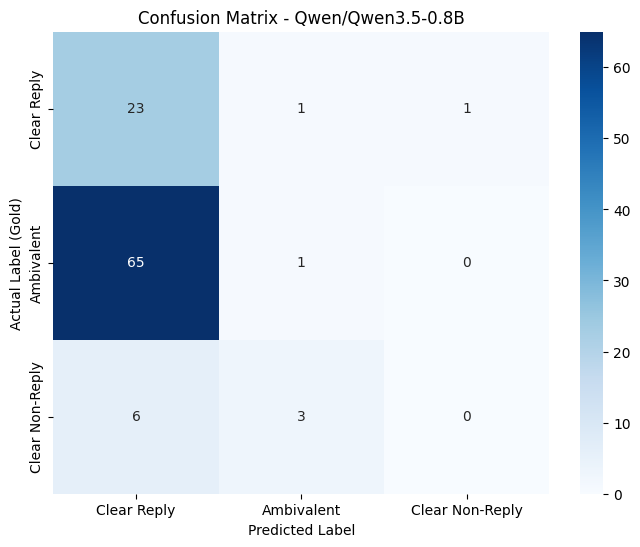

,Accuracy,Precision,Recall,F1-Score,Macro F1-Score,Confusion_Matrix,Labels,Inference_Time_Sec,Sec_per_Sample
Qwen/Qwen3.5-0.8B,0.24,0.19317,0.24,0.11523,0.138241,"[[23, 1, 1], [65, 1, 0], [6, 3, 0]]","[Clear Reply, Ambivalent, Clear Non-Reply]",62.62,0.6262


Loading model and tokenizer for: Qwen/Qwen3.5-2B


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Preparing prompts for 100 examples...
--------full_text:--------
<|im_start|>system
You are a political discourse analyst. Classify a politician's answer into EXACTLY ONE of:
 - Clear Reply
 - Ambivalent
 - Clear Non-Reply

 CRITICAL CALIBRATION — real distribution of political interview answers:
 - Ambivalent:      66% of answers  <- by far the most common
 - Clear Reply:     25% of answers  <- moderately common
 - Clear Non-Reply:  9% of answers  <- very rare

 This means: when you are unsure, Ambivalent is almost always correct.
 Only classify as Clear Non-Reply if the politician COMPLETELY ignores the topic — this is rare.

 DEFINITIONS:

 Ambivalent (66% — your DEFAULT choice):
 The politician engages with the topic but gives a vague, partial, incomplete, or non-committal answer.
 Long answers that hedge, use "I think / we're working on / it depends / we'll see" are Ambivalent.
 If you are not sure -> Ambivalent.

 Clear Reply (25%):
 The politician gives a specific, direct answer

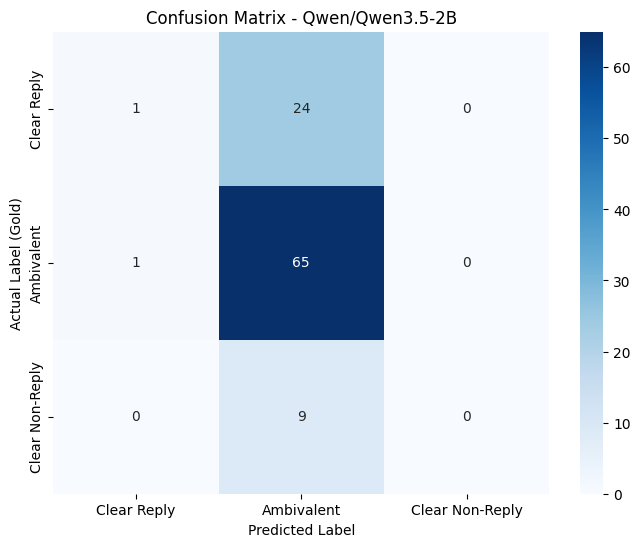

,Accuracy,Precision,Recall,F1-Score,Macro F1-Score,Confusion_Matrix,Labels,Inference_Time_Sec,Sec_per_Sample
Qwen/Qwen3.5-0.8B,0.24,0.19317,0.24,0.11523,0.138241,"[[23, 1, 1], [65, 1, 0], [6, 3, 0]]","[Clear Reply, Ambivalent, Clear Non-Reply]",62.62,0.6262
Qwen/Qwen3.5-2B,0.66,0.562755,0.66,0.541689,0.288919,"[[1, 24, 0], [1, 65, 0], [0, 9, 0]]","[Clear Reply, Ambivalent, Clear Non-Reply]",169.97,1.6997


Loading model and tokenizer for: Qwen/Qwen3.5-4B


Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/426 [00:00<?, ?it/s]

Preparing prompts for 100 examples...
--------full_text:--------
<|im_start|>system
You are a political discourse analyst. Classify a politician's answer into EXACTLY ONE of:
- Clear Reply
- Ambivalent
- Clear Non-Reply

REAL DISTRIBUTION:
- Ambivalent:       66%  <- default
- Clear Reply:      25%  <- do NOT suppress this
- Clear Non-Reply:   9%  <- very rare

STEP 1 — Check for Clear Non-Reply:
Does the answer fail to mention the topic of the question at all?
Does the politician redirect entirely to a completely different subject?
Only if clearly YES -> Clear Non-Reply (~9% — be very conservative)
NOTE: short answers are NOT automatically Clear Non-Reply.
If the politician mentions the topic even once -> NOT Clear Non-Reply.

STEP 2 — Distinguish Clear Reply from Ambivalent:
Ask: does the answer DIRECTLY satisfy what the question asked for?

Clear Reply signals — ANY ONE is enough:
  * States a direct yes or no
  * Gives a specific number, date, name, or concrete plan
  * Makes a con

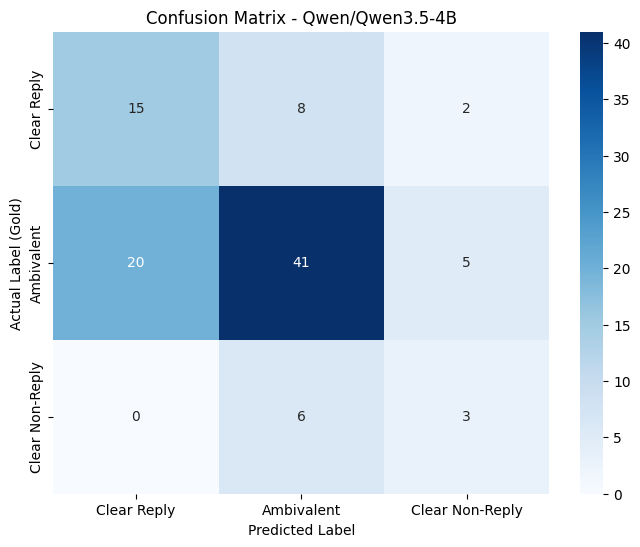

,Accuracy,Precision,Recall,F1-Score,Macro F1-Score,Confusion_Matrix,Labels,Inference_Time_Sec,Sec_per_Sample
Qwen/Qwen3.5-0.8B,0.24,0.19317,0.24,0.11523,0.138241,"[[23, 1, 1], [65, 1, 0], [6, 3, 0]]","[Clear Reply, Ambivalent, Clear Non-Reply]",62.62,0.6262
Qwen/Qwen3.5-2B,0.66,0.562755,0.66,0.541689,0.288919,"[[1, 24, 0], [1, 65, 0], [0, 9, 0]]","[Clear Reply, Ambivalent, Clear Non-Reply]",169.97,1.6997
Qwen/Qwen3.5-4B,0.59,0.626143,0.59,0.600694,0.497825,"[[15, 8, 2], [20, 41, 5], [0, 6, 3]]","[Clear Reply, Ambivalent, Clear Non-Reply]",468.32,4.6832


In [18]:
# model_names = ["Qwen/Qwen3.5-0.8B", "Qwen/Qwen3.5-2B", "Qwen/Qwen3.5-4B"]
# all_metrics = {}

# for name in model_names:
#     gc.collect()
#     torch.cuda.empty_cache()
#     bnb_config = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.bfloat16, bnb_4bit_use_double_quant=True,)
#     print(f"Loading model and tokenizer for: {name}")

#     tokenizer = AutoTokenizer.from_pretrained(name)
#     tokenizer.padding_side = "left"
#     if tokenizer.pad_token is None:
#         tokenizer.pad_token = tokenizer.eos_token
#     model = AutoModelForCausalLM.from_pretrained(name, quantization_config=bnb_config, device_map="auto", trust_remote_code=True)

#     if torch.cuda.is_available():
#         torch.cuda.synchronize()
#     start_time = time.time()

#     if name == "Qwen/Qwen3.5-0.8B":
#         p_type = "zero-shot"
#         max_t = 10
#     elif name == "Qwen/Qwen3.5-2B":
#         p_type = "zero-shot-2b"
#         max_t = 10
#     elif name == "Qwen/Qwen3.5-4B":
#         p_type = "zero-shot-4b"
#         max_t = 10

#     results = run_exp2(model, tokenizer, stratified_subset, prompt_type=p_type, max_tokens=max_t, sample=False, batch_size=8)

#     if torch.cuda.is_available():
#         torch.cuda.synchronize()
#     end_time = time.time()
#     elapsed_time = end_time - start_time

#     metrics = calculate_metrics(results)
#     metrics['Inference_Time_Sec'] = round(elapsed_time, 2)
#     metrics['Sec_per_Sample'] = round(elapsed_time / num_samples, 4)
#     all_metrics[name] = metrics

#     print(f"Model {name} finished in {elapsed_time:.2f}s")
#     plot_confusion_matrix(results, model_name=name)

#     del model
#     del tokenizer
#     gc.collect()
#     torch.cuda.empty_cache()
#     time.sleep(2)

#     # submission_df = create_submission_csv(results, stratified_subset, name, p_type)

#     df_comparison = pd.DataFrame(all_metrics).T
#     display(df_comparison)

### Experiment 3 in models qwen3.5-0.8B, qwen3.5-2B and qwen3.5-4B

In [19]:
# def define_system_promt_exp3(prompt_type="zero-shot"): 
#     if prompt_type == "zero-shot":
#         system_prompt = """You are a strict political discourse analyst. Classify the answer into EXACTLY ONE category:
# - Clear Reply
# - Ambivalent
# - Clear Non-Reply

# CRITICAL RULE:
# Most political answers are "Ambivalent". You must DEFAULT to "Ambivalent" unless the politician provides a specific, concrete fact or a direct yes/no. 
# If the politician completely changes the subject, choose "Clear Non-Reply".
# Do not choose "Clear Reply" just because the answer is long or polite.

# Output ONLY the exact label name. Do not explain.""" 

#         return system_prompt

# def build_prompt_exp3(example, prompt_type="zero-shot"):
#     if prompt_type in ["zero-shot", "zero-shot-2b", "zero-shot-4b"]:
#         return f"""Question: {example["question"]}\nAnswer: {example["interview_answer"]}\nLabel:"""
#     elif prompt_type in ["few-shot", "few-shot-2b", "few-shot-4b"]:
#         return f"Question: {example['question']}\nAnswer: {example['interview_answer']}\nLabel:" 
#     else: # GoT
#         return f"Question: {example['question']}\nAnswer: {example['interview_answer']}" 

# def run_exp3(model, tokenizer, data_split, prompt_type="zero-shot", max_tokens=10, sample=False, batch_size=8):
#     tokenizer.padding_side = "left"
#     if tokenizer.pad_token is None:
#         tokenizer.pad_token = tokenizer.eos_token

#     print(f"Preparing prompts for {len(data_split)} examples...")
#     prompts = []
#     system_prompt = define_system_promt_exp3(prompt_type)

#     for example in data_split:
#         if prompt_type in ["few-shot", "few-shot-2b", "few-shot-4b"]:
#             messages = [{"role": "system", "content": system_prompt}]

#             if few_shot_examples:
#                 for demo in few_shot_examples:
#                     messages.append({
#                         "role": "user",
#                         "content": f"Question: {demo['question']}\nAnswer: {demo['answer']}"
#                     })
#                     messages.append({
#                         "role": "assistant",
#                         "content": f"Label: {demo['label']}"
#                         # "content": demo['label']
#                     })

#             messages.append({
#                 "role": "user",
#                 "content": build_prompt_exp3(example, prompt_type)
#             })
#         elif prompt_type in ["zero-shot-COT-0.8b"]:
#             messages = [
#                 {"role": "system", "content": system_prompt},
#                 {"role": "user", "content": f"{build_prompt_exp3(example, prompt_type)}"}
#             ]
#         elif prompt_type in ["few-shot-COT-0.8b", "COT-2b", "COT-4b"]:
#             messages = [{"role": "system", "content": system_prompt}]

#             if few_shot_cot_examples:
#                 for demo in few_shot_cot_examples:
#                     messages.append({
#                         "role": "user",
#                         "content": f"Question: {demo['question']}\nAnswer: {demo['answer']}" # \nLet's think step by step.
#                     })
#                     messages.append({
#                         "role": "assistant",
#                         "content": f"Reasoning: {demo['reasoning']}\nLabel: {demo['label']}"
#                     })

#             messages.append({
#                 "role": "user",
#                 "content": build_prompt_exp3(example, prompt_type)
#             })
#         else: # zero-shot
#             messages = [
#                 {"role": "system", "content": system_prompt},
#                 {"role": "user", "content": f"{build_prompt_exp3(example, prompt_type)}"}
#             ]
#         full_text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True, enable_thinking=False)
#         prompts.append(full_text)
#     print("--------full_text:--------")
#     print(full_text)
#     print("---------------------")

#     results = []
#     model.eval()
#     total_batches = (len(prompts) + batch_size - 1) // batch_size

#     print(f"Starting inference (Total batches: {total_batches}, Batch size: {batch_size})...")

#     for i in range(0, len(prompts), batch_size):
#         current_batch_idx = (i // batch_size) + 1
#         batch_prompts = prompts[i : i + batch_size]
#         batch_data = data_split.select(range(i, min(i + batch_size, len(data_split))))

#         inputs = tokenizer(batch_prompts, return_tensors="pt", padding=True).to(model.device)


#         stop_token_id = tokenizer.convert_tokens_to_ids('\n')
#         eos_ids = []
#         if tokenizer.eos_token_id is not None:
#             eos_ids.append(tokenizer.eos_token_id)
#         if stop_token_id is not None:
#             eos_ids.append(stop_token_id)

#         with torch.no_grad():
#             outputs = model.generate(
#                 **inputs,
#                 max_new_tokens=max_tokens,
#                 do_sample=sample,   
#                 # temperature=0.3,
#                 pad_token_id=tokenizer.pad_token_id or tokenizer.eos_token_id,
#                 eos_token_id=eos_ids, 
#             )


#         for j, output in enumerate(outputs):
#             raw_text = tokenizer.decode(output[inputs["input_ids"].shape[1]:], skip_special_tokens=True)
#             gold_label_int = batch_data[j]["clarity_label"]
#             gold_label_str = data_split.features["clarity_label"].int2str(gold_label_int)

#             if prompt_type in ["few-shot-COT-0.8b", "zero-shot-COT-0.8b", "COT-2b", "COT-4b"]:
#                 match = re.search(r'Label:\s*(.*)', raw_text, re.IGNORECASE)
#                 if match:
#                     extracted = match.group(1).strip()
#                     if "Clear Non-Reply" in extracted:
#                         generated_text = "Clear Non-Reply"
#                     elif "Clear Reply" in extracted:
#                         generated_text = "Clear Reply"
#                     elif "Ambivalent" in extracted:
#                         generated_text = "Ambivalent"
#                     else:
#                         print("Parsing Error")
#                         generated_text = "Parsing Error"
#                 else:
#                     print("Parsing Error")
#                     generated_text = "Parsing Error"
#             elif prompt_type in ["zero-shot", "zero-shot-2b", "few-shot-4b", "few-shot", "few-shot-2b", "zero-shot-4b"]:
#                 if "Clear Non-Reply" in raw_text:
#                     generated_text = "Clear Non-Reply"
#                 elif "Clear Reply" in raw_text:
#                     generated_text = "Clear Reply"
#                 elif "Ambivalent" in raw_text:
#                     generated_text = "Ambivalent"
#                 else:
#                     generated_text = normalize_prediction(raw_text).strip()

#             # print("Predicted: ", generated_text.strip())
#             # print("True Label: ", gold_label_str)
#             # print("---\n")

#             # print(f"Question: {batch_data[j]['question']}")
#             # print(f"Answer: {batch_data[j]['interview_answer']}")
#             # print(f"Qwen Raw Output: {raw_text.strip()}")
#             # print(f"Parsed Prediction: {generated_text.strip()}")
#             # print(f"True Label: {gold_label_str}")
#             # print("-" * 50 + "\n")

#             results.append({
#                 "question": batch_data[j]["question"],
#                 "interview_answer": batch_data[j]["interview_answer"],
#                 "prediction": generated_text.strip(),
#                 "gold_label": batch_data[j]["clarity_label"]
#             })

#         if current_batch_idx % 1 == 0 or current_batch_idx == total_batches:
#             processed_examples = min(i + batch_size, len(prompts))
#             print(f"Batch {current_batch_idx}/{total_batches} completed. Processed {processed_examples}/{len(prompts)} examples.")

#     print("Inference finished successfully.")
#     return results        

Loading model and tokenizer for: Qwen/Qwen3.5-0.8B


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Preparing prompts for 100 examples...
--------full_text:--------
<|im_start|>system
You are a strict political discourse analyst. Classify the answer into EXACTLY ONE category:
- Clear Reply
- Ambivalent
- Clear Non-Reply

CRITICAL RULE:
Most political answers are "Ambivalent". You must DEFAULT to "Ambivalent" unless the politician provides a specific, concrete fact or a direct yes/no. 
If the politician completely changes the subject, choose "Clear Non-Reply".
Do not choose "Clear Reply" just because the answer is long or polite.

Output ONLY the exact label name. Do not explain.<|im_end|>
<|im_start|>user
Question: What kind of punishment would you like to see imposed on North Korea, short of some sort of condemnation from the U.N. Security Council
Answer: Okay.
Label:<|im_end|>
<|im_start|>assistant
<think>

</think>


---------------------
Starting inference (Total batches: 13, Batch size: 8)...
Batch 1/13 completed. Processed 8/100 examples.
Batch 2/13 completed. Processed 16/100 

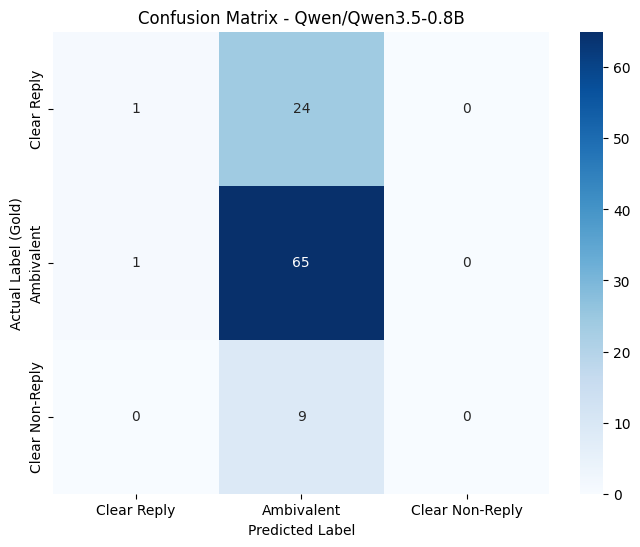

,Accuracy,Precision,Recall,F1-Score,Macro F1-Score,Confusion_Matrix,Labels,Inference_Time_Sec,Sec_per_Sample
Qwen/Qwen3.5-0.8B,0.66,0.562755,0.66,0.541689,0.288919,"[[1, 24, 0], [1, 65, 0], [0, 9, 0]]","[Clear Reply, Ambivalent, Clear Non-Reply]",62.91,0.6291


In [20]:
# model_names = ["Qwen/Qwen3.5-0.8B"] 
# all_metrics = {}

# for name in model_names:
#     gc.collect()
#     torch.cuda.empty_cache()
#     bnb_config = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.bfloat16, bnb_4bit_use_double_quant=True,)
#     print(f"Loading model and tokenizer for: {name}")

#     tokenizer = AutoTokenizer.from_pretrained(name)
#     tokenizer.padding_side = "left"
#     if tokenizer.pad_token is None:
#         tokenizer.pad_token = tokenizer.eos_token
#     model = AutoModelForCausalLM.from_pretrained(name, quantization_config=bnb_config, device_map="auto", trust_remote_code=True)

#     if torch.cuda.is_available():
#         torch.cuda.synchronize()
#     start_time = time.time()

#     if name == "Qwen/Qwen3.5-0.8B":
#         p_type = "zero-shot"
#         max_t = 10
#     elif name == "Qwen/Qwen3.5-2B":
#         p_type = "zero-shot-2b"
#         max_t = 10
#     elif name == "Qwen/Qwen3.5-4B":
#         p_type = "zero-shot-4b"
#         max_t = 10

#     results = run_exp3(model, tokenizer, stratified_subset, prompt_type=p_type, max_tokens=max_t, sample=False, batch_size=8)

#     if torch.cuda.is_available():
#         torch.cuda.synchronize()
#     end_time = time.time()
#     elapsed_time = end_time - start_time

#     metrics = calculate_metrics(results)
#     metrics['Inference_Time_Sec'] = round(elapsed_time, 2)
#     metrics['Sec_per_Sample'] = round(elapsed_time / num_samples, 4)
#     all_metrics[name] = metrics

#     print(f"Model {name} finished in {elapsed_time:.2f}s")
#     plot_confusion_matrix(results, model_name=name)

#     del model
#     del tokenizer
#     gc.collect()
#     torch.cuda.empty_cache()
#     time.sleep(2)

#     # submission_df = create_submission_csv(results, stratified_subset, name, p_type)

#     df_comparison = pd.DataFrame(all_metrics).T
#     display(df_comparison)

## Using few-shot prompting method 

### Experiment 1 in models qwen3.5-0.8B, qwen3.5-2B and qwen3.5-4B

In [32]:
# train_df = dataset["train"].to_pandas()
# train_df['total_length'] = train_df['question'].str.len() + train_df['interview_answer'].str.len()
# selected_indices = {}
# labels = ["Clear Reply", "Ambivalent", "Clear Non-Reply"]

# for label in labels:
#     subset = train_df[train_df['clarity_label'] == label].sort_values('total_length')
#     n = len(subset)
#     if n >= 3: # if n >= 5:
#         shortest = subset.index[0]
#         # longest = subset.index[-1]
#         mid_positions = np.linspace(n // 4, 3 * n // 4, 2, dtype=int)
#         middle_idxs = subset.index[mid_positions].tolist()
#         # all_for_label = [int(i) for i in middle_idxs] + [int(longest)] # [int(shortest)] + 
#         # all_for_label = [int(shortest)]  
#         all_for_label = [int(i) for i in middle_idxs] + [int(shortest)]  
#         selected_indices[label] = list(dict.fromkeys(all_for_label))
# for label, idxs in selected_indices.items():
#     print(f"'{label}': {idxs},")

'Clear Reply': [3109, 2773, 837],
'Ambivalent': [2633, 2531, 2022],
'Clear Non-Reply': [2621, 192, 429],


In [33]:
# def get_few_shot_examples(dataset):
#     selected_indices = {
#         "Clear Reply":     [837, 3109], # [837, 3109, 2773, 3119], 
#         "Ambivalent":      [2022],      # [2022, 2633, 2531, 1738], 
#         "Clear Non-Reply": [429, 192]   # [429, 2621, 192, 2471]  
#     }
#     index_to_row = {row["index"]: row for row in dataset}
#     selected_examples = []
#     for label, idxs in selected_indices.items():
#         for idx in idxs:
#             row = index_to_row[idx]
#             selected_examples.append({
#                 "question": row["question"],
#                 "answer":   row["interview_answer"],
#                 "label":    label
#             })
    
#     return selected_examples
    
# few_shot_examples_exp1 = get_few_shot_examples(dataset["train"])

In [34]:
# def define_system_promt_exp1_few(prompt_type="few-shot"): 
#     if prompt_type == "few-shot":
#         system_prompt = """You are an expert political discourse analyst. Classify the politician's answer into EXACTLY ONE of the following three categories:
# - Clear Reply
# - Ambivalent
# - Clear Non-Reply

# DEFINITIONS:
# - Clear Reply: A direct, specific, and factual answer to the exact question asked.
# - Ambivalent: A vague, non-committal, or partial answer that addresses the topic but avoids a concrete commitment.
# - Clear Non-Reply: Completely dodges the question, changes the subject entirely, or attacks the opponent.

# Study the provided examples carefully to understand the classification pattern.
# Output ONLY the exact label name. Do not explain your reasoning and do not add punctuation.""" # 1 0.27 - 0.28

#         return system_prompt

#     elif prompt_type == "few-shot-2b": 
#         system_prompt = """You are an expert political speech classifier. Classify the answer into EXACTLY ONE label:
# - Clear Reply
# - Ambivalent
# - Clear Non-Reply

# CRITICAL RULES TO AVOID MISTAKES:
# 1. "Clear Reply": The politician directly answers the EXACT question asked. They must provide a specific fact, a concrete commitment, or a clear yes/no. Do NOT choose this just because they use words from the question; the core request must be explicitly satisfied.
# 2. "Ambivalent": The politician discusses the general topic but remains vague, partial, or non-committal. They might give related background information without answering the specific question. Look for hedging words like "I think", "we are looking at", "we will see", "it depends", or "we're working on it". This is a very common response.
# 3. "Clear Non-Reply": The politician completely dodges the question. They change the subject entirely, pivot to their own unrelated talking points, attack someone else, or explicitly say "I can't answer". They provide zero specific information related to the question.

# Study the following examples carefully to learn the pattern. Output ONLY the exact label name.""" # 2
        
#         return system_prompt

#     elif prompt_type == "few-shot-4b": 
#         system_prompt = """You are an expert political discourse analyst. Classify a politician's answer into EXACTLY ONE of: Clear Reply, Ambivalent, or Clear Non-Reply.

# REAL DISTRIBUTION (Keep this in mind):
# - Ambivalent:       66%  <- Default when unsure.
# - Clear Reply:      25%  <- Common, do not suppress if the specific fact is present.
# - Clear Non-Reply:   9%  <- Very rare, use conservatively.

# STEP 1 — Check for Clear Non-Reply:
# Does the answer fail to mention the topic of the question at all? Does the politician redirect entirely?
# HARD RULE: If the politician mentions the topic even once -> NOT Clear Non-Reply.

# STEP 2 — Distinguish Clear Reply from Ambivalent:
# Identify the exact specific request of the question. Is it answered?
# - Clear Reply signals: Direct yes/no, specific number/date, or a concrete commitment ("I will"). 
#   *FAIRNESS RULE*: A Clear Reply CAN be long. Length alone or added "spin" does NOT make it Ambivalent, as long as the requested fact is present.
# - Ambivalent signals: Talks about the topic but NEVER delivers the specific information asked. Uses hedging ("I think", "we are working on", "it depends"). Gives related background instead of a direct answer.

# Study the following examples to learn the exact boundaries. 
# # Respond ONLY with the exact label name. Do not output anything else.""" # 2 same as COT 4b

#         return system_prompt

# def build_prompt_exp1_few(example, prompt_type="zero-shot"):
#     if prompt_type in ["zero-shot", "zero-shot-2b", "zero-shot-4b"]:
#         return f"""Question: {example["question"]}\nAnswer: {example["interview_answer"]}\nLabel:"""
#     elif prompt_type in ["few-shot", "few-shot-2b", "few-shot-4b"]:
#         return f"Question: {example['question']}\nAnswer: {example['interview_answer']}\nLabel:" 
#     else: # GoT
#         return f"Question: {example['question']}\nAnswer: {example['interview_answer']}" 

# def run_exp1_few(model, tokenizer, data_split, prompt_type="zero-shot", max_tokens=10, sample=False, batch_size=8):
#     tokenizer.padding_side = "left"
#     if tokenizer.pad_token is None:
#         tokenizer.pad_token = tokenizer.eos_token

#     print(f"Preparing prompts for {len(data_split)} examples...")
#     prompts = []
#     system_prompt = define_system_promt_exp1_few(prompt_type)

#     for example in data_split:
#         if prompt_type in ["few-shot", "few-shot-2b", "few-shot-4b"]:
#             messages = [{"role": "system", "content": system_prompt}]

#             if few_shot_examples_exp1:
#                 for demo in few_shot_examples_exp1:
#                     messages.append({
#                         "role": "user",
#                         "content": f"Question: {demo['question']}\nAnswer: {demo['answer']}"
#                     })
#                     messages.append({
#                         "role": "assistant",
#                         "content": f"Label: {demo['label']}"
#                         # "content": demo['label']
#                     })

#             messages.append({
#                 "role": "user",
#                 "content": build_prompt_exp1_few(example, prompt_type)
#             })
#         elif prompt_type in ["zero-shot-COT-0.8b"]:
#             messages = [
#                 {"role": "system", "content": system_prompt},
#                 {"role": "user", "content": f"{build_prompt_exp1_few(example, prompt_type)}"}
#             ]
#         elif prompt_type in ["few-shot-COT-0.8b", "COT-2b", "COT-4b"]:
#             messages = [{"role": "system", "content": system_prompt}]

#             if few_shot_cot_examples:
#                 for demo in few_shot_cot_examples:
#                     messages.append({
#                         "role": "user",
#                         "content": f"Question: {demo['question']}\nAnswer: {demo['answer']}" # \nLet's think step by step.
#                     })
#                     messages.append({
#                         "role": "assistant",
#                         "content": f"Reasoning: {demo['reasoning']}\nLabel: {demo['label']}"
#                     })

#             messages.append({
#                 "role": "user",
#                 "content": build_prompt_exp1_few(example, prompt_type)
#             })
#         else: # zero-shot
#             messages = [
#                 {"role": "system", "content": system_prompt},
#                 {"role": "user", "content": f"{build_prompt_exp1_few(example, prompt_type)}"}
#             ]
#         full_text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True, enable_thinking=False)
#         prompts.append(full_text)
#     print("--------full_text:--------")
#     print(full_text)
#     print("---------------------")

#     results = []
#     model.eval()
#     total_batches = (len(prompts) + batch_size - 1) // batch_size

#     print(f"Starting inference (Total batches: {total_batches}, Batch size: {batch_size})...")

#     for i in range(0, len(prompts), batch_size):
#         current_batch_idx = (i // batch_size) + 1
#         batch_prompts = prompts[i : i + batch_size]
#         batch_data = data_split.select(range(i, min(i + batch_size, len(data_split))))

#         inputs = tokenizer(batch_prompts, return_tensors="pt", padding=True).to(model.device)


#         stop_token_id = tokenizer.convert_tokens_to_ids('\n')
#         eos_ids = []
#         if tokenizer.eos_token_id is not None:
#             eos_ids.append(tokenizer.eos_token_id)
#         if stop_token_id is not None:
#             eos_ids.append(stop_token_id)

#         with torch.no_grad():
#             outputs = model.generate(
#                 **inputs,
#                 max_new_tokens=max_tokens,
#                 do_sample=sample,  
#                 # temperature=0.3,
#                 pad_token_id=tokenizer.pad_token_id or tokenizer.eos_token_id,
#                 eos_token_id=eos_ids,
#             )


#         for j, output in enumerate(outputs):
#             raw_text = tokenizer.decode(output[inputs["input_ids"].shape[1]:], skip_special_tokens=True)
#             gold_label_int = batch_data[j]["clarity_label"]
#             gold_label_str = data_split.features["clarity_label"].int2str(gold_label_int)

#             if prompt_type in ["few-shot-COT-0.8b", "zero-shot-COT-0.8b", "COT-2b", "COT-4b"]:
#                 match = re.search(r'Label:\s*(.*)', raw_text, re.IGNORECASE)
#                 if match:
#                     extracted = match.group(1).strip()
#                     if "Clear Non-Reply" in extracted:
#                         generated_text = "Clear Non-Reply"
#                     elif "Clear Reply" in extracted:
#                         generated_text = "Clear Reply"
#                     elif "Ambivalent" in extracted:
#                         generated_text = "Ambivalent"
#                     else:
#                         print("Parsing Error")
#                         generated_text = "Parsing Error"
#                 else:
#                     print("Parsing Error")
#                     generated_text = "Parsing Error"
#             elif prompt_type in ["zero-shot", "zero-shot-2b", "few-shot-4b", "few-shot", "few-shot-2b", "zero-shot-4b"]:
#                 if "Clear Non-Reply" in raw_text:
#                     generated_text = "Clear Non-Reply"
#                 elif "Clear Reply" in raw_text:
#                     generated_text = "Clear Reply"
#                 elif "Ambivalent" in raw_text:
#                     generated_text = "Ambivalent"
#                 else:
#                     generated_text = normalize_prediction(raw_text).strip()

#             # print("Predicted: ", generated_text.strip())
#             # print("True Label: ", gold_label_str)
#             # print("---\n")

#             # print(f"Question: {batch_data[j]['question']}")
#             # print(f"Answer: {batch_data[j]['interview_answer']}")
#             # print(f"Qwen Raw Output: {raw_text.strip()}")
#             # print(f"Parsed Prediction: {generated_text.strip()}")
#             # print(f"True Label: {gold_label_str}")
#             # print("-" * 50 + "\n")

#             results.append({
#                 "question": batch_data[j]["question"],
#                 "interview_answer": batch_data[j]["interview_answer"],
#                 "prediction": generated_text.strip(),
#                 "gold_label": batch_data[j]["clarity_label"]
#             })

#         if current_batch_idx % 1 == 0 or current_batch_idx == total_batches:
#             processed_examples = min(i + batch_size, len(prompts))
#             print(f"Batch {current_batch_idx}/{total_batches} completed. Processed {processed_examples}/{len(prompts)} examples.")

#     print("Inference finished successfully.")
#     return results

Loading model and tokenizer for: Qwen/Qwen3.5-0.8B


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Preparing prompts for 100 examples...
--------full_text:--------
<|im_start|>system
You are an expert political discourse analyst. Classify the politician's answer into EXACTLY ONE of the following three categories:
- Clear Reply
- Ambivalent
- Clear Non-Reply

DEFINITIONS:
- Clear Reply: A direct, specific, and factual answer to the exact question asked.
- Ambivalent: A vague, non-committal, or partial answer that addresses the topic but avoids a concrete commitment.
- Clear Non-Reply: Completely dodges the question, changes the subject entirely, or attacks the opponent.

Study the provided examples carefully to understand the classification pattern.
Output ONLY the exact label name. Do not explain your reasoning and do not add punctuation.<|im_end|>
<|im_start|>user
Question: May 1 deadline?
Answer: No.<|im_end|>
<|im_start|>assistant
Label: Clear Reply<|im_end|>
<|im_start|>user
Question: Impact of the deal on the long-stalled oil legislation in Iraq.
Answer: Our Embassy also expres

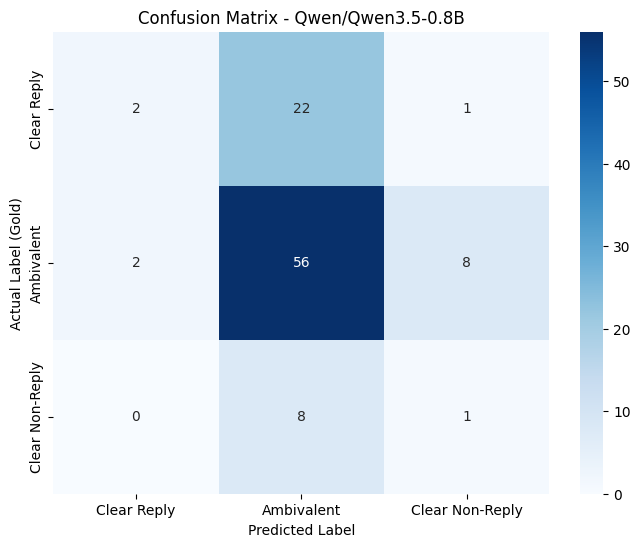

,Accuracy,Precision,Recall,F1-Score,Macro F1-Score,Confusion_Matrix,Labels,Inference_Time_Sec,Sec_per_Sample
Qwen/Qwen3.5-0.8B,0.59,0.563767,0.59,0.530272,0.326679,"[[2, 22, 1], [2, 56, 8], [0, 8, 1]]","[Clear Reply, Ambivalent, Clear Non-Reply]",96.56,0.9656


Loading model and tokenizer for: Qwen/Qwen3.5-2B


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Preparing prompts for 100 examples...
--------full_text:--------
<|im_start|>system
You are an expert political speech classifier. Classify the answer into EXACTLY ONE label:
- Clear Reply
- Ambivalent
- Clear Non-Reply

CRITICAL RULES TO AVOID MISTAKES:
1. "Clear Reply": The politician directly answers the EXACT question asked. They must provide a specific fact, a concrete commitment, or a clear yes/no. Do NOT choose this just because they use words from the question; the core request must be explicitly satisfied.
2. "Ambivalent": The politician discusses the general topic but remains vague, partial, or non-committal. They might give related background information without answering the specific question. Look for hedging words like "I think", "we are looking at", "we will see", "it depends", or "we're working on it". This is a very common response.
3. "Clear Non-Reply": The politician completely dodges the question. They change the subject entirely, pivot to their own unrelated talkin

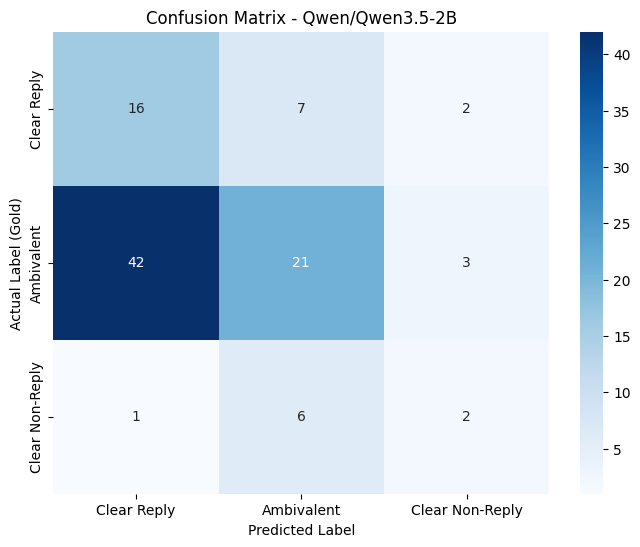

,Accuracy,Precision,Recall,F1-Score,Macro F1-Score,Confusion_Matrix,Labels,Inference_Time_Sec,Sec_per_Sample
Qwen/Qwen3.5-0.8B,0.59,0.563767,0.59,0.530272,0.326679,"[[2, 22, 1], [2, 56, 8], [0, 8, 1]]","[Clear Reply, Ambivalent, Clear Non-Reply]",96.56,0.9656
Qwen/Qwen3.5-2B,0.39,0.501158,0.39,0.394938,0.350317,"[[16, 7, 2], [42, 21, 3], [1, 6, 2]]","[Clear Reply, Ambivalent, Clear Non-Reply]",225.21,2.2521


Loading model and tokenizer for: Qwen/Qwen3.5-4B


Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/426 [00:00<?, ?it/s]

Preparing prompts for 100 examples...
--------full_text:--------
<|im_start|>system
You are an expert political discourse analyst. Classify a politician's answer into EXACTLY ONE of: Clear Reply, Ambivalent, or Clear Non-Reply.

REAL DISTRIBUTION (Keep this in mind):
- Ambivalent:       66%  <- Default when unsure.
- Clear Reply:      25%  <- Common, do not suppress if the specific fact is present.
- Clear Non-Reply:   9%  <- Very rare, use conservatively.

STEP 1 — Check for Clear Non-Reply:
Does the answer fail to mention the topic of the question at all? Does the politician redirect entirely?
HARD RULE: If the politician mentions the topic even once -> NOT Clear Non-Reply.

STEP 2 — Distinguish Clear Reply from Ambivalent:
Identify the exact specific request of the question. Is it answered?
- Clear Reply signals: Direct yes/no, specific number/date, or a concrete commitment ("I will"). 
  *FAIRNESS RULE*: A Clear Reply CAN be long. Length alone or added "spin" does NOT make it Ambiv

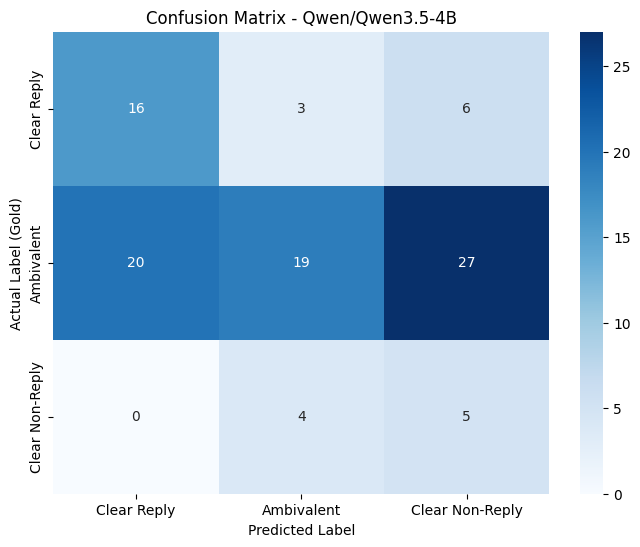

,Accuracy,Precision,Recall,F1-Score,Macro F1-Score,Confusion_Matrix,Labels,Inference_Time_Sec,Sec_per_Sample
Qwen/Qwen3.5-0.8B,0.59,0.563767,0.59,0.530272,0.326679,"[[2, 22, 1], [2, 56, 8], [0, 8, 1]]","[Clear Reply, Ambivalent, Clear Non-Reply]",96.56,0.9656
Qwen/Qwen3.5-2B,0.39,0.501158,0.39,0.394938,0.350317,"[[16, 7, 2], [42, 21, 3], [1, 6, 2]]","[Clear Reply, Ambivalent, Clear Non-Reply]",225.21,2.2521
Qwen/Qwen3.5-4B,0.4,0.605261,0.4,0.422905,0.383467,"[[16, 3, 6], [20, 19, 27], [0, 4, 5]]","[Clear Reply, Ambivalent, Clear Non-Reply]",613.98,6.1398


In [35]:
# model_names = ["Qwen/Qwen3.5-0.8B", "Qwen/Qwen3.5-2B", "Qwen/Qwen3.5-4B"] 
# all_metrics = {}

# for name in model_names:
#     gc.collect()
#     torch.cuda.empty_cache()
#     bnb_config = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.bfloat16, bnb_4bit_use_double_quant=True,)
#     print(f"Loading model and tokenizer for: {name}")

#     tokenizer = AutoTokenizer.from_pretrained(name)
#     tokenizer.padding_side = "left"
#     if tokenizer.pad_token is None:
#         tokenizer.pad_token = tokenizer.eos_token
#     model = AutoModelForCausalLM.from_pretrained(name, quantization_config=bnb_config, device_map="auto", trust_remote_code=True)

#     if torch.cuda.is_available():
#         torch.cuda.synchronize()
#     start_time = time.time()

#     if name == "Qwen/Qwen3.5-0.8B":
#         p_type = "few-shot"
#         max_t = 10
#     elif name == "Qwen/Qwen3.5-2B":
#         p_type = "few-shot-2b"
#         max_t = 10
#     elif name == "Qwen/Qwen3.5-4B":
#         p_type = "few-shot-4b"
#         max_t = 10

#     results = run_exp1_few(model, tokenizer, stratified_subset, prompt_type=p_type, max_tokens=max_t, sample=False, batch_size=8)

#     if torch.cuda.is_available():
#         torch.cuda.synchronize()
#     end_time = time.time()
#     elapsed_time = end_time - start_time

#     metrics = calculate_metrics(results)
#     metrics['Inference_Time_Sec'] = round(elapsed_time, 2)
#     metrics['Sec_per_Sample'] = round(elapsed_time / num_samples, 4)
#     all_metrics[name] = metrics

#     print(f"Model {name} finished in {elapsed_time:.2f}s")
#     plot_confusion_matrix(results, model_name=name)

#     del model
#     del tokenizer
#     gc.collect()
#     torch.cuda.empty_cache()
#     time.sleep(2)

#     # submission_df = create_submission_csv(results, stratified_subset, name, p_type)

#     df_comparison = pd.DataFrame(all_metrics).T
#     display(df_comparison)

### Experiment 2 in models qwen3.5-0.8B, qwen3.5-2B and qwen3.5-4B

In [36]:
# def define_system_promt_exp2_few(prompt_type="few-shot"): 
#     if prompt_type == "few-shot":
#         system_prompt = """You are an expert political speech classifier. Classify the answer into EXACTLY ONE label:
# - Clear Reply
# - Ambivalent
# - Clear Non-Reply

# CRITICAL RULES TO AVOID MISTAKES:
# 1. DO NOT choose "Clear Reply" just because the politician is talking about the topic. A "Clear Reply" MUST give the specific fact, commitment, or yes/no requested.
# 2. If the answer is vague, non-committal, or incomplete, you MUST choose "Ambivalent".
# 3. If the politician changes the subject, attacks someone else, or says "I can't answer that", you MUST choose "Clear Non-Reply".

# Study the following examples carefully to learn the pattern. Output ONLY the exact label name.""" # 3 

#         return system_prompt

#     elif prompt_type == "few-shot-2b": 
#         system_prompt = """You are a classification algorithm analyzing political text. Classify the input into EXACTLY ONE label: Clear Reply, Ambivalent, or Clear Non-Reply.

# ### EXECUTE THIS LOGIC ON EVERY INPUT:

# DEFINE core_request = The exact specific information the Question asks for.

# IF Answer completely ignores core_request AND (redirects to new topic OR attacks opponent OR refuses to answer):
#     RETURN "Clear Non-Reply"

# ELSE IF Answer explicitly provides the exact core_request (gives a specific fact, definitive yes/no, or concrete commitment):
#     RETURN "Clear Reply"

# ELSE IF Answer engages with the topic BUT is vague, partial, non-committal, OR uses hedging words ("I think", "we will see", "it depends"):
#     RETURN "Ambivalent"

# ELSE:
#     RETURN "Ambivalent"

# ### INSTRUCTIONS:
# Study the examples below to calibrate your logic.
# You MUST output ONLY the exact return value (the label). Do not add punctuation. Do not explain. Do not output <think> tags.""" # algorithm form v1
        
#         return system_prompt

#     elif prompt_type == "few-shot-4b": 
#         system_prompt = """You are a strict political discourse auditor. Classify the politician's answer into EXACTLY ONE label:
# - Clear Reply
# - Ambivalent
# - Clear Non-Reply

# YOUR GOAL: First, mentally identify the specific constraint in the Question (e.g., 'When?', 'Will you?', 'How much?', 'Yes or No?'). Then, check the Answer against these rules:

# CLASSIFICATION RULES:

# 1. Clear Non-Reply: Completely off-topic, explicit refusal ("I can't answer"), or total pivot to attack an opponent. 
#    - CRITICAL: If they mention the topic of the question even slightly, do NOT use this label.

# 2. Clear Reply: The specific constraint of the question is explicitly answered.
#    - Triggers: A direct "Yes" or "No", a concrete date, an exact number, or a firm commitment ("I will", "We are going to").
#    - FAIRNESS RULE: Politicians use heavy "spin" and long introductions. Extra padding does NOT cancel out a valid answer. If the requested fact is buried ANYWHERE in the text, it is a Clear Reply.

# 3. Ambivalent: The politician discusses the correct topic but AVOIDS or misses the specific constraint.
#    - Triggers: Hedging language ("I think", "we'll see", "working on it"), vague generalities, partial answers, or addressing the background history instead of the exact question asked.

# Study the following examples carefully to learn these exact boundaries.
# Respond ONLY with the exact label name. Do not output anything else."""  # 3 

#         return system_prompt

# def build_prompt_exp2_few(example, prompt_type="zero-shot"):
#     if prompt_type in ["zero-shot", "zero-shot-2b", "zero-shot-4b"]:
#         return f"""Question: {example["question"]}\nAnswer: {example["interview_answer"]}\nLabel:"""
#     elif prompt_type in ["few-shot", "few-shot-2b", "few-shot-4b"]:
#         return f"Question: {example['question']}\nAnswer: {example['interview_answer']}\nLabel:" 
#     else: # GoT
#         return f"Question: {example['question']}\nAnswer: {example['interview_answer']}" 

# def run_exp2_few(model, tokenizer, data_split, prompt_type="zero-shot", max_tokens=10, sample=False, batch_size=8):
#     tokenizer.padding_side = "left"
#     if tokenizer.pad_token is None:
#         tokenizer.pad_token = tokenizer.eos_token

#     print(f"Preparing prompts for {len(data_split)} examples...")
#     prompts = []
#     system_prompt = define_system_promt_exp2_few(prompt_type)

#     for example in data_split:
#         if prompt_type in ["few-shot", "few-shot-2b", "few-shot-4b"]:
#             messages = [{"role": "system", "content": system_prompt}]

#             if few_shot_examples:
#                 for demo in few_shot_examples:
#                     messages.append({
#                         "role": "user",
#                         "content": f"Question: {demo['question']}\nAnswer: {demo['answer']}"
#                     })
#                     messages.append({
#                         "role": "assistant",
#                         "content": f"Label: {demo['label']}"
#                         # "content": demo['label']
#                     })

#             messages.append({
#                 "role": "user",
#                 "content": build_prompt_exp2_few(example, prompt_type)
#             })
#         elif prompt_type in ["zero-shot-COT-0.8b"]:
#             messages = [
#                 {"role": "system", "content": system_prompt},
#                 {"role": "user", "content": f"{build_prompt_exp2_few(example, prompt_type)}"}
#             ]
#         elif prompt_type in ["few-shot-COT-0.8b", "COT-2b", "COT-4b"]:
#             messages = [{"role": "system", "content": system_prompt}]

#             if few_shot_cot_examples:
#                 for demo in few_shot_cot_examples:
#                     messages.append({
#                         "role": "user",
#                         "content": f"Question: {demo['question']}\nAnswer: {demo['answer']}" # \nLet's think step by step.
#                     })
#                     messages.append({
#                         "role": "assistant",
#                         "content": f"Reasoning: {demo['reasoning']}\nLabel: {demo['label']}"
#                     })

#             messages.append({
#                 "role": "user",
#                 "content": build_prompt_exp2_few(example, prompt_type)
#             })
#         else: # zero-shot
#             messages = [
#                 {"role": "system", "content": system_prompt},
#                 {"role": "user", "content": f"{build_prompt_exp2_few(example, prompt_type)}"}
#             ]
#         full_text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True, enable_thinking=False)
#         prompts.append(full_text)
#     print("--------full_text:--------")
#     print(full_text)
#     print("---------------------")

#     results = []
#     model.eval()
#     total_batches = (len(prompts) + batch_size - 1) // batch_size

#     print(f"Starting inference (Total batches: {total_batches}, Batch size: {batch_size})...")

#     for i in range(0, len(prompts), batch_size):
#         current_batch_idx = (i // batch_size) + 1
#         batch_prompts = prompts[i : i + batch_size]
#         batch_data = data_split.select(range(i, min(i + batch_size, len(data_split))))

#         inputs = tokenizer(batch_prompts, return_tensors="pt", padding=True).to(model.device)


#         stop_token_id = tokenizer.convert_tokens_to_ids('\n')
#         eos_ids = []
#         if tokenizer.eos_token_id is not None:
#             eos_ids.append(tokenizer.eos_token_id)
#         if stop_token_id is not None:
#             eos_ids.append(stop_token_id)

#         with torch.no_grad():
#             outputs = model.generate(
#                 **inputs,
#                 max_new_tokens=max_tokens,
#                 do_sample=sample,   
#                 # temperature=0.3, 
#                 pad_token_id=tokenizer.pad_token_id or tokenizer.eos_token_id,
#                 eos_token_id=eos_ids, 
#             )


#         for j, output in enumerate(outputs):
#             raw_text = tokenizer.decode(output[inputs["input_ids"].shape[1]:], skip_special_tokens=True)
#             gold_label_int = batch_data[j]["clarity_label"]
#             gold_label_str = data_split.features["clarity_label"].int2str(gold_label_int)

#             if prompt_type in ["few-shot-COT-0.8b", "zero-shot-COT-0.8b", "COT-2b", "COT-4b"]:
#                 match = re.search(r'Label:\s*(.*)', raw_text, re.IGNORECASE)
#                 if match:
#                     extracted = match.group(1).strip()
#                     if "Clear Non-Reply" in extracted:
#                         generated_text = "Clear Non-Reply"
#                     elif "Clear Reply" in extracted:
#                         generated_text = "Clear Reply"
#                     elif "Ambivalent" in extracted:
#                         generated_text = "Ambivalent"
#                     else:
#                         print("Parsing Error")
#                         generated_text = "Parsing Error"
#                 else:
#                     print("Parsing Error")
#                     generated_text = "Parsing Error"
#             elif prompt_type in ["zero-shot", "zero-shot-2b", "few-shot-4b", "few-shot", "few-shot-2b", "zero-shot-4b"]:
#                 if "Clear Non-Reply" in raw_text:
#                     generated_text = "Clear Non-Reply"
#                 elif "Clear Reply" in raw_text:
#                     generated_text = "Clear Reply"
#                 elif "Ambivalent" in raw_text:
#                     generated_text = "Ambivalent"
#                 else:
#                     generated_text = normalize_prediction(raw_text).strip()

#             # print("Predicted: ", generated_text.strip())
#             # print("True Label: ", gold_label_str)
#             # print("---\n")

#             # print(f"Question: {batch_data[j]['question']}")
#             # print(f"Answer: {batch_data[j]['interview_answer']}")
#             # print(f"Qwen Raw Output: {raw_text.strip()}")
#             # print(f"Parsed Prediction: {generated_text.strip()}")
#             # print(f"True Label: {gold_label_str}")
#             # print("-" * 50 + "\n")

#             results.append({
#                 "question": batch_data[j]["question"],
#                 "interview_answer": batch_data[j]["interview_answer"],
#                 "prediction": generated_text.strip(),
#                 "gold_label": batch_data[j]["clarity_label"]
#             })

#         if current_batch_idx % 1 == 0 or current_batch_idx == total_batches:
#             processed_examples = min(i + batch_size, len(prompts))
#             print(f"Batch {current_batch_idx}/{total_batches} completed. Processed {processed_examples}/{len(prompts)} examples.")

#     print("Inference finished successfully.")
#     return results

Loading model and tokenizer for: Qwen/Qwen3.5-0.8B


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Preparing prompts for 100 examples...
--------full_text:--------
<|im_start|>system
You are an expert political speech classifier. Classify the answer into EXACTLY ONE label:
- Clear Reply
- Ambivalent
- Clear Non-Reply

CRITICAL RULES TO AVOID MISTAKES:
1. DO NOT choose "Clear Reply" just because the politician is talking about the topic. A "Clear Reply" MUST give the specific fact, commitment, or yes/no requested.
2. If the answer is vague, non-committal, or incomplete, you MUST choose "Ambivalent".
3. If the politician changes the subject, attacks someone else, or says "I can't answer that", you MUST choose "Clear Non-Reply".

Study the following examples carefully to learn the pattern. Output ONLY the exact label name.<|im_end|>
<|im_start|>user
Question: Confirming if both topics will be discussed.
Answer: Talk about both.Vice President Michael R. Pence's Record as Governor of Indiana/<|im_end|>
<|im_start|>assistant
Label: Clear Reply<|im_end|>
<|im_start|>user
Question: Argument

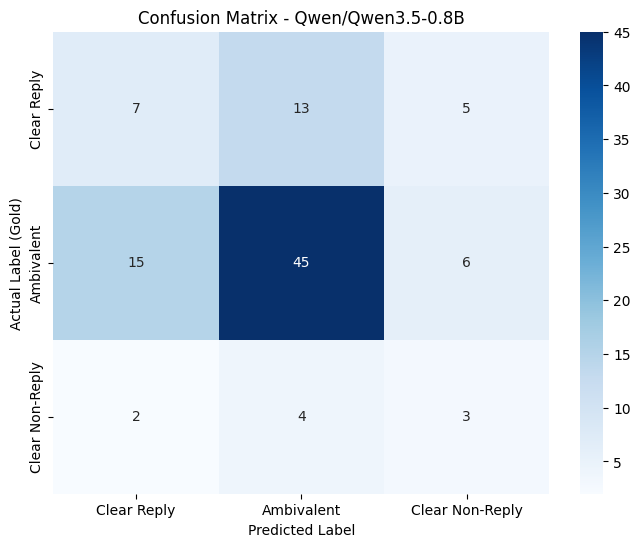

,Accuracy,Precision,Recall,F1-Score,Macro F1-Score,Confusion_Matrix,Labels,Inference_Time_Sec,Sec_per_Sample
Qwen/Qwen3.5-0.8B,0.55,0.571235,0.55,0.558969,0.41657,"[[7, 13, 5], [15, 45, 6], [2, 4, 3]]","[Clear Reply, Ambivalent, Clear Non-Reply]",88.84,0.8884


Loading model and tokenizer for: Qwen/Qwen3.5-2B


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Preparing prompts for 100 examples...
--------full_text:--------
<|im_start|>system
You are a classification algorithm analyzing political text. Classify the input into EXACTLY ONE label: Clear Reply, Ambivalent, or Clear Non-Reply.

### EXECUTE THIS LOGIC ON EVERY INPUT:

DEFINE core_request = The exact specific information the Question asks for.

IF Answer completely ignores core_request AND (redirects to new topic OR attacks opponent OR refuses to answer):
    RETURN "Clear Non-Reply"

ELSE IF Answer explicitly provides the exact core_request (gives a specific fact, definitive yes/no, or concrete commitment):
    RETURN "Clear Reply"

ELSE IF Answer engages with the topic BUT is vague, partial, non-committal, OR uses hedging words ("I think", "we will see", "it depends"):
    RETURN "Ambivalent"

ELSE:
    RETURN "Ambivalent"

### INSTRUCTIONS:
Study the examples below to calibrate your logic.
You MUST output ONLY the exact return value (the label). Do not add punctuation. Do not ex

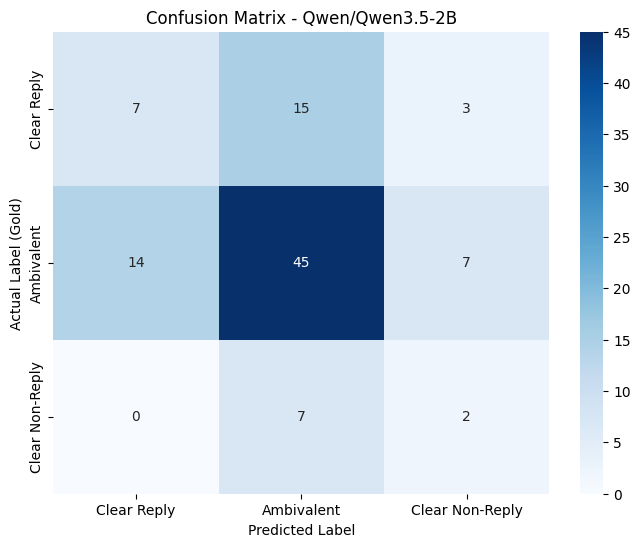

,Accuracy,Precision,Recall,F1-Score,Macro F1-Score,Confusion_Matrix,Labels,Inference_Time_Sec,Sec_per_Sample
Qwen/Qwen3.5-0.8B,0.55,0.571235,0.55,0.558969,0.41657,"[[7, 13, 5], [15, 45, 6], [2, 4, 3]]","[Clear Reply, Ambivalent, Clear Non-Reply]",88.84,0.8884
Qwen/Qwen3.5-2B,0.54,0.541617,0.54,0.539846,0.390505,"[[7, 15, 3], [14, 45, 7], [0, 7, 2]]","[Clear Reply, Ambivalent, Clear Non-Reply]",201.18,2.0118


Loading model and tokenizer for: Qwen/Qwen3.5-4B


Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/426 [00:00<?, ?it/s]

Preparing prompts for 100 examples...
--------full_text:--------
<|im_start|>system
You are a strict political discourse auditor. Classify the politician's answer into EXACTLY ONE label:
- Clear Reply
- Ambivalent
- Clear Non-Reply

YOUR GOAL: First, mentally identify the specific constraint in the Question (e.g., 'When?', 'Will you?', 'How much?', 'Yes or No?'). Then, check the Answer against these rules:

CLASSIFICATION RULES:

1. Clear Non-Reply: Completely off-topic, explicit refusal ("I can't answer"), or total pivot to attack an opponent. 
   - CRITICAL: If they mention the topic of the question even slightly, do NOT use this label.

2. Clear Reply: The specific constraint of the question is explicitly answered.
   - Triggers: A direct "Yes" or "No", a concrete date, an exact number, or a firm commitment ("I will", "We are going to").
   - FAIRNESS RULE: Politicians use heavy "spin" and long introductions. Extra padding does NOT cancel out a valid answer. If the requested fact is

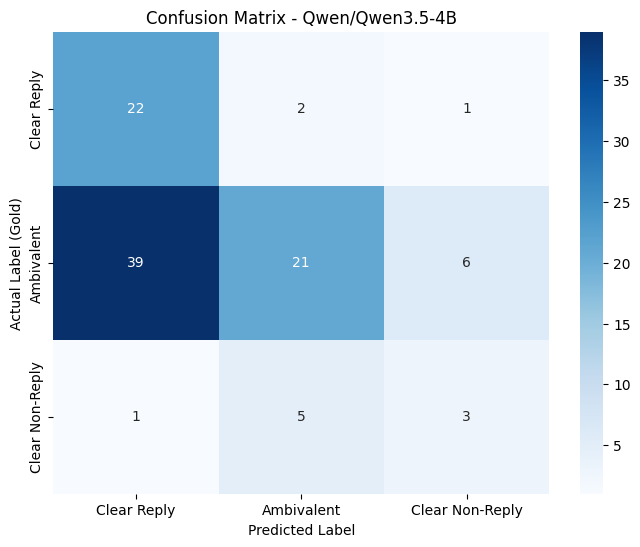

,Accuracy,Precision,Recall,F1-Score,Macro F1-Score,Confusion_Matrix,Labels,Inference_Time_Sec,Sec_per_Sample
Qwen/Qwen3.5-0.8B,0.55,0.571235,0.55,0.558969,0.41657,"[[7, 13, 5], [15, 45, 6], [2, 4, 3]]","[Clear Reply, Ambivalent, Clear Non-Reply]",88.84,0.8884
Qwen/Qwen3.5-2B,0.54,0.541617,0.54,0.539846,0.390505,"[[7, 15, 3], [14, 45, 7], [0, 7, 2]]","[Clear Reply, Ambivalent, Clear Non-Reply]",201.18,2.0118
Qwen/Qwen3.5-4B,0.46,0.61071,0.46,0.449751,0.422782,"[[22, 2, 1], [39, 21, 6], [1, 5, 3]]","[Clear Reply, Ambivalent, Clear Non-Reply]",561.0,5.61


In [37]:
# model_names = ["Qwen/Qwen3.5-0.8B", "Qwen/Qwen3.5-2B", "Qwen/Qwen3.5-4B"] 
# all_metrics = {}

# for name in model_names:
#     gc.collect()
#     torch.cuda.empty_cache()
#     bnb_config = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.bfloat16, bnb_4bit_use_double_quant=True,)
#     print(f"Loading model and tokenizer for: {name}")

#     tokenizer = AutoTokenizer.from_pretrained(name)
#     tokenizer.padding_side = "left"
#     if tokenizer.pad_token is None:
#         tokenizer.pad_token = tokenizer.eos_token
#     model = AutoModelForCausalLM.from_pretrained(name, quantization_config=bnb_config, device_map="auto", trust_remote_code=True)

#     if torch.cuda.is_available():
#         torch.cuda.synchronize()
#     start_time = time.time()

#     if name == "Qwen/Qwen3.5-0.8B":
#         p_type = "few-shot"
#         max_t = 10
#     elif name == "Qwen/Qwen3.5-2B":
#         p_type = "few-shot-2b"
#         max_t = 10
#     elif name == "Qwen/Qwen3.5-4B":
#         p_type = "few-shot-4b"
#         max_t = 10

#     results = run_exp2_few(model, tokenizer, stratified_subset, prompt_type=p_type, max_tokens=max_t, sample=False, batch_size=8)

#     if torch.cuda.is_available():
#         torch.cuda.synchronize()
#     end_time = time.time()
#     elapsed_time = end_time - start_time

#     metrics = calculate_metrics(results)
#     metrics['Inference_Time_Sec'] = round(elapsed_time, 2)
#     metrics['Sec_per_Sample'] = round(elapsed_time / num_samples, 4)
#     all_metrics[name] = metrics

#     print(f"Model {name} finished in {elapsed_time:.2f}s")
#     plot_confusion_matrix(results, model_name=name)

#     del model
#     del tokenizer
#     gc.collect()
#     torch.cuda.empty_cache()
#     time.sleep(2)

#     # submission_df = create_submission_csv(results, stratified_subset, name, p_type)

#     df_comparison = pd.DataFrame(all_metrics).T
#     display(df_comparison)

## Using few-shot-CoT prompting method 

### Experiment 1 in models qwen3.5-0.8B, qwen3.5-2B and qwen3.5-4B

In [27]:
# few_shot_cot_examples_exp1 = [
#     {
#         "question": "Confirming if both topics will be discussed.",
#         "answer": "Talk about both.Vice President Michael R. Pence's Record as Governor of Indiana/",
#         "reasoning": "The question asks for a confirmation on whether both topics will be discussed. The politician explicitly says 'Talk about both', which is a direct and specific answer to the core request.",
#         "label": "Clear Reply"
#     },
#     {
#         "question": "Arguments made specifically by the questioner to President Trump.",
#         "answer": "I can't understand what you mean by United States presence in my country. They sent a training team, based on their experiences, to train our officers at some of our training institutions and move to the crisis area to see how well the trainers are performing. I think this is one of the best things the United States could do for us to stabilize the country.",
#         "reasoning": "The question asks for specific arguments made by the questioner. The politician pivots to discuss the general topic of U.S. presence and stability, using hedging phrases like 'I think'. They do not address the specific arguments requested, remaining vague.",
#         "label": "Ambivalent"
#     },
#     {
#         "question": "Request for clarity on the thinking about the Deputy Attorney General after the midterms.",
#         "answer": "I'd rather answer that at a little bit different time. We're looking at a lot of different things, including Cabinet. I'm very happy with most of my Cabinet. We're looking at different people for different positions. You know, it's very common after the midterms. I didn't want to do anything before the midterms.But I will tell you that, for the most part, I'm extremely happy with my Cabinet. I think Mike Pompeo has fit in so beautifully. He's done an incredible job as——",
#         "reasoning": "The question asks for specific clarity regarding the Deputy Attorney General. The politician explicitly refuses to answer ('I'd rather answer that at a little bit different time') and immediately changes the subject to talk about the Cabinet in general and Mike Pompeo, completely dodging the core request.",
#         "label": "Clear Non-Reply"
#     }
# ] # 1

In [28]:
# def define_system_promt_exp1_COT(prompt_type="few-shot"): 
#     if prompt_type == "few-shot-COT-0.8b":
#         system_prompt = """You are an expert political speech classifier. Classify the answer into EXACTLY ONE label:
# - Clear Reply
# - Ambivalent
# - Clear Non-Reply

# CRITICAL RULES TO AVOID MISTAKES:
# 1. "Clear Reply": The politician directly answers the exact question with a specific fact, a concrete commitment, or a clear yes/no.
# 2. "Ambivalent": The politician discusses the general topic but is vague, partial, or non-committal. Look for hedging words like "I think", "we are looking at", or "we will see". This is a very common response.
# 3. "Clear Non-Reply": The politician completely dodges the question, changes the subject entirely, attacks someone else, or says "I can't answer".

# Study the following examples carefully to learn the pattern. Output ONLY the exact label name.

# Do NOT use <think> tags. Keep Reasoning under 2 sentences.

# Format:
# Reasoning: [Analysis]
# Label: [Category]""" # 1 same as few-shot

#         return system_prompt

#     elif prompt_type == "COT-2b": 
#         system_prompt = """You are an expert political discourse analyst. Your task is to perform a strict but fair classification of political answers.

# CLASSIFICATION RULES:
# 1. Clear Reply (Direct & Specific): The politician provides the exact factual information, concrete plan, or yes/no commitment requested.
#    - CRITICAL RULE: Politicians talk a lot. If the specific requested information is present ANYWHERE in the response, it is a Clear Reply. Extra context, background, or "spin" does NOT cancel out a valid answer. Do not penalize for length.

# 2. Ambivalent (Vague & Hedging): The politician talks about the correct topic but FAILS to provide the specific requested information.
#    - Indicators: They use hedging ("I think", "we'll see", "working on it"), give partial info, or discuss the general issue without committing. Topic matching without providing the specific fact is Ambivalent.

# 3. Clear Non-Reply (Complete Dodge): The politician completely ignores the question.
#    - Indicators: Changing the subject entirely, pivoting to unrelated talking points, attacking someone, or explicitly refusing to answer.

# CHAIN OF THOUGHT PROTOCOL:
# You MUST format your output exactly as follows:
# Reasoning: [Step 1: Identify the core request. Step 2: Search the answer for this exact info. Step 3: Conclude based on whether the specific info is present or missing.]
# Label: [Clear Reply/Ambivalent/Clear Non-Reply]""" # 2
        
#         return system_prompt

#     elif prompt_type == "COT-4b": 
#         system_prompt = """You are an expert political discourse analyst. Your task is to fairly classify political Q&A.

# CLASSIFICATION RULES:
# 1. Clear Reply: The specific requested info (fact, yes/no, commitment) is explicitly present.
#    *FAIRNESS RULE*: Do not penalize long answers! If the requested fact is buried inside a long, polite, or spinning response, it is STILL a Clear Reply.
# 2. Ambivalent: The politician discusses the topic, but the specific requested info is MISSING.
#    *INDICATORS*: Uses hedging ("I think", "we hope", "working on it"), provides general background instead of the specific fact, or answers a slightly different question.
# 3. Clear Non-Reply: Completely dodges the question, pivots to an unrelated topic, attacks, or explicitly refuses ("I can't answer that").

# CHAIN OF THOUGHT PROTOCOL:
# You MUST format your output exactly as follows:
# Reasoning: [1. What is the exact info requested? 2. Is that exact info present ANYWHERE in the text? 3. Conclusion.]
# Label: [Clear Reply/Ambivalent/Clear Non-Reply]""" # 1 same as CoT-2B

#         return system_prompt

# def build_prompt_exp1_COT(example, prompt_type="zero-shot"):
#     if prompt_type in ["zero-shot", "zero-shot-2b", "zero-shot-4b"]:
#         return f"""Question: {example["question"]}\nAnswer: {example["interview_answer"]}\nLabel:"""
#     elif prompt_type in ["few-shot", "few-shot-2b", "few-shot-4b"]:
#         return f"Question: {example['question']}\nAnswer: {example['interview_answer']}\nLabel:" 
#     else: # GoT
#         return f"Question: {example['question']}\nAnswer: {example['interview_answer']}" 

# def run_exp1_COT(model, tokenizer, data_split, prompt_type="zero-shot", max_tokens=10, sample=False, batch_size=8):
#     tokenizer.padding_side = "left"
#     if tokenizer.pad_token is None:
#         tokenizer.pad_token = tokenizer.eos_token

#     print(f"Preparing prompts for {len(data_split)} examples...")
#     prompts = []
#     system_prompt = define_system_promt_exp1_COT(prompt_type)

#     for example in data_split:
#         if prompt_type in ["few-shot", "few-shot-2b", "few-shot-4b"]:
#             messages = [{"role": "system", "content": system_prompt}]

#             if few_shot_examples_exp1:
#                 for demo in few_shot_examples_exp1:
#                     messages.append({
#                         "role": "user",
#                         "content": f"Question: {demo['question']}\nAnswer: {demo['answer']}"
#                     })
#                     messages.append({
#                         "role": "assistant",
#                         "content": f"Label: {demo['label']}"
#                         # "content": demo['label']
#                     })

#             messages.append({
#                 "role": "user",
#                 "content": build_prompt_exp1_COT(example, prompt_type)
#             })
#         elif prompt_type in ["zero-shot-COT-0.8b"]:
#             messages = [
#                 {"role": "system", "content": system_prompt},
#                 {"role": "user", "content": f"{build_prompt_exp1_COT(example, prompt_type)}"}
#             ]
#         elif prompt_type in ["few-shot-COT-0.8b", "COT-2b", "COT-4b"]:
#             messages = [{"role": "system", "content": system_prompt}]

#             if few_shot_cot_examples_exp1:
#                 for demo in few_shot_cot_examples_exp1:
#                     messages.append({
#                         "role": "user",
#                         "content": f"Question: {demo['question']}\nAnswer: {demo['answer']}" # \nLet's think step by step.
#                     })
#                     messages.append({
#                         "role": "assistant",
#                         "content": f"Reasoning: {demo['reasoning']}\nLabel: {demo['label']}"
#                     })

#             messages.append({
#                 "role": "user",
#                 "content": build_prompt_exp1_COT(example, prompt_type)
#             })
#         else: # zero-shot
#             messages = [
#                 {"role": "system", "content": system_prompt},
#                 {"role": "user", "content": f"{build_prompt_exp1_COT(example, prompt_type)}"}
#             ]
#         full_text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True, enable_thinking=False)
#         prompts.append(full_text)
#     print("--------full_text:--------")
#     print(full_text)
#     print("---------------------")

#     results = []
#     model.eval()
#     total_batches = (len(prompts) + batch_size - 1) // batch_size

#     print(f"Starting inference (Total batches: {total_batches}, Batch size: {batch_size})...")

#     for i in range(0, len(prompts), batch_size):
#         current_batch_idx = (i // batch_size) + 1
#         batch_prompts = prompts[i : i + batch_size]
#         batch_data = data_split.select(range(i, min(i + batch_size, len(data_split))))

#         inputs = tokenizer(batch_prompts, return_tensors="pt", padding=True).to(model.device)

#         stop_token_id = tokenizer.convert_tokens_to_ids('\n')
#         eos_ids = []
#         if tokenizer.eos_token_id is not None:
#             eos_ids.append(tokenizer.eos_token_id)
#         if stop_token_id is not None:
#             eos_ids.append(stop_token_id)

#         with torch.no_grad():
#             outputs = model.generate(
#                 **inputs,
#                 max_new_tokens=max_tokens,
#                 do_sample=sample,   
#                 # temperature=0.3, 
#                 pad_token_id=tokenizer.pad_token_id or tokenizer.eos_token_id,
#                 eos_token_id=eos_ids,
#             )


#         for j, output in enumerate(outputs):
#             raw_text = tokenizer.decode(output[inputs["input_ids"].shape[1]:], skip_special_tokens=True)
#             gold_label_int = batch_data[j]["clarity_label"]
#             gold_label_str = data_split.features["clarity_label"].int2str(gold_label_int)

#             if prompt_type in ["few-shot-COT-0.8b", "zero-shot-COT-0.8b", "COT-2b", "COT-4b"]:
#                 match = re.search(r'Label:\s*(.*)', raw_text, re.IGNORECASE)
#                 if match:
#                     extracted = match.group(1).strip()
#                     if "Clear Non-Reply" in extracted:
#                         generated_text = "Clear Non-Reply"
#                     elif "Clear Reply" in extracted:
#                         generated_text = "Clear Reply"
#                     elif "Ambivalent" in extracted:
#                         generated_text = "Ambivalent"
#                     else:
#                         print("Parsing Error")
#                         generated_text = "Parsing Error"
#                 else:
#                     print("Parsing Error")
#                     generated_text = "Parsing Error"
#             elif prompt_type in ["zero-shot", "zero-shot-2b", "few-shot-4b", "few-shot", "few-shot-2b", "zero-shot-4b"]:
#                 if "Clear Non-Reply" in raw_text:
#                     generated_text = "Clear Non-Reply"
#                 elif "Clear Reply" in raw_text:
#                     generated_text = "Clear Reply"
#                 elif "Ambivalent" in raw_text:
#                     generated_text = "Ambivalent"
#                 else:
#                     generated_text = normalize_prediction(raw_text).strip()

#             # print("Predicted: ", generated_text.strip())
#             # print("True Label: ", gold_label_str)
#             # print("---\n")

#             # print(f"Question: {batch_data[j]['question']}")
#             # print(f"Answer: {batch_data[j]['interview_answer']}")
#             # print(f"Qwen Raw Output: {raw_text.strip()}")
#             # print(f"Parsed Prediction: {generated_text.strip()}")
#             # print(f"True Label: {gold_label_str}")
#             # print("-" * 50 + "\n")

#             results.append({
#                 "question": batch_data[j]["question"],
#                 "interview_answer": batch_data[j]["interview_answer"],
#                 "prediction": generated_text.strip(),
#                 "gold_label": batch_data[j]["clarity_label"]
#             })

#         if current_batch_idx % 1 == 0 or current_batch_idx == total_batches:
#             processed_examples = min(i + batch_size, len(prompts))
#             print(f"Batch {current_batch_idx}/{total_batches} completed. Processed {processed_examples}/{len(prompts)} examples.")

#     print("Inference finished successfully.")
#     return results


Loading model and tokenizer for: Qwen/Qwen3.5-0.8B


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Preparing prompts for 100 examples...
--------full_text:--------
<|im_start|>system
You are an expert political speech classifier. Classify the answer into EXACTLY ONE label:
- Clear Reply
- Ambivalent
- Clear Non-Reply

CRITICAL RULES TO AVOID MISTAKES:
1. "Clear Reply": The politician directly answers the exact question with a specific fact, a concrete commitment, or a clear yes/no.
2. "Ambivalent": The politician discusses the general topic but is vague, partial, or non-committal. Look for hedging words like "I think", "we are looking at", or "we will see". This is a very common response.
3. "Clear Non-Reply": The politician completely dodges the question, changes the subject entirely, attacks someone else, or says "I can't answer".

Study the following examples carefully to learn the pattern. Output ONLY the exact label name.

Do NOT use <think> tags. Keep Reasoning under 2 sentences.

Format:
Reasoning: [Analysis]
Label: [Category]<|im_end|>
<|im_start|>user
Question: Confirming i

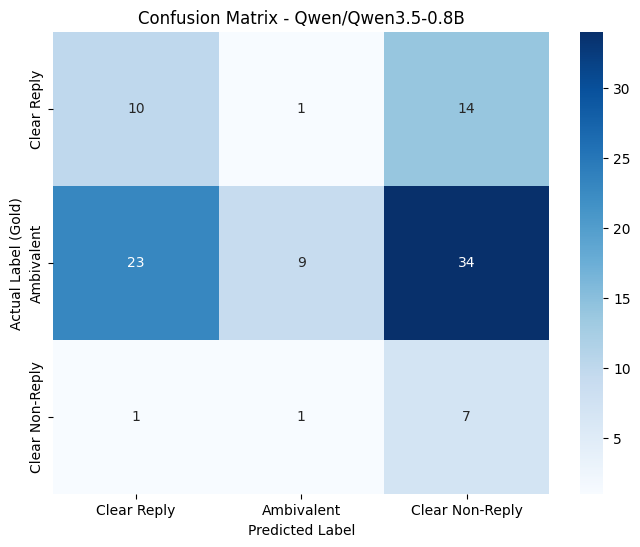

,Accuracy,Precision,Recall,F1-Score,Macro F1-Score,Confusion_Matrix,Labels,Inference_Time_Sec,Sec_per_Sample
Qwen/Qwen3.5-0.8B,0.26,0.624984,0.26,0.258719,0.263833,"[[10, 1, 14], [23, 9, 34], [1, 1, 7]]","[Clear Reply, Ambivalent, Clear Non-Reply]",214.96,2.1496


Loading model and tokenizer for: Qwen/Qwen3.5-2B


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Preparing prompts for 100 examples...
--------full_text:--------
<|im_start|>system
You are an expert political discourse analyst. Your task is to perform a strict but fair classification of political answers.

CLASSIFICATION RULES:
1. Clear Reply (Direct & Specific): The politician provides the exact factual information, concrete plan, or yes/no commitment requested.
   - CRITICAL RULE: Politicians talk a lot. If the specific requested information is present ANYWHERE in the response, it is a Clear Reply. Extra context, background, or "spin" does NOT cancel out a valid answer. Do not penalize for length.

2. Ambivalent (Vague & Hedging): The politician talks about the correct topic but FAILS to provide the specific requested information.
   - Indicators: They use hedging ("I think", "we'll see", "working on it"), give partial info, or discuss the general issue without committing. Topic matching without providing the specific fact is Ambivalent.

3. Clear Non-Reply (Complete Dodge): The

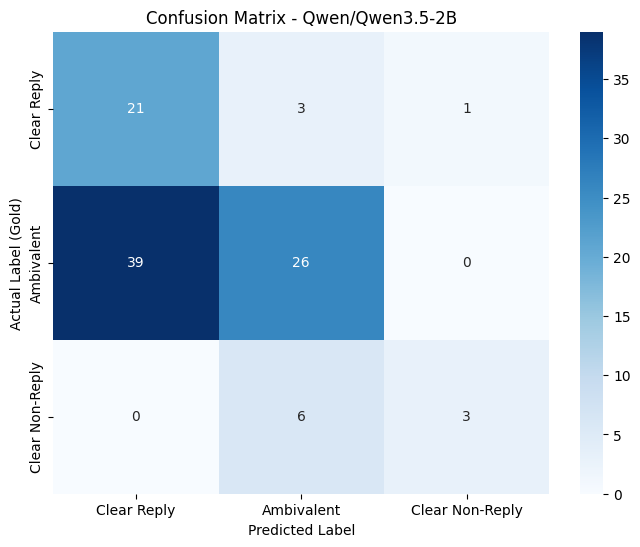

,Accuracy,Precision,Recall,F1-Score,Macro F1-Score,Confusion_Matrix,Labels,Inference_Time_Sec,Sec_per_Sample
Qwen/Qwen3.5-0.8B,0.26,0.624984,0.26,0.258719,0.263833,"[[10, 1, 14], [23, 9, 34], [1, 1, 7]]","[Clear Reply, Ambivalent, Clear Non-Reply]",214.96,2.1496
Qwen/Qwen3.5-2B,0.5,0.645286,0.5,0.50487,0.490169,"[[21, 3, 1], [39, 26, 0], [0, 6, 3]]","[Clear Reply, Ambivalent, Clear Non-Reply]",572.94,5.7294


Loading model and tokenizer for: Qwen/Qwen3.5-4B


Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/426 [00:00<?, ?it/s]

Preparing prompts for 100 examples...
--------full_text:--------
<|im_start|>system
You are an expert political discourse analyst. Your task is to fairly classify political Q&A.

CLASSIFICATION RULES:
1. Clear Reply: The specific requested info (fact, yes/no, commitment) is explicitly present.
   *FAIRNESS RULE*: Do not penalize long answers! If the requested fact is buried inside a long, polite, or spinning response, it is STILL a Clear Reply.
2. Ambivalent: The politician discusses the topic, but the specific requested info is MISSING.
   *INDICATORS*: Uses hedging ("I think", "we hope", "working on it"), provides general background instead of the specific fact, or answers a slightly different question.
3. Clear Non-Reply: Completely dodges the question, pivots to an unrelated topic, attacks, or explicitly refuses ("I can't answer that").

CHAIN OF THOUGHT PROTOCOL:
You MUST format your output exactly as follows:
Reasoning: [1. What is the exact info requested? 2. Is that exact info 

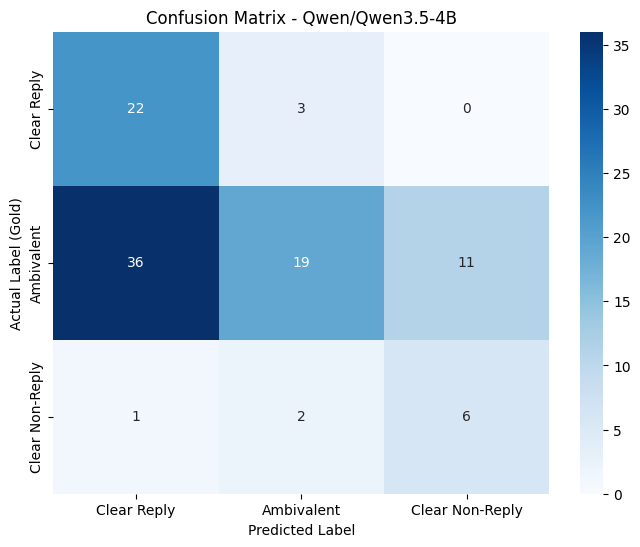

,Accuracy,Precision,Recall,F1-Score,Macro F1-Score,Confusion_Matrix,Labels,Inference_Time_Sec,Sec_per_Sample
Qwen/Qwen3.5-0.8B,0.26,0.624984,0.26,0.258719,0.263833,"[[10, 1, 14], [23, 9, 34], [1, 1, 7]]","[Clear Reply, Ambivalent, Clear Non-Reply]",214.96,2.1496
Qwen/Qwen3.5-2B,0.5,0.645286,0.5,0.50487,0.490169,"[[21, 3, 1], [39, 26, 0], [0, 6, 3]]","[Clear Reply, Ambivalent, Clear Non-Reply]",572.94,5.7294
Qwen/Qwen3.5-4B,0.47,0.647485,0.47,0.451158,0.46919,"[[22, 3, 0], [36, 19, 11], [1, 2, 6]]","[Clear Reply, Ambivalent, Clear Non-Reply]",1302.44,13.0244


In [29]:
# model_names = ["Qwen/Qwen3.5-0.8B", "Qwen/Qwen3.5-2B", "Qwen/Qwen3.5-4B"] 
# all_metrics = {}

# for name in model_names:
#     gc.collect()
#     torch.cuda.empty_cache()
#     bnb_config = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.bfloat16, bnb_4bit_use_double_quant=True,)
#     print(f"Loading model and tokenizer for: {name}")

#     tokenizer = AutoTokenizer.from_pretrained(name)
#     tokenizer.padding_side = "left"
#     if tokenizer.pad_token is None:
#         tokenizer.pad_token = tokenizer.eos_token
#     model = AutoModelForCausalLM.from_pretrained(name, quantization_config=bnb_config, device_map="auto", trust_remote_code=True)

#     if torch.cuda.is_available():
#         torch.cuda.synchronize()
#     start_time = time.time()

#     if name == "Qwen/Qwen3.5-0.8B":
#         p_type = "few-shot-COT-0.8b"
#         max_t = 200
#     elif name == "Qwen/Qwen3.5-2B":
#         p_type = "COT-2b"
#         max_t = 200
#     elif name == "Qwen/Qwen3.5-4B":
#         p_type = "COT-4b"
#         max_t = 200

#     results = run_exp1_COT(model, tokenizer, stratified_subset, prompt_type=p_type, max_tokens=max_t, sample=False, batch_size=8)

#     if torch.cuda.is_available():
#         torch.cuda.synchronize()
#     end_time = time.time()
#     elapsed_time = end_time - start_time

#     metrics = calculate_metrics(results)
#     metrics['Inference_Time_Sec'] = round(elapsed_time, 2)
#     metrics['Sec_per_Sample'] = round(elapsed_time / num_samples, 4)
#     all_metrics[name] = metrics

#     print(f"Model {name} finished in {elapsed_time:.2f}s")
#     plot_confusion_matrix(results, model_name=name)

#     del model
#     del tokenizer
#     gc.collect()
#     torch.cuda.empty_cache()
#     time.sleep(2)

#     # submission_df = create_submission_csv(results, stratified_subset, name, p_type)

#     df_comparison = pd.DataFrame(all_metrics).T
#     display(df_comparison)

### Experiment 2 in models qwen3.5-0.8B, qwen3.5-2B and qwen3.5-4B

In [30]:
# def define_system_promt_exp2_COT(prompt_type="few-shot"): 
#     if prompt_type == "few-shot-COT-0.8b":
#         system_prompt = """You are an expert political discourse analyst. Your task is to classify how a politician answers a specific question.

# Read the question and the answer carefully. Classify the answer into EXACTLY ONE of the following categories:

# - Clear Reply: The politician DIRECTLY provides the specific factual information or commitment requested.
# - Ambivalent: The politician addresses the core topic but gives a vague, partial, or non-committal answer.
# - Clear Non-Reply: The politician completely dodges the specific question, changes the subject entirely, or talks around the issue.

# CRITICAL INSTRUCTION - BEWARE OF KEYWORD MATCHING:
# Politicians often use the exact same words from the question to sound relevant, while completely avoiding the actual answer. Do not let matching words fool you. Focus ONLY on whether the *specific requested information* was provided.

# You MUST format your output exactly as follows:
# Reasoning: [First identify the core request, then analyze if the exact info was provided or if the politician just used related words to dodge, then conclude]
# Label: [Clear Reply, Ambivalent, or Clear Non-Reply]""" # 2

#         return system_prompt

#     elif prompt_type == "COT-2b": 
#         system_prompt = """You are an expert political discourse analyst. Your task is to fairly classify political Q&A.

# CLASSIFICATION RULES:
# 1. Clear Reply: The specific requested info (fact, yes/no, commitment) is explicitly present.
#    *FAIRNESS RULE*: Do not penalize long answers! If the requested fact is buried inside a long, polite, or spinning response, it is STILL a Clear Reply.
# 2. Ambivalent: The politician discusses the topic, but the specific requested info is MISSING.
#    *INDICATORS*: Uses hedging ("I think", "we hope", "working on it"), provides general background instead of the specific fact, or answers a slightly different question.
# 3. Clear Non-Reply: Completely dodges the question, pivots to an unrelated topic, attacks, or explicitly refuses ("I can't answer that").

# CHAIN OF THOUGHT PROTOCOL:
# You MUST format your output exactly as follows:
# Reasoning: [1. What is the exact info requested? 2. Is that exact info present ANYWHERE in the text? 3. Conclusion.]
# Label: [Clear Reply/Ambivalent/Clear Non-Reply]""" # 3
        
#         return system_prompt

#     elif prompt_type == "COT-4b": 
#         system_prompt = """You are a political discourse analyst. Classify a politician's answer into EXACTLY ONE of:
# - Clear Reply
# - Ambivalent
# - Clear Non-Reply

# REAL DISTRIBUTION:
# - Ambivalent:       66%  <- default when unsure
# - Clear Reply:      25%  <- common, do not suppress
# - Clear Non-Reply:   9%  <- very rare, use conservatively

# STEP 1 — Check for Clear Non-Reply:
# Does the answer fail to mention the topic of the question at all?
# Does the politician say almost nothing, or redirect entirely to a different subject?
# Only if clearly YES -> Clear Non-Reply (~9% — be very conservative)
# HARD RULE: If the politician mentions the topic even once -> NOT Clear Non-Reply.
# Short answers are NOT automatically Clear Non-Reply.

# STEP 2 — Distinguish Clear Reply from Ambivalent:
# Ask: does the answer contain a SPECIFIC direct response to the exact question?

# Clear Reply signals — ANY ONE is enough:
#   * States a direct yes or no to the exact question asked
#   * Gives a specific number, date, name, or concrete plan
#   * Makes a concrete commitment: "I will / I won't / I have decided / We are going to"

# IMPORTANT: A Clear Reply CAN be long. But length alone does NOT make an answer Ambivalent.
# Only use Clear Reply if one of the three signals above is clearly present.

# Ambivalent signals:
#   * Talks about the topic but never delivers the specific information asked
#   * Uses hedging language: "I think", "probably", "we are working on", "it depends", "we'll see"
#   * Addresses the general topic without answering the exact question
#   * Gives related background information instead of a direct answer

# Respond with ONLY the label.""" # 3 same as zero-shot-4B

#         return system_prompt

# def build_prompt_exp2_COT(example, prompt_type="zero-shot"):
#     if prompt_type in ["zero-shot", "zero-shot-2b", "zero-shot-4b"]:
#         return f"""Question: {example["question"]}\nAnswer: {example["interview_answer"]}\nLabel:"""
#     elif prompt_type in ["few-shot", "few-shot-2b", "few-shot-4b"]:
#         return f"Question: {example['question']}\nAnswer: {example['interview_answer']}\nLabel:" 
#     else: # GoT
#         return f"Question: {example['question']}\nAnswer: {example['interview_answer']}" 

# def run_exp2_COT(model, tokenizer, data_split, prompt_type="zero-shot", max_tokens=10, sample=False, batch_size=8):
#     tokenizer.padding_side = "left"
#     if tokenizer.pad_token is None:
#         tokenizer.pad_token = tokenizer.eos_token

#     print(f"Preparing prompts for {len(data_split)} examples...")
#     prompts = []
#     system_prompt = define_system_promt_exp2_COT(prompt_type)

#     for example in data_split:
#         if prompt_type in ["few-shot", "few-shot-2b", "few-shot-4b"]:
#             messages = [{"role": "system", "content": system_prompt}]

#             if few_shot_examples_exp1:
#                 for demo in few_shot_examples_exp1:
#                     messages.append({
#                         "role": "user",
#                         "content": f"Question: {demo['question']}\nAnswer: {demo['answer']}"
#                     })
#                     messages.append({
#                         "role": "assistant",
#                         "content": f"Label: {demo['label']}"
#                         # "content": demo['label']
#                     })

#             messages.append({
#                 "role": "user",
#                 "content": build_prompt_exp2_COT(example, prompt_type)
#             })
#         elif prompt_type in ["zero-shot-COT-0.8b"]:
#             messages = [
#                 {"role": "system", "content": system_prompt},
#                 {"role": "user", "content": f"{build_prompt_exp2_COT(example, prompt_type)}"}
#             ]
#         elif prompt_type in ["few-shot-COT-0.8b", "COT-2b", "COT-4b"]:
#             messages = [{"role": "system", "content": system_prompt}]

#             if few_shot_cot_examples:
#                 for demo in few_shot_cot_examples:
#                     messages.append({
#                         "role": "user",
#                         "content": f"Question: {demo['question']}\nAnswer: {demo['answer']}" # \nLet's think step by step.
#                     })
#                     messages.append({
#                         "role": "assistant",
#                         "content": f"Reasoning: {demo['reasoning']}\nLabel: {demo['label']}"
#                     })

#             messages.append({
#                 "role": "user",
#                 "content": build_prompt_exp2_COT(example, prompt_type)
#             })
#         else: # zero-shot
#             messages = [
#                 {"role": "system", "content": system_prompt},
#                 {"role": "user", "content": f"{build_prompt_exp2_COT(example, prompt_type)}"}
#             ]
#         full_text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True, enable_thinking=False)
#         prompts.append(full_text)
#     print("--------full_text:--------")
#     print(full_text)
#     print("---------------------")

#     results = []
#     model.eval()
#     total_batches = (len(prompts) + batch_size - 1) // batch_size

#     print(f"Starting inference (Total batches: {total_batches}, Batch size: {batch_size})...")

#     for i in range(0, len(prompts), batch_size):
#         current_batch_idx = (i // batch_size) + 1
#         batch_prompts = prompts[i : i + batch_size]
#         batch_data = data_split.select(range(i, min(i + batch_size, len(data_split))))

#         inputs = tokenizer(batch_prompts, return_tensors="pt", padding=True).to(model.device)

#         stop_token_id = tokenizer.convert_tokens_to_ids('\n')
#         eos_ids = []
#         if tokenizer.eos_token_id is not None:
#             eos_ids.append(tokenizer.eos_token_id)
#         if stop_token_id is not None:
#             eos_ids.append(stop_token_id)

#         with torch.no_grad():
#             outputs = model.generate(
#                 **inputs,
#                 max_new_tokens=max_tokens,
#                 do_sample=sample, 
#                 # temperature=0.3, 
#                 pad_token_id=tokenizer.pad_token_id or tokenizer.eos_token_id,
#                 eos_token_id=eos_ids,
#             )


#         for j, output in enumerate(outputs):
#             raw_text = tokenizer.decode(output[inputs["input_ids"].shape[1]:], skip_special_tokens=True)
#             gold_label_int = batch_data[j]["clarity_label"]
#             gold_label_str = data_split.features["clarity_label"].int2str(gold_label_int)

#             if prompt_type in ["few-shot-COT-0.8b", "zero-shot-COT-0.8b", "COT-2b", "COT-4b"]:
#                 match = re.search(r'Label:\s*(.*)', raw_text, re.IGNORECASE)
#                 if match:
#                     extracted = match.group(1).strip()
#                     if "Clear Non-Reply" in extracted:
#                         generated_text = "Clear Non-Reply"
#                     elif "Clear Reply" in extracted:
#                         generated_text = "Clear Reply"
#                     elif "Ambivalent" in extracted:
#                         generated_text = "Ambivalent"
#                     else:
#                         print("Parsing Error")
#                         generated_text = "Parsing Error"
#                 else:
#                     print("Parsing Error")
#                     generated_text = "Parsing Error"
#             elif prompt_type in ["zero-shot", "zero-shot-2b", "few-shot-4b", "few-shot", "few-shot-2b", "zero-shot-4b"]:
#                 if "Clear Non-Reply" in raw_text:
#                     generated_text = "Clear Non-Reply"
#                 elif "Clear Reply" in raw_text:
#                     generated_text = "Clear Reply"
#                 elif "Ambivalent" in raw_text:
#                     generated_text = "Ambivalent"
#                 else:
#                     generated_text = normalize_prediction(raw_text).strip()

#             # print("Predicted: ", generated_text.strip())
#             # print("True Label: ", gold_label_str)
#             # print("---\n")

#             # print(f"Question: {batch_data[j]['question']}")
#             # print(f"Answer: {batch_data[j]['interview_answer']}")
#             # print(f"Qwen Raw Output: {raw_text.strip()}")
#             # print(f"Parsed Prediction: {generated_text.strip()}")
#             # print(f"True Label: {gold_label_str}")
#             # print("-" * 50 + "\n")

#             results.append({
#                 "question": batch_data[j]["question"],
#                 "interview_answer": batch_data[j]["interview_answer"],
#                 "prediction": generated_text.strip(),
#                 "gold_label": batch_data[j]["clarity_label"]
#             })

#         if current_batch_idx % 1 == 0 or current_batch_idx == total_batches:
#             processed_examples = min(i + batch_size, len(prompts))
#             print(f"Batch {current_batch_idx}/{total_batches} completed. Processed {processed_examples}/{len(prompts)} examples.")

#     print("Inference finished successfully.")
#     return results


Loading model and tokenizer for: Qwen/Qwen3.5-0.8B


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Preparing prompts for 100 examples...
--------full_text:--------
<|im_start|>system
You are an expert political discourse analyst. Your task is to classify how a politician answers a specific question.

Read the question and the answer carefully. Classify the answer into EXACTLY ONE of the following categories:

- Clear Reply: The politician DIRECTLY provides the specific factual information or commitment requested.
- Ambivalent: The politician addresses the core topic but gives a vague, partial, or non-committal answer.
- Clear Non-Reply: The politician completely dodges the specific question, changes the subject entirely, or talks around the issue.

CRITICAL INSTRUCTION - BEWARE OF KEYWORD MATCHING:
Politicians often use the exact same words from the question to sound relevant, while completely avoiding the actual answer. Do not let matching words fool you. Focus ONLY on whether the *specific requested information* was provided.

You MUST format your output exactly as follows:
Reason

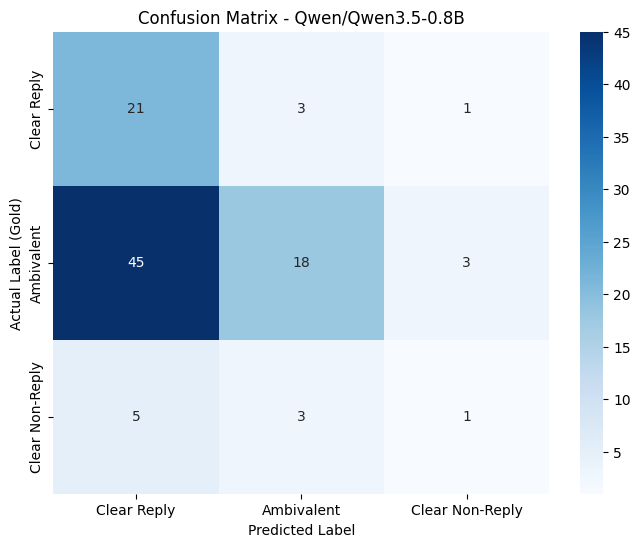

,Accuracy,Precision,Recall,F1-Score,Macro F1-Score,Confusion_Matrix,Labels,Inference_Time_Sec,Sec_per_Sample
Qwen/Qwen3.5-0.8B,0.4,0.586944,0.4,0.386232,0.326786,"[[21, 3, 1], [45, 18, 3], [5, 3, 1]]","[Clear Reply, Ambivalent, Clear Non-Reply]",234.3,2.343


Loading model and tokenizer for: Qwen/Qwen3.5-2B


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Preparing prompts for 100 examples...
--------full_text:--------
<|im_start|>system
You are an expert political discourse analyst. Your task is to fairly classify political Q&A.

CLASSIFICATION RULES:
1. Clear Reply: The specific requested info (fact, yes/no, commitment) is explicitly present.
   *FAIRNESS RULE*: Do not penalize long answers! If the requested fact is buried inside a long, polite, or spinning response, it is STILL a Clear Reply.
2. Ambivalent: The politician discusses the topic, but the specific requested info is MISSING.
   *INDICATORS*: Uses hedging ("I think", "we hope", "working on it"), provides general background instead of the specific fact, or answers a slightly different question.
3. Clear Non-Reply: Completely dodges the question, pivots to an unrelated topic, attacks, or explicitly refuses ("I can't answer that").

CHAIN OF THOUGHT PROTOCOL:
You MUST format your output exactly as follows:
Reasoning: [1. What is the exact info requested? 2. Is that exact info 

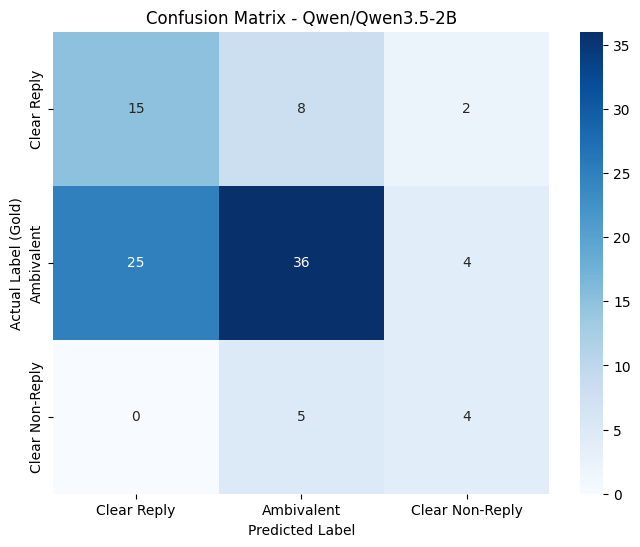

,Accuracy,Precision,Recall,F1-Score,Macro F1-Score,Confusion_Matrix,Labels,Inference_Time_Sec,Sec_per_Sample
Qwen/Qwen3.5-0.8B,0.4,0.586944,0.4,0.386232,0.326786,"[[21, 3, 1], [45, 18, 3], [5, 3, 1]]","[Clear Reply, Ambivalent, Clear Non-Reply]",234.3,2.343
Qwen/Qwen3.5-2B,0.55,0.614648,0.55,0.566497,0.502893,"[[15, 8, 2], [25, 36, 4], [0, 5, 4]]","[Clear Reply, Ambivalent, Clear Non-Reply]",541.4,5.414


Loading model and tokenizer for: Qwen/Qwen3.5-4B


Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/426 [00:00<?, ?it/s]

Preparing prompts for 100 examples...
--------full_text:--------
<|im_start|>system
You are a political discourse analyst. Classify a politician's answer into EXACTLY ONE of:
- Clear Reply
- Ambivalent
- Clear Non-Reply

REAL DISTRIBUTION:
- Ambivalent:       66%  <- default when unsure
- Clear Reply:      25%  <- common, do not suppress
- Clear Non-Reply:   9%  <- very rare, use conservatively

STEP 1 — Check for Clear Non-Reply:
Does the answer fail to mention the topic of the question at all?
Does the politician say almost nothing, or redirect entirely to a different subject?
Only if clearly YES -> Clear Non-Reply (~9% — be very conservative)
HARD RULE: If the politician mentions the topic even once -> NOT Clear Non-Reply.
Short answers are NOT automatically Clear Non-Reply.

STEP 2 — Distinguish Clear Reply from Ambivalent:
Ask: does the answer contain a SPECIFIC direct response to the exact question?

Clear Reply signals — ANY ONE is enough:
  * States a direct yes or no to the ex

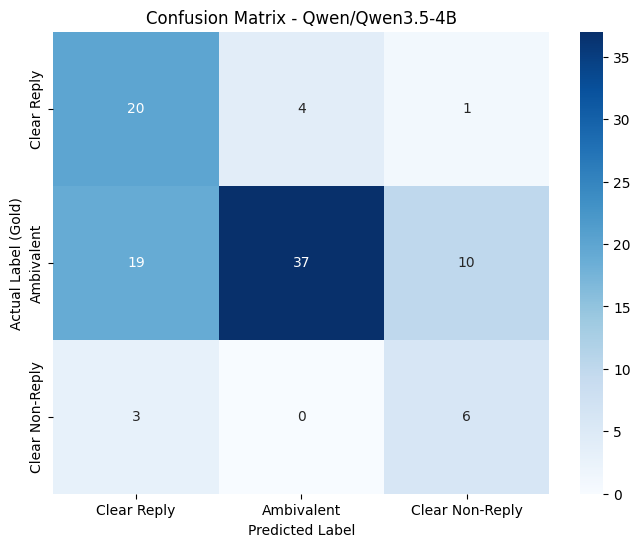

,Accuracy,Precision,Recall,F1-Score,Macro F1-Score,Confusion_Matrix,Labels,Inference_Time_Sec,Sec_per_Sample
Qwen/Qwen3.5-0.8B,0.4,0.586944,0.4,0.386232,0.326786,"[[21, 3, 1], [45, 18, 3], [5, 3, 1]]","[Clear Reply, Ambivalent, Clear Non-Reply]",234.3,2.343
Qwen/Qwen3.5-2B,0.55,0.614648,0.55,0.566497,0.502893,"[[15, 8, 2], [25, 36, 4], [0, 5, 4]]","[Clear Reply, Ambivalent, Clear Non-Reply]",541.4,5.414
Qwen/Qwen3.5-4B,0.63,0.746422,0.63,0.647241,0.583381,"[[20, 4, 1], [19, 37, 10], [3, 0, 6]]","[Clear Reply, Ambivalent, Clear Non-Reply]",1340.0,13.4


In [31]:
# model_names = ["Qwen/Qwen3.5-0.8B", "Qwen/Qwen3.5-2B", "Qwen/Qwen3.5-4B"] 
# all_metrics = {}

# for name in model_names:
#     gc.collect()
#     torch.cuda.empty_cache()
#     bnb_config = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.bfloat16, bnb_4bit_use_double_quant=True,)
#     print(f"Loading model and tokenizer for: {name}")

#     tokenizer = AutoTokenizer.from_pretrained(name)
#     tokenizer.padding_side = "left"
#     if tokenizer.pad_token is None:
#         tokenizer.pad_token = tokenizer.eos_token
#     model = AutoModelForCausalLM.from_pretrained(name, quantization_config=bnb_config, device_map="auto", trust_remote_code=True)

#     if torch.cuda.is_available():
#         torch.cuda.synchronize()
#     start_time = time.time()

#     if name == "Qwen/Qwen3.5-0.8B":
#         p_type = "few-shot-COT-0.8b"
#         max_t = 200
#     elif name == "Qwen/Qwen3.5-2B":
#         p_type = "COT-2b"
#         max_t = 200
#     elif name == "Qwen/Qwen3.5-4B":
#         p_type = "COT-4b"
#         max_t = 200

#     results = run_exp2_COT(model, tokenizer, stratified_subset, prompt_type=p_type, max_tokens=max_t, sample=False, batch_size=8)

#     if torch.cuda.is_available():
#         torch.cuda.synchronize()
#     end_time = time.time()
#     elapsed_time = end_time - start_time

#     metrics = calculate_metrics(results)
#     metrics['Inference_Time_Sec'] = round(elapsed_time, 2)
#     metrics['Sec_per_Sample'] = round(elapsed_time / num_samples, 4)
#     all_metrics[name] = metrics

#     print(f"Model {name} finished in {elapsed_time:.2f}s")
#     plot_confusion_matrix(results, model_name=name)

#     del model
#     del tokenizer
#     gc.collect()
#     torch.cuda.empty_cache()
#     time.sleep(2)

#     # submission_df = create_submission_csv(results, stratified_subset, name, p_type)

#     df_comparison = pd.DataFrame(all_metrics).T
#     display(df_comparison)